# Deep Learning-Based Traffic Sign Classification on the GTSRB Dataset
## A Comparative Study of CNN, ResNet50, EfficientNet-B0, and ConvNeXt-Tiny

Notebook thực nghiệm đầy đủ cho bài toán **phân loại 43 lớp biển báo giao thông GTSRB**. Có 10 cấu hình chính: CNN Scratch; ResNet50 Scratch/TL/FT; EfficientNet-B0 Scratch/TL/FT; ConvNeXt-Tiny Scratch/TL/FT.

**Quy trình khuyến nghị:** (1) chạy một seed chính `SEED=42` cho 10 cấu hình; (2) xem bảng Validation và chi phí; (3) chọn một nhóm mô hình để chạy thêm seed 17 và 123; (4) chỉ đánh giá official Test sau khi đã chốt quy trình lựa chọn bằng Validation.

> Lưu ý: notebook yêu cầu dataset GTSRB có `Train.csv`, `Test.csv`, `Meta.csv`, thư mục `Train/` và `Test/`. Cần bật GPU trong Kaggle. Trọng số pretrained có thể cần được cung cấp/cached trong môi trường Kaggle nếu Internet bị tắt.


## ⚙️ Quy trình chạy 3 lượt (đọc trước khi chạy)

Mọi cell vẫn chạy bằng **Restart kernel → Run all**. Mô hình đã train xong được nạp lại từ `*_done.json` + `*_best.pt` (`SKIP_IF_DONE=True`) nên các lượt sau **không train lại** nếu cấu hình không đổi.

| Lượt | Cờ cần đặt (ô cấu hình) | Kết quả |
|---|---|---|
| **1** | mặc định: `RUN_FINAL_TEST=False`, `RUN_COMPONENT_ABLATION=False`, `RUN_MULTI_SEED_SUITE=False` | 10 mô hình seed 42, bảng Validation, A1, robustness, Grad-CAM. **Không chạm Test.** |
| **2** | `RUN_COMPONENT_ABLATION=True`, `RUN_MULTI_SEED_SUITE=True` + điền `SELECTED_MULTI_SEED_MODELS` | A2, multi-seed; `final_model_name` được chốt theo Validation mean qua seed |
| **3** | `RUN_FINAL_TEST=True` | Test một lần, bootstrap/McNemar, calibration |

- Sang **phiên Kaggle mới**: lưu output thành dataset, đặt `RESTORE_FROM = Path("/kaggle/input/<tên>")`.
- Đổi seed/lr/batch/img size/epochs ⇒ chữ ký khác ⇒ tự train lại mô hình đó.
- Cần bật **Internet** (hoặc cache weights) cho pretrained; ô *Preflight 2* sẽ kiểm tra trước khi train.
- Tên file `e7_*`, `E7_*_seed*` của A2 giữ nguyên để không phá tham chiếu giữa các cell.


## Trạng thái phiên bản và quy trình chạy theo giai đoạn

- **Giai đoạn A (mặc định):** chạy 10 cấu hình chính với seed 42.
- **Giai đoạn B (mặc định tắt):** chạy nhiều seed có chọn lọc sau khi xem kết quả giai đoạn A. Chỉnh `RUN_MULTI_SEED_SUITE=True` và điền `SELECTED_MULTI_SEED_MODELS` ở cell cấu hình.
- **Giai đoạn C:** các thí nghiệm bổ sung về kích thước ảnh/batch size, augmentation, robustness, calibration, bootstrap và Grad-CAM. Một số phần này tốn thêm thời gian; chỉ bật khi cần.
- Validation dùng để chọn mô hình. Official Test chỉ dùng ở giai đoạn đánh giá cuối, không dùng để chọn/tinh chỉnh mô hình.

Notebook đã được kiểm tra cú pháp tĩnh; cần chạy trên Kaggle để xác nhận dataset, GPU và pretrained weights trong môi trường thực tế.


## 0. Câu hỏi nghiên cứu và thiết kế thực nghiệm

Phần này định hướng cả báo cáo tiêu chuẩn và paper. Báo cáo tiêu chuẩn trình bày đầy đủ quy trình; paper tập trung vào các câu hỏi có thể trả lời trực tiếp bằng những thí nghiệm đã triển khai trong notebook.

### Câu hỏi nghiên cứu (Research Questions)

- **RQ1 — Kiến trúc và khởi tạo:** với cùng dữ liệu và protocol, CNN, ResNet50, EfficientNet-B0 và ConvNeXt-Tiny khác nhau thế nào khi huấn luyện Scratch? Pretrained có đem lại lợi ích so với khởi tạo ngẫu nhiên cho cùng một backbone không?
- **RQ2 — Scratch vs. Transfer Learning vs. Fine-tuning:** với từng backbone ResNet50/EfficientNet-B0/ConvNeXt-Tiny, Scratch, TL và FT khác nhau thế nào về Macro-F1, hội tụ, độ ổn định, thời gian và số tham số cập nhật? FT có tốt hơn TL đủ để bù chi phí không?
- **RQ3 — Accuracy–robustness–efficiency trade-off:** mô hình nào cân bằng tốt giữa chất lượng phân loại trên ảnh sạch, mức suy giảm khi ảnh bị giảm sáng/giảm tương phản/blur và chi phí suy luận?
- **RQ4 — Augmentation:** augmentation đang dùng ảnh hưởng thế nào đến Validation Macro-F1 và khả năng chịu các biến đổi ảnh tổng hợp?
- **RQ5 — Lỗi và độ tin cậy:** những lớp nào thường bị nhầm; chất lượng xác suất dự đoán và selective prediction của mô hình được chọn ra sao?

### Giả thuyết cần kiểm chứng

- **H1:** Với cùng backbone, pretrained TL có thể hội tụ nhanh hơn và/hoặc đạt Macro-F1 cao hơn Scratch; đây là giả thuyết cần kiểm chứng, không phải kết luận trước.
- **H2:** Fine-tuning có thể cải thiện chất lượng so với Transfer Learning, song có thể làm tăng thời gian huấn luyện và nguy cơ overfitting.
- **H3:** mô hình đạt điểm cao nhất trên ảnh sạch không nhất thiết có robustness hoặc latency tốt nhất.
- **H4:** augmentation vừa phải có thể cải thiện khả năng tổng quát hóa; augmentation quá mạnh có thể làm mất dấu hiệu phân biệt giữa các lớp.

Các giả thuyết trên là câu hỏi cần kiểm chứng, **không phải kết luận được giả định trước**.

### Ma trận thí nghiệm

| Mã | Thí nghiệm | Vai trò trong nghiên cứu |
|---|---|---|
| E1 | CNN Scratch | Baseline CNN huấn luyện từ đầu |
| E2–E3 | ResNet50-TL / ResNet50-FT | So sánh pretrained classifier-only với fine-tuning |
| E4–E5 | EfficientNet-B0-TL / EfficientNet-B0-FT | Như trên cho EfficientNet-B0 |
| E6 | ResNet50 Scratch | Đối chứng không dùng trọng số ImageNet |
| E7 | EfficientNet-B0 Scratch | Đối chứng không dùng trọng số ImageNet |
| E8 | ConvNeXt-Tiny Scratch | Đối chứng không dùng trọng số ImageNet |
| E9–E10 | ConvNeXt-Tiny-TL / ConvNeXt-Tiny-FT | So sánh TL với FT |
| A1 | CNN augmentation on/off | Ablation bật/tắt toàn bộ augmentation (mục 20) |
| A2 | Ablation từng thành phần augmentation | Bật bằng `RUN_COMPONENT_ABLATION` (mục 21.1) |
| D1 | Multi-seed (mục 20.1, 28.1) | Biến thiên theo seed, chỉ Validation |
| D2 | Robustness severity sweep | Giảm sáng/tương phản/blur trên Validation |
| D3 | Error analysis + Grad-CAM | Lớp khó, cặp nhầm lẫn, vùng kích hoạt |
| D4 | Efficiency benchmark | Tham số, dung lượng, latency, throughput |
| D5 | Bootstrap CI + McNemar | Chỉ chạy khi `RUN_FINAL_TEST=True` |
| D6 | Calibration/selective prediction | Chỉ chạy khi `RUN_FINAL_TEST=True` |

**Quy tắc công bằng:** sử dụng cùng split và quy trình input cho các so sánh chính; chọn checkpoint bằng Validation Macro-F1. Mọi thay đổi tham số phải được quyết định bằng Train/Validation, ghi lại trong cấu hình; không điều chỉnh mô hình sau khi xem kết quả Test.
### Các lớp so sánh bắt buộc để diễn giải sâu

1. **Hiệu ứng khởi tạo/pretraining theo cùng kiến trúc:** ResNet50-Scratch ↔ ResNet50-TL; EfficientNet-B0-Scratch ↔ EfficientNet-B0-TL.
2. **Hiệu ứng fine-tuning:** ResNet50-TL ↔ ResNet50-FT; EfficientNet-B0-TL ↔ EfficientNet-B0-FT.
3. **So sánh kiến trúc khi Scratch:** CNN ↔ ResNet50-Scratch ↔ EfficientNet-B0-Scratch.
4. **So sánh backbone khi dùng pretrained:** ResNet50-TL ↔ EfficientNet-B0-TL và ResNet50-FT ↔ EfficientNet-B0-FT.
5. **Trade-off thực tế:** Macro-F1/Accuracy so với thời gian huấn luyện, số tham số trainable, dung lượng checkpoint, latency batch=1 và throughput.
6. **Độ ổn định và tổng quát hóa:** learning curves, train–validation gap, nhiều seed, confusion matrix theo lớp, robustness theo severity, calibration và selective prediction.

Để diễn giải công bằng, Scratch và TL/FT phải dùng cùng split, preprocessing, augmentation và tiêu chí chọn checkpoint. Tuy nhiên, Scratch cần nhiều epoch hơn để hội tụ; báo cáo cả thời gian thực tế và best epoch, không ép tổng số epoch bằng nhau nếu mục tiêu là so sánh hiệu quả thực dụng. Nếu muốn tách riêng tác động của thời lượng huấn luyện, hãy bổ sung thí nghiệm ngân sách epoch/thời gian cố định.


In [2]:
# Kiểm tra môi trường Kaggle.
# Không cài package qua mạng ở đây để tránh phụ thuộc Internet; các thư viện dưới đây thường có sẵn trong Kaggle.
# Lưu ý: torchvision pretrained weights cần được cache sẵn hoặc bật Internet trong Kaggle khi chạy lần đầu.

import os, sys, json, time, random, math, copy, shutil, hashlib
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, f1_score, log_loss
)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", __import__("torchvision").__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
CUDA available: True
GPU: Tesla T4


## 1. Cấu hình chung và quy tắc chọn mô hình

Các giá trị trong cell cấu hình là **điểm khởi đầu cho thí nghiệm**, không được xem là tham số tối ưu đã được chứng minh. Ghi nhận input size, batch size, optimizer, learning rate, weight decay, scheduler, số epoch tối đa, seed và phiên bản thư viện trong cấu hình kết quả.

Checkpoint của từng giai đoạn được chọn theo **Validation Macro-F1**. Không chọn mô hình chỉ dựa trên Accuracy vì dataset có nhiều lớp và mức độ khó giữa các lớp có thể khác nhau. Nếu điều chỉnh siêu tham số, chỉ dùng Train/Validation và giữ Test độc lập.

### Quy tắc vận hành đã khóa
- Chạy từ **Restart kernel → Run all**; không chạy các cell rời rạc sau khi đổi cấu hình.
- Không thu nhỏ/ghi đè `df`, `train_df`, `val_df`, `test_df` để smoke test. Cell preflight bên dưới dùng batch tạm và không thay đổi split.
- `Validation` dùng chọn checkpoint/cấu hình. `Official Test` chỉ được đánh giá ở mục 28 sau khi quyết định đã chốt; suite đa seed chỉ ghi Validation.
- Khi đổi dữ liệu, seed, augmentation, image size hoặc batch size, dùng thư mục output mới và ghi lại cấu hình.


In [4]:
SEED = 42

# Deterministic mode improves repeatability, although it may reduce training speed.
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Cấu hình chính dùng thống nhất cho 10 cấu hình: CNN/ResNet50/EfficientNet-B0/ConvNeXt-Tiny Scratch, TL và FT.
# 224x224 phù hợp với backbone pretrained ImageNet; mọi mô hình dùng cùng kích thước đầu vào.
IMG_SIZE = 224
USE_AMP = DEVICE.type == "cuda"   # mixed precision (fp16) khi có GPU
NUM_CLASSES = 43
CLASS_LABEL_NAMES = {
    "0": "Speed limit (20 km/h)", "1": "Speed limit (30 km/h)", "2": "Speed limit (50 km/h)",
    "3": "Speed limit (60 km/h)", "4": "Speed limit (70 km/h)", "5": "Speed limit (80 km/h)",
    "6": "End of speed limit (80 km/h)", "7": "Speed limit (100 km/h)", "8": "Speed limit (120 km/h)",
    "9": "No passing", "10": "No passing for vehicles over 3.5 t",
    "11": "Right-of-way at next intersection", "12": "Priority road", "13": "Yield", "14": "Stop",
    "15": "No vehicles", "16": "Vehicles over 3.5 t prohibited", "17": "No entry",
    "18": "General caution", "19": "Dangerous curve to the left", "20": "Dangerous curve to the right",
    "21": "Double curve", "22": "Bumpy road", "23": "Slippery road", "24": "Road narrows on the right",
    "25": "Road work", "26": "Traffic signals", "27": "Pedestrians", "28": "Children crossing",
    "29": "Bicycles crossing", "30": "Beware of ice/snow", "31": "Wild animals crossing",
    "32": "End of all speed and passing limits", "33": "Turn right ahead", "34": "Turn left ahead",
    "35": "Ahead only", "36": "Go straight or right", "37": "Go straight or left",
    "38": "Keep right", "39": "Keep left", "40": "Roundabout mandatory",
    "41": "End of no passing", "42": "End of no passing for vehicles over 3.5 t"
}
# Batch size thống nhất cho tất cả mô hình trong cùng một lần chạy.
# Nếu GPU hết bộ nhớ, đổi thành 16 cho TOÀN BỘ mô hình, không đổi riêng từng mô hình.
BATCH_SIZE = 32

# Epoch counts are upper limits; Early Stopping may stop training sooner.
EPOCHS_CNN = 80
EPOCHS_SCRATCH_BACKBONE = 120  # Scratch cần thêm thời gian để học toàn bộ đặc trưng từ đầu
EPOCHS_TL = 30
EPOCHS_FT = 25
EARLY_STOP_PATIENCE = 8
MIN_DELTA = 1e-4

NUM_WORKERS = min(4, os.cpu_count() or 2)
PIN_MEMORY = DEVICE.type == "cuda"

LR_CNN = 1e-3
LR_SCRATCH_BACKBONE = 3e-4  # learning rate khởi đầu bảo thủ cho backbone sâu khởi tạo ngẫu nhiên
LR_HEAD = 1e-3
LR_BACKBONE_FINE = 1e-5
LR_HEAD_FINE = 1e-4
WEIGHT_DECAY = 1e-4

# Validation tách từ Train.csv THEO NHÓM (track) bằng StratifiedGroupKFold; Test.csv giữ nguyên.
# Lớp nhỏ nhất chỉ có 7 track nên dùng 7 fold (validation ≈ 1/7 ≈ 14%).
GROUP_SPLIT_FOLDS = 7

# Thí nghiệm nhiều seed mặc định TẮT để tiết kiệm GPU ở lượt chạy đầu.
# Sau khi xem bảng Validation, bật True và chọn model bên dưới.
RUN_MULTI_SEED_SUITE = False
SUITE_SEEDS = [17, 123]
# Tên model hợp lệ: CNN, ResNet50-Scratch, ResNet50-TL, ResNet50-FT,
# EfficientNet-B0-Scratch, EfficientNet-B0-TL, EfficientNet-B0-FT,
# ConvNeXt-Tiny-Scratch, ConvNeXt-Tiny-TL, ConvNeXt-Tiny-FT.
# Để so sánh TL vs FT, hãy chọn cả hai tên tương ứng. FT sẽ tự chạy TL làm checkpoint khởi đầu.
SELECTED_MULTI_SEED_MODELS = []  # Ví dụ sau lượt đầu: ["ResNet50-TL", "ResNet50-FT"]
# Ablation augmentation cho CNN; thêm seed vào danh sách để chạy nhiều lần.
ABLATION_SEEDS = [42]
# Ablation TỪNG thành phần augmentation (A2) = 4 lần train CNN thêm. Lượt 1 để False; bật ở lượt 2.
# Khi False vẫn chạy A1 (full vs none) dùng lại E1 và CNN-NoAug, không train thêm.
RUN_COMPONENT_ABLATION = False

# Thí nghiệm phụ (mặc định tắt) để tách riêng ảnh hưởng của image size và batch size.
# Main: 224px / batch 32. Mỗi profile phụ vẫn áp dụng đồng nhất cho cả 10 cấu hình mô hình.
# B chỉ đổi image size; C/D chỉ đổi batch size. Bật RUN_PROFILE_COMPARISON nếu có đủ thời gian GPU.
RUN_PROFILE_COMPARISON = False
COMPARISON_PROFILES = {
    "B_128px_bs32": dict(img_size=128, batch_size=32),  # chỉ đổi image size
    "C_224px_bs16": dict(img_size=224, batch_size=16),  # chỉ đổi batch size
    "D_224px_bs64": dict(img_size=224, batch_size=64),  # chỉ đổi batch size
}
COMPARISON_SEEDS = [42]

OUTPUT_DIR = Path("/kaggle/working/gtsrb_results_staged_10models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Đặt True nếu *_last.pt của các thí nghiệm còn trong OUTPUT_DIR và muốn tiếp tục train.
# Nếu phiên Kaggle đã bị xóa working directory, cần khôi phục/tải checkpoint trước.
RESUME_FROM_LAST = False

# ---- Điều khiển quy trình nhiều lượt (xem ô hướng dẫn ở đầu notebook) ----
# True: chỉ bật ở LƯỢT CUỐI, sau khi đã chốt mô hình bằng Validation. False: không chạm official Test.
RUN_FINAL_TEST = False
# True: mô hình nào đã có {name}_done.json + _best.pt khớp cấu hình thì nạp lại, KHÔNG train lại.
SKIP_IF_DONE = True
# Phiên Kaggle mới: lưu output phiên trước thành dataset rồi đặt đường dẫn vào đây để khôi phục.
RESTORE_FROM = None   # ví dụ: Path("/kaggle/input/ten-output-phien-truoc")
if RESTORE_FROM is not None:
    _src = Path(RESTORE_FROM)
    if (_src / OUTPUT_DIR.name).is_dir():
        _src = _src / OUTPUT_DIR.name
    shutil.copytree(_src, OUTPUT_DIR, dirs_exist_ok=True)
    print("Đã khôi phục output từ:", _src)

print("DEVICE:", DEVICE)
print("BATCH_SIZE:", BATCH_SIZE)
print("RUN_MULTI_SEED_SUITE:", RUN_MULTI_SEED_SUITE)
print("SELECTED_MULTI_SEED_MODELS:", SELECTED_MULTI_SEED_MODELS)
print("RESUME_FROM_LAST:", RESUME_FROM_LAST)
print("RUN_FINAL_TEST:", RUN_FINAL_TEST, "| SKIP_IF_DONE:", SKIP_IF_DONE, "| RUN_COMPONENT_ABLATION:", RUN_COMPONENT_ABLATION)
print("Output:", OUTPUT_DIR)
print("Deterministic cuDNN:", torch.backends.cudnn.deterministic)


DEVICE: cuda
BATCH_SIZE: 32
RUN_MULTI_SEED_SUITE: False
SELECTED_MULTI_SEED_MODELS: []
RESUME_FROM_LAST: False
RUN_FINAL_TEST: False | SKIP_IF_DONE: True | RUN_COMPONENT_ABLATION: False
Output: /kaggle/working/gtsrb_results_staged_10models
Deterministic cuDNN: True


## 2. Xác định dataset trên Kaggle Input

Notebook mong đợi cấu trúc GTSRB gồm `Train.csv`, `Test.csv`, `Meta.csv` và các thư mục ảnh `Train/`, `Test/`, `Meta/`. Cell dò dữ liệu tìm thư mục gốc chứa bộ file này; nếu có nhiều bản dataset, hãy chỉ định `GTSRB_DATA_ROOT` rõ ràng.

- `Train.csv`: dữ liệu có nhãn để tạo Train/Validation.
- `Test.csv`: tập test chính thức; không gộp vào Train và không chia lại ngẫu nhiên.
- `Meta.csv`: thông tin mô tả/mapping lớp, dùng cho bước kiểm tra dữ liệu.

Dữ liệu trong `/kaggle/input/` chỉ đọc. Các bảng, biểu đồ và checkpoint được ghi vào `/kaggle/working/gtsrb_results/`.

In [7]:
# ============================================================
# TỰ TÌM DATASET BUNDLE: Train.csv + Test.csv + Meta.csv
# ============================================================
KAGGLE_INPUT = Path("/kaggle/input")
if not KAGGLE_INPUT.exists():
    raise EnvironmentError("Không tìm thấy /kaggle/input. Hãy chạy notebook trên Kaggle hoặc sửa KAGGLE_INPUT để kiểm thử.")


def child_path(parent, name, want_dir=None):
    """Tìm file/thư mục con không phân biệt chữ hoa-thường."""
    if not Path(parent).exists():
        return None
    for item in Path(parent).iterdir():
        if item.name.lower() == name.lower():
            if want_dir is None or item.is_dir() == want_dir:
                return item
    return None


def has_gtsrb_csv_bundle(root):
    return all([
        child_path(root, "Train.csv", want_dir=False),
        child_path(root, "Test.csv", want_dir=False),
        child_path(root, "Meta.csv", want_dir=False),
        child_path(root, "Train", want_dir=True),
        child_path(root, "Test", want_dir=True),
    ])

# Tìm các thư mục gốc chứa đầy đủ bundle; không mặc định lấy candidates[0].
candidates = []
_IMAGE_DIRS = {"train", "test", "meta"}   # không đi vào thư mục ảnh (hàng chục nghìn file)
for _dirpath, _dirnames, _filenames in os.walk(KAGGLE_INPUT):
    _depth = len(Path(_dirpath).relative_to(KAGGLE_INPUT).parts)
    _dirnames[:] = [d for d in _dirnames if d.lower() not in _IMAGE_DIRS] if _depth < 5 else []
    if any(f.lower() == "train.csv" for f in _filenames) and has_gtsrb_csv_bundle(Path(_dirpath)):
        candidates.append(Path(_dirpath))
candidates = list(dict.fromkeys(candidates))

print("Các dataset bundle phù hợp:")
for p in candidates:
    print(" -", p)

GTSRB_DATA_ROOT = None  # Nếu có nhiều bản: Path('/kaggle/input/ten-dataset')
if GTSRB_DATA_ROOT is not None:
    DATA_ROOT = Path(GTSRB_DATA_ROOT)
    if not has_gtsrb_csv_bundle(DATA_ROOT):
        raise FileNotFoundError(f"DATA_ROOT không chứa đủ Train.csv/Test.csv/Meta.csv và Train/Test folders: {DATA_ROOT}")
elif len(candidates) == 1:
    DATA_ROOT = candidates[0]
elif len(candidates) == 0:
    raise FileNotFoundError(
        "Không tìm thấy bộ GTSRB có đủ Train.csv, Test.csv, Meta.csv, Train/ và Test/. "
        "Hãy chắc chắn đã Add đúng dataset vào Kaggle Input."
    )
else:
    raise RuntimeError(
        "Có nhiều bộ GTSRB hợp lệ. Hãy đặt GTSRB_DATA_ROOT thành đường dẫn của dataset muốn dùng."
    )

TRAIN_DIR = child_path(DATA_ROOT, "Train", want_dir=True)
TEST_DIR = child_path(DATA_ROOT, "Test", want_dir=True)
META_DIR = child_path(DATA_ROOT, "Meta", want_dir=True)
TRAIN_CSV = child_path(DATA_ROOT, "Train.csv", want_dir=False)
TEST_CSV = child_path(DATA_ROOT, "Test.csv", want_dir=False)
META_CSV = child_path(DATA_ROOT, "Meta.csv", want_dir=False)

print("\nDATA_ROOT:", DATA_ROOT)
print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR: ", TEST_DIR)
print("META_DIR: ", META_DIR)
print("TRAIN_CSV:", TRAIN_CSV)
print("TEST_CSV: ", TEST_CSV)
print("META_CSV: ", META_CSV)
print("Input chỉ đọc; không download/copy toàn bộ ảnh sang working directory.")


Các dataset bundle phù hợp:
 - /kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign

DATA_ROOT: /kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
TRAIN_DIR: /kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Train
TEST_DIR:  /kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Test
META_DIR:  /kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Meta
TRAIN_CSV: /kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Train.csv
TEST_CSV:  /kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Test.csv
META_CSV:  /kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Meta.csv
Input chỉ đọc; không download/copy toàn bộ ảnh sang working directory.


## 3. Kiểm tra CSV và mapping ảnh–nhãn

Bước kiểm tra xác minh schema của `Train.csv`, `Test.csv`, `Meta.csv`, miền nhãn 0–42, đường dẫn ảnh, khả năng khớp nhãn với cấu trúc thư mục khi có thể và thông tin metadata. Các ảnh được mở để phát hiện file không đọc được và đối chiếu kích thước thực tế.

Nếu thiếu cột bắt buộc, nhãn nằm ngoài miền hoặc có đường dẫn không hợp lệ, cần xử lý nguyên nhân trước khi huấn luyện; không tiếp tục bằng cách âm thầm bỏ qua lỗi dữ liệu.

In [9]:
def normalize_column_name(value):
    return "".join(ch.lower() for ch in str(value) if ch.isalnum())


def find_column(frame, candidates, required=True, description="column"):
    by_normalized = {normalize_column_name(col): col for col in frame.columns}
    for candidate in candidates:
        key = normalize_column_name(candidate)
        if key in by_normalized:
            return by_normalized[key]
    if required:
        raise ValueError(
            f"Không tìm thấy {description}. Các cột hiện có: {list(frame.columns)}; "
            f"các tên được chấp nhận: {candidates}"
        )
    return None


def resolve_image_path(raw_value, split_dir, root):
    """Resolve Path từ CSV cho cả dạng Train/0/a.png, 0/a.png, hoặc a.png."""
    raw = str(raw_value).strip().replace("\\", "/")
    if not raw or raw.lower() in {"nan", "none"}:
        return None
    raw_path = Path(raw)
    candidates_local = []
    if raw_path.is_absolute():
        candidates_local.append(raw_path)
    else:
        candidates_local.append(Path(root) / raw_path)
        parts = list(raw_path.parts)
        # Hỗ trợ CSV dùng tên thư mục khác chữ hoa/thường.
        for i, part in enumerate(parts):
            if part.lower() == Path(split_dir).name.lower():
                candidates_local.append(Path(split_dir).joinpath(*parts[i + 1:]))
                break
        candidates_local.append(Path(split_dir) / raw_path)
        candidates_local.append(Path(split_dir) / raw_path.name)
    seen = set()
    for candidate in candidates_local:
        key = str(candidate)
        if key in seen:
            continue
        seen.add(key)
        if candidate.is_file():
            return str(candidate.resolve())
    return None


def load_split_manifest(csv_path, split_dir, root, split_name):
    raw = pd.read_csv(csv_path)
    path_col = find_column(
        raw, ["Path", "filepath", "file_path", "filename", "file", "image", "image_path"],
        description=f"cột đường dẫn ảnh trong {csv_path.name}"
    )
    label_col = find_column(
        raw, ["ClassId", "class_id", "label", "target", "class"],
        description=f"cột nhãn trong {csv_path.name}"
    )
    numeric_labels = pd.to_numeric(raw[label_col], errors="coerce")
    if numeric_labels.isna().any() or not np.equal(numeric_labels, np.floor(numeric_labels)).all():
        bad = raw.loc[numeric_labels.isna() | (numeric_labels.fillna(0) != np.floor(numeric_labels.fillna(0))), label_col].head(10).tolist()
        raise ValueError(f"{csv_path.name} chứa ClassId không hợp lệ. Một số giá trị: {bad}")

    resolved_paths, unresolved = [], []
    for raw_path in raw[path_col].tolist():
        resolved = resolve_image_path(raw_path, split_dir, root)
        resolved_paths.append(resolved)
        if resolved is None:
            unresolved.append(str(raw_path))
    if unresolved:
        raise FileNotFoundError(
            f"{split_name}: {len(unresolved)} đường dẫn ảnh không tìm thấy trong thư mục dataset. "
            f"Ví dụ: {unresolved[:10]}"
        )

    result = pd.DataFrame({
        "path": resolved_paths,
        "label": numeric_labels.astype(int).to_numpy(),
        "path_in_csv": raw[path_col].astype(str).to_numpy(),
    })
    width_col = find_column(raw, ["Width"], required=False)
    height_col = find_column(raw, ["Height"], required=False)
    if width_col is not None:
        result["csv_width"] = pd.to_numeric(raw[width_col], errors="coerce").to_numpy()
    if height_col is not None:
        result["csv_height"] = pd.to_numeric(raw[height_col], errors="coerce").to_numpy()

    if result["path"].duplicated().any():
        duplicated = result.loc[result["path"].duplicated(keep=False), ["path", "label"]].head(20)
        display(duplicated)
        raise ValueError(f"{split_name}: CSV khai báo đường dẫn ảnh trùng lặp. Hãy kiểm tra dữ liệu.")
    invalid_labels = ~result["label"].between(0, NUM_CLASSES - 1)
    if invalid_labels.any():
        bad_values = sorted(result.loc[invalid_labels, "label"].unique().tolist())
        raise ValueError(f"{split_name}: nhãn ngoài miền 0..{NUM_CLASSES-1}: {bad_values}")
    return result, raw


train_manifest, train_csv_raw = load_split_manifest(TRAIN_CSV, TRAIN_DIR, DATA_ROOT, "Train.csv")
test_manifest, test_csv_raw = load_split_manifest(TEST_CSV, TEST_DIR, DATA_ROOT, "Test.csv")
meta_df = pd.read_csv(META_CSV)

expected_classes = set(range(NUM_CLASSES))
train_classes = set(train_manifest["label"].unique().tolist())
test_classes = set(test_manifest["label"].unique().tolist())
if train_classes != expected_classes:
    raise ValueError(
        f"Train.csv không chứa đủ 43 class. Thiếu: {sorted(expected_classes-train_classes)}; "
        f"nhãn ngoài miền: {sorted(train_classes-expected_classes)}"
    )
if train_manifest.empty or test_manifest.empty:
    raise ValueError("Train.csv hoặc Test.csv không có mẫu nào.")

meta_class_col = find_column(meta_df, ["ClassId", "class_id", "label", "target"], required=False)
meta_class_ids = set()
if meta_class_col is not None:
    meta_labels = pd.to_numeric(meta_df[meta_class_col], errors="coerce").dropna().astype(int)
    meta_class_ids = set(meta_labels.tolist())
    if meta_class_ids and meta_class_ids != expected_classes:
        print("CẢNH BÁO: Meta.csv không ánh xạ đủ đúng 43 ClassId.")
else:
    print("CẢNH BÁO: Không nhận diện được cột ClassId trong Meta.csv; sẽ hiển thị metadata để kiểm tra thủ công.")

# Nếu Path chỉ đến ảnh trong Train/<class_id>/..., xác minh class thư mục và ClassId có trùng nhau.
folder_label_mismatches = []
for row in train_manifest[["path", "label"]].itertuples(index=False):
    image_path = Path(row.path)
    try:
        relative = image_path.relative_to(TRAIN_DIR.resolve())
        if len(relative.parts) >= 2 and relative.parts[0].isdigit():
            folder_label = int(relative.parts[0])
            if folder_label != int(row.label):
                folder_label_mismatches.append((str(image_path), folder_label, int(row.label)))
    except ValueError:
        pass
if folder_label_mismatches:
    display(pd.DataFrame(folder_label_mismatches, columns=["path", "folder_label", "csv_label"]).head(20))
    raise ValueError(f"Phát hiện {len(folder_label_mismatches)} ảnh có ClassId trong CSV khác class folder.")

print("===== CSV / DATASET SANITY CHECK =====")
print(f"Train.csv: {len(train_manifest):,} rows | {train_manifest['label'].nunique()} classes | {train_manifest['path'].nunique():,} unique paths")
print(f"Test.csv:  {len(test_manifest):,} rows | {test_manifest['label'].nunique()} classes | {test_manifest['path'].nunique():,} unique paths")
print(f"Meta.csv:  {len(meta_df):,} rows | columns = {list(meta_df.columns)}")
print("Train.csv columns:", list(train_csv_raw.columns))
print("Test.csv columns: ", list(test_csv_raw.columns))
print("Train classes missing:", sorted(expected_classes - train_classes))
print("Test classes missing (reported, not automatically considered an error):", sorted(expected_classes - test_classes))
print("\nTrain.csv preview:")
display(train_csv_raw.head())
print("\nTest.csv preview:")
display(test_csv_raw.head())
print("\nMeta.csv preview:")
display(meta_df.head(10))

csv_class_counts = pd.DataFrame({
    "train_csv": train_manifest["label"].value_counts().sort_index(),
    "test_csv": test_manifest["label"].value_counts().sort_index(),
}).fillna(0).astype(int)
display(csv_class_counts)
csv_class_counts.to_csv(OUTPUT_DIR / "csv_class_distribution_before_image_audit.csv", index_label="class_id")


===== CSV / DATASET SANITY CHECK =====
Train.csv: 39,209 rows | 43 classes | 39,209 unique paths
Test.csv:  12,630 rows | 43 classes | 12,630 unique paths
Meta.csv:  43 rows | columns = ['Path', 'ClassId', 'ShapeId', 'ColorId', 'SignId']
Train.csv columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']
Test.csv columns:  ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']
Train classes missing: []
Test classes missing (reported, not automatically considered an error): []

Train.csv preview:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png



Test.csv preview:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png



Meta.csv preview:


,Path,ClassId,ShapeId,ColorId,SignId
0,Meta/27.png,27,0,0,1.32
1,Meta/0.png,0,1,0,3.29
2,Meta/1.png,1,1,0,3.29
3,Meta/10.png,10,1,0,3.27
4,Meta/11.png,11,0,0,1.22
5,Meta/12.png,12,2,2,2.3
6,Meta/13.png,13,4,0,2.1
7,Meta/14.png,14,3,0,2.2
8,Meta/15.png,15,1,0,3.1
9,Meta/16.png,16,1,0,3.3


,train_csv,test_csv
label,,
0,210,60
1,2220,720
2,2250,750
3,1410,450
4,1980,660
5,1860,630
6,420,150
7,1440,450
8,1410,450


## 4. EDA — kiểm toán chất lượng ảnh

Duyệt ảnh theo đường dẫn và nhãn trong CSV, không suy nhãn chỉ từ tên thư mục. Kiểm tra ảnh lỗi, kích thước, ảnh trùng pixel chính xác và ảnh trùng giữa Train với Test. Nếu phát hiện ảnh giống hệt xuất hiện ở hai split, bản thuộc Train được loại để tránh leakage trong khi các mẫu của Test gốc vẫn được giữ nguyên.

**Giới hạn:** kiểm tra hash/pixel chính xác không phát hiện mọi ảnh gần trùng. Kết quả audit cần được lưu cùng số lượng mẫu trước và sau xử lý để báo cáo minh bạch.

Audit Train:   0%|          | 0/39209 [00:00<?, ?it/s]

Audit Test:   0%|          | 0/12630 [00:00<?, ?it/s]

Width/Height trong CSV khớp kích thước ảnh giải mã (hoặc CSV không có trường kích thước).
Train exact pixel duplicates removed within Train.csv: 0
Test exact pixel duplicates (reported; official test rows are retained): 0
LEAKAGE GUARD: loại 8 bản Train trùng pixel với Test; giữ nguyên Test gốc.


,Train images after audit
label,
0,210
1,2220
2,2250
3,1410
4,1980
5,1860
6,420
7,1440
8,1410


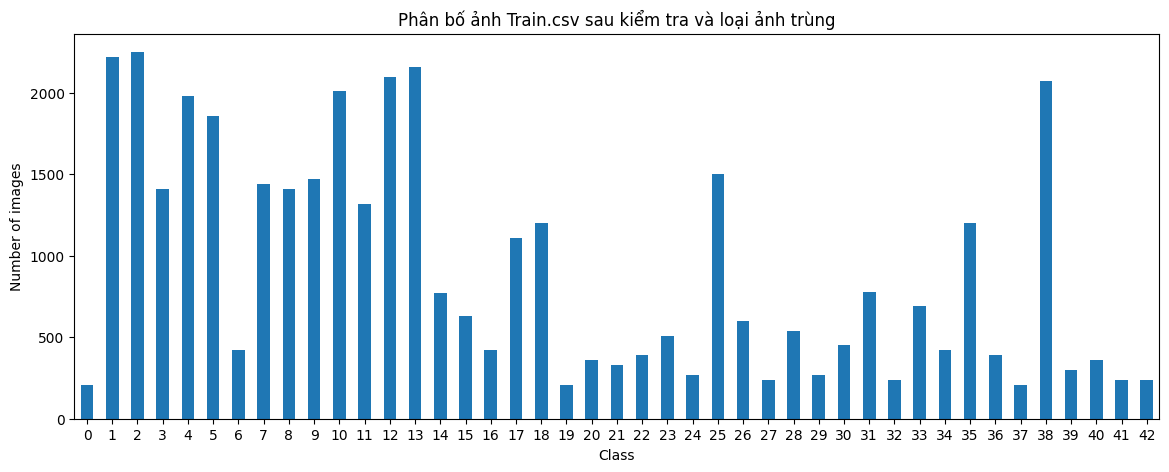

,width,height,aspect
count,39201.000000,39201.000000,39201.000000
mean,50.836968,50.329762,1.007446
std,24.309009,23.117381,0.070831
min,25.000000,25.000000,0.368132
25%,35.000000,35.000000,0.971429
50%,43.000000,43.000000,1.000000
75%,58.000000,58.000000,1.040816
max,243.000000,225.000000,1.417808


Official Test dimensions:


,width,height,aspect
count,12630.000000,12630.000000,12630.000000
mean,50.507759,50.364450,1.000001
std,25.088483,23.698908,0.080555
min,25.000000,25.000000,0.392857
25%,34.000000,35.000000,0.968750
50%,43.000000,43.000000,1.000000
75%,58.000000,57.000000,1.035714
max,266.000000,232.000000,1.437500


Data quality summary: {'train_csv_rows': 39209, 'test_csv_rows': 12630, 'train_unreadable_files': 0, 'test_unreadable_files': 0, 'train_duplicates_removed_within_train': 0, 'test_exact_duplicates_reported_but_retained': 0, 'train_test_exact_pixel_overlap_hashes': 8, 'train_rows_after_audit': 39201, 'official_test_rows_after_audit': 12630, 'train_classes_after_audit': 43, 'test_classes_after_audit': 43, 'duplicate_definition': 'same RGB pixel array and dimensions'}


In [10]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".ppm", ".bmp", ".webp"}


def inspect_manifest_images(manifest, split_name, strict=True):
    records, unreadable = [], []
    for row in tqdm(manifest.itertuples(index=False), total=len(manifest), desc=f"Audit {split_name}"):
        fp = Path(row.path)
        try:
            if fp.suffix.lower() not in IMG_EXTS:
                raise ValueError(f"Định dạng ảnh chưa được hỗ trợ: {fp.suffix}")
            with Image.open(fp) as im:
                rgb = im.convert("RGB")
                width, height = rgb.size
                pixel_hash = hashlib.sha256(
                    f"{width}x{height}:".encode() + rgb.tobytes()
                ).hexdigest()
            records.append({
                "path": str(fp),
                "label": int(row.label),
                "width": int(width),
                "height": int(height),
                "aspect": width / height if height else np.nan,
                "pixel_hash": pixel_hash,
            })
        except Exception as exc:
            unreadable.append((str(fp), str(exc)))
    if unreadable:
        pd.DataFrame(unreadable, columns=["path", "error"]).to_csv(
            OUTPUT_DIR / f"unreadable_{split_name.lower().replace('/', '_')}.csv", index=False
        )
        print(f"{split_name}: có {len(unreadable)} ảnh không đọc được; đã lưu danh sách lỗi.")
        if strict:
            raise RuntimeError(
                f"Có {len(unreadable)} ảnh trong {split_name} không đọc được. "
                "Không tiếp tục để tránh làm thay đổi âm thầm tập Test chính thức."
            )
    return pd.DataFrame(records), unreadable


# Đọc ảnh thật và xác minh tính toàn vẹn, không chỉ kiểm tra file có tồn tại.
df, bad_train_files = inspect_manifest_images(train_manifest, "Train", strict=False)
test_df, bad_test_files = inspect_manifest_images(test_manifest, "Test", strict=True)
if df.empty or test_df.empty:
    raise RuntimeError("Sau bước kiểm tra ảnh, Train hoặc Test không còn mẫu hợp lệ.")

# Đối chiếu Width/Height ghi trong CSV với kích thước giải mã thực tế (nếu CSV có hai cột này).
dimension_mismatch_parts = []
for split_name, manifest, audited in [
    ("Train", train_manifest, df),
    ("Test", test_manifest, test_df),
]:
    if "csv_width" in manifest.columns or "csv_height" in manifest.columns:
        dimension_check = manifest.merge(audited[["path", "width", "height"]], on="path", how="inner")
        mismatch = pd.Series(False, index=dimension_check.index)
        if "csv_width" in dimension_check.columns:
            expected_width = pd.to_numeric(dimension_check["csv_width"], errors="coerce")
            mismatch |= expected_width.notna() & (expected_width.astype("Int64") != dimension_check["width"])
        if "csv_height" in dimension_check.columns:
            expected_height = pd.to_numeric(dimension_check["csv_height"], errors="coerce")
            mismatch |= expected_height.notna() & (expected_height.astype("Int64") != dimension_check["height"])
        if mismatch.any():
            part = dimension_check.loc[mismatch, ["path", "width", "height"]].copy()
            part["split"] = split_name
            if "csv_width" in dimension_check.columns:
                part["csv_width"] = dimension_check.loc[mismatch, "csv_width"].to_numpy()
            if "csv_height" in dimension_check.columns:
                part["csv_height"] = dimension_check.loc[mismatch, "csv_height"].to_numpy()
            dimension_mismatch_parts.append(part)
if dimension_mismatch_parts:
    dimension_mismatch_df = pd.concat(dimension_mismatch_parts, ignore_index=True)
    dimension_mismatch_df.to_csv(OUTPUT_DIR / "csv_vs_decoded_image_dimension_mismatches.csv", index=False)
    print(f"CẢNH BÁO: {len(dimension_mismatch_df)} rows có Width/Height trong CSV khác ảnh giải mã; dùng kích thước ảnh thực tế.")
    display(dimension_mismatch_df.head(20))
else:
    print("Width/Height trong CSV khớp kích thước ảnh giải mã (hoặc CSV không có trường kích thước).")

# Ảnh trùng pixel nhưng nhãn khác nhau là lỗi dữ liệu, không tự sửa nhãn.
for split_name, frame in [("Train", df), ("Test", test_df)]:
    label_counts_by_hash = frame.groupby("pixel_hash")["label"].nunique()
    conflict_hashes = label_counts_by_hash[label_counts_by_hash > 1].index
    if len(conflict_hashes):
        conflict_rows = frame[frame["pixel_hash"].isin(conflict_hashes)][["path", "label", "pixel_hash"]]
        display(conflict_rows.head(30))
        raise ValueError(f"{split_name}: có {len(conflict_hashes)} ảnh trùng pixel nhưng khác nhãn.")

train_dups = int(df.duplicated("pixel_hash").sum())
print("Train exact pixel duplicates removed within Train.csv:", train_dups)
if train_dups:
    df = df.drop_duplicates("pixel_hash", keep="first").copy()

test_dups = int(test_df.duplicated("pixel_hash").sum())
print("Test exact pixel duplicates (reported; official test rows are retained):", test_dups)

# Leakage guard: nếu ảnh giống hệt xuất hiện ở cả Train và Test, bỏ bản Train, giữ nguyên Test.
shared_hashes = set(df["pixel_hash"]).intersection(set(test_df["pixel_hash"]))
if shared_hashes:
    train_shared = df[df["pixel_hash"].isin(shared_hashes)][["path", "label", "pixel_hash"]]
    test_shared = test_df[test_df["pixel_hash"].isin(shared_hashes)][["path", "label", "pixel_hash"]]
    test_label_by_hash = test_shared.groupby("pixel_hash")["label"].first().to_dict()
    conflicting = train_shared[
        train_shared.apply(lambda r: int(r["label"]) != int(test_label_by_hash[r["pixel_hash"]]), axis=1)
    ]
    if not conflicting.empty:
        display(conflicting.head(20))
        raise ValueError("Có ảnh trùng pixel giữa Train và Test nhưng nhãn khác nhau; cần kiểm tra dataset.")
    train_shared.to_csv(OUTPUT_DIR / "train_images_duplicated_in_official_test.csv", index=False)
    df = df[~df["pixel_hash"].isin(shared_hashes)].copy()
    print(f"LEAKAGE GUARD: loại {len(train_shared)} bản Train trùng pixel với Test; giữ nguyên Test gốc.")
else:
    print("Không phát hiện ảnh trùng pixel chính xác giữa Train và Test.")

if df["label"].nunique() != NUM_CLASSES:
    found = sorted(df["label"].unique().tolist())
    raise ValueError(f"Sau audit/dedup, Train còn {df['label'].nunique()} class thay vì {NUM_CLASSES}. Classes: {found}")
if test_df["label"].nunique() == 0:
    raise ValueError("Không có nhãn hợp lệ trong Test.csv.")

quality_summary = {
    "train_csv_rows": int(len(train_manifest)),
    "test_csv_rows": int(len(test_manifest)),
    "train_unreadable_files": int(len(bad_train_files)),
    "test_unreadable_files": int(len(bad_test_files)),
    "train_duplicates_removed_within_train": int(train_dups),
    "test_exact_duplicates_reported_but_retained": int(test_dups),
    "train_test_exact_pixel_overlap_hashes": int(len(shared_hashes)),
    "train_rows_after_audit": int(len(df)),
    "official_test_rows_after_audit": int(len(test_df)),
    "train_classes_after_audit": int(df["label"].nunique()),
    "test_classes_after_audit": int(test_df["label"].nunique()),
    "duplicate_definition": "same RGB pixel array and dimensions",
}
with open(OUTPUT_DIR / "data_quality_summary.json", "w", encoding="utf-8") as f:
    json.dump(quality_summary, f, indent=2, ensure_ascii=False)

# Bỏ pixel hash trước khi sử dụng DataFrame trong các bước sau.
df = df.drop(columns=["pixel_hash"]).reset_index(drop=True)
test_df = test_df.drop(columns=["pixel_hash"]).reset_index(drop=True)

class_counts = df["label"].value_counts().sort_index()
class_counts.rename("count").to_csv(OUTPUT_DIR / "class_distribution_train_after_audit.csv", header=True)
display(class_counts.to_frame("Train images after audit"))

plt.figure(figsize=(14, 5))
class_counts.plot(kind="bar")
plt.title("Phân bố ảnh Train.csv sau kiểm tra và loại ảnh trùng")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.show()

dimension_summary = df[["width", "height", "aspect"]].describe()
dimension_summary.to_csv(OUTPUT_DIR / "train_image_dimensions_summary.csv")
display(dimension_summary)
print("Official Test dimensions:")
display(test_df[["width", "height", "aspect"]].describe())
print("Data quality summary:", quality_summary)


## 4.1 EDA — kích thước và tỷ lệ khung hình

Phân tích chiều rộng, chiều cao và tỷ lệ `width/height` của ảnh sau audit. Các biểu đồ giúp mô tả mức đa dạng hình học của dữ liệu trước khi resize về kích thước đầu vào mô hình.

Đây là EDA mô tả, không phải căn cứ để điều chỉnh mô hình dựa trên Test. Nếu cần so sánh các kích thước đầu vào khác nhau, hãy thiết kế thành một thí nghiệm riêng, chỉ chọn cấu hình bằng Validation và ghi rõ thiết lập thay đổi.

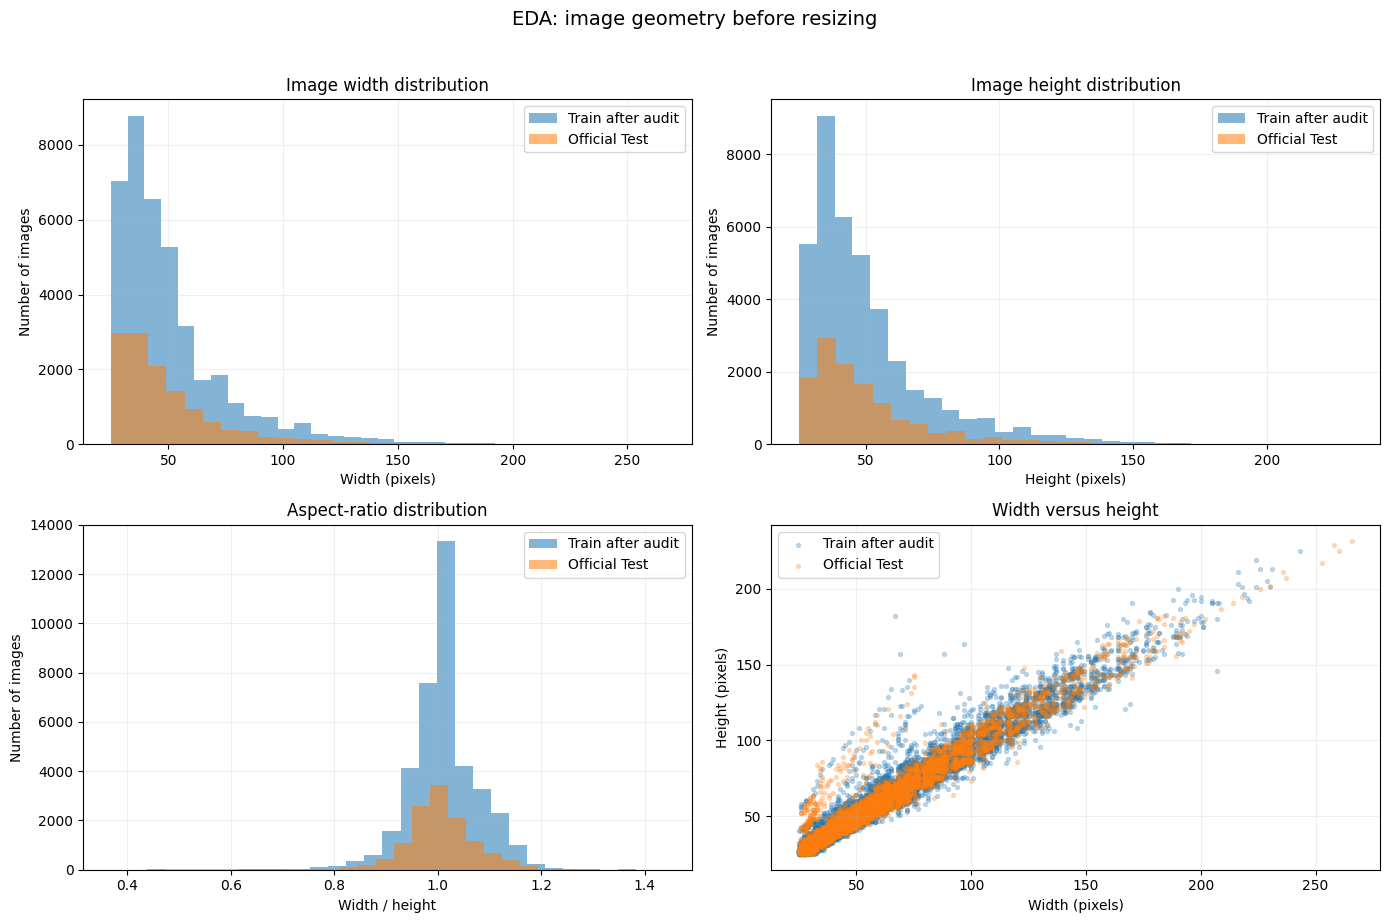

,split,measure,count,mean,std,min,median,max
0,Train after audit,width,39201,50.836968,24.309009,25.000000,43.0,243.000000
1,Train after audit,height,39201,50.329762,23.117381,25.000000,43.0,225.000000
2,Train after audit,aspect,39201,1.007446,0.070831,0.368132,1.0,1.417808
3,Official Test,width,12630,50.507759,25.088483,25.000000,43.0,266.000000
4,Official Test,height,12630,50.364450,23.698908,25.000000,43.0,232.000000
5,Official Test,aspect,12630,1.000001,0.080555,0.392857,1.0,1.437500


In [11]:
# EDA_DIMENSION_PLOTS
# Phân bố kích thước ảnh và tỷ lệ width / height.

_dimension_sets = {
    "Train after audit": df,
    "Official Test": test_df,
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for split_name, frame in _dimension_sets.items():
    axes[0, 0].hist(frame["width"].dropna(), bins=30, alpha=0.55, label=split_name)
    axes[0, 1].hist(frame["height"].dropna(), bins=30, alpha=0.55, label=split_name)
    axes[1, 0].hist(frame["aspect"].dropna(), bins=30, alpha=0.55, label=split_name)
    axes[1, 1].scatter(
        frame["width"], frame["height"], s=8, alpha=0.25,
        label=split_name, rasterized=True
    )

axes[0, 0].set_title("Image width distribution")
axes[0, 0].set_xlabel("Width (pixels)")
axes[0, 0].set_ylabel("Number of images")
axes[0, 1].set_title("Image height distribution")
axes[0, 1].set_xlabel("Height (pixels)")
axes[0, 1].set_ylabel("Number of images")
axes[1, 0].set_title("Aspect-ratio distribution")
axes[1, 0].set_xlabel("Width / height")
axes[1, 0].set_ylabel("Number of images")
axes[1, 1].set_title("Width versus height")
axes[1, 1].set_xlabel("Width (pixels)")
axes[1, 1].set_ylabel("Height (pixels)")
for ax in axes.ravel():
    ax.legend()
    ax.grid(alpha=0.2)
fig.suptitle("EDA: image geometry before resizing", y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "eda_image_dimensions.png", dpi=160, bbox_inches="tight")
plt.show()

_dimension_rows = []
for split_name, frame in _dimension_sets.items():
    for col in ["width", "height", "aspect"]:
        vals = pd.to_numeric(frame[col], errors="coerce").dropna()
        _dimension_rows.append({
            "split": split_name,
            "measure": col,
            "count": int(vals.size),
            "mean": float(vals.mean()),
            "std": float(vals.std()),
            "min": float(vals.min()),
            "median": float(vals.median()),
            "max": float(vals.max()),
        })
_dimension_eda_summary = pd.DataFrame(_dimension_rows)
_dimension_eda_summary.to_csv(OUTPUT_DIR / "eda_image_dimensions_by_split.csv", index=False)
display(_dimension_eda_summary)


## 4.2 EDA — độ sáng, tương phản và chi tiết ảnh

Phần này lấy mẫu phân tầng theo lớp từ Train để mô tả độ sáng và đặc trưng ảnh mà không phải xử lý toàn bộ dataset. `gray_std` là độ lệch chuẩn mức xám, dùng như **proxy** cho tương phản; `edge_energy_proxy` là sai khác pixel trung bình giữa các vị trí lân cận, dùng như **proxy** cho chi tiết/biên, không phải chỉ số blur chuẩn hóa.

Các đặc trưng này giúp đặt câu hỏi cho thí nghiệm robustness, nhưng không tự chứng minh nguyên nhân gây lỗi hay quyết định mô hình nào tốt hơn.

EDA appearance sample:   0%|          | 0/1720 [00:00<?, ?it/s]

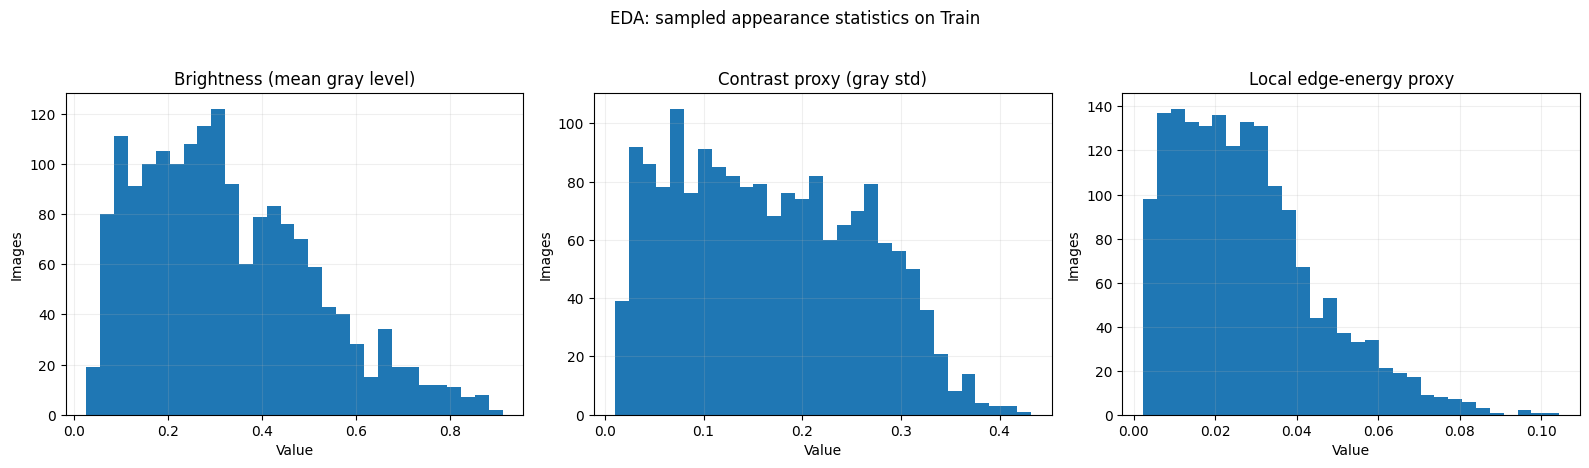

,brightness_mean,gray_std_contrast_proxy,edge_energy_proxy
count,1720.0000,1720.0000,1720.0000
mean,0.3285,0.1667,0.0277
std,0.1842,0.0937,0.0174
min,0.0272,0.0101,0.0023
25%,0.1820,0.0856,0.0139
50%,0.2993,0.1584,0.0253
75%,0.4482,0.2432,0.0372
max,0.9108,0.4318,0.1045


Sample size: 1720 | classes: 43


In [12]:
# EDA_APPEARANCE_STATS — sample stratified by class from Train only.
# Cap at 40 images/class (max 1,720 images for 43 classes) to keep runtime manageable.
_appearance_parts = []
for _class_id, _class_frame in df.groupby("label"):
    _appearance_parts.append(_class_frame.sample(
        n=min(40, len(_class_frame)), random_state=SEED
    ))
_appearance_sample = pd.concat(_appearance_parts, ignore_index=True)
_appearance_rows = []
for _row in tqdm(_appearance_sample.itertuples(index=False), total=len(_appearance_sample), desc="EDA appearance sample"):
    with Image.open(_row.path) as _image:
        _small = _image.convert("RGB").resize((64, 64))
        _rgb = np.asarray(_small, dtype=np.float32) / 255.0
        _gray = np.asarray(_small.convert("L"), dtype=np.float32) / 255.0
    _horizontal = np.abs(np.diff(_gray, axis=1)).mean()
    _vertical = np.abs(np.diff(_gray, axis=0)).mean()
    _appearance_rows.append({
        "path": _row.path,
        "label": int(_row.label),
        "brightness_mean": float(_gray.mean()),
        "gray_std_contrast_proxy": float(_gray.std()),
        "edge_energy_proxy": float((_horizontal + _vertical) / 2.0),
    })
appearance_eda_df = pd.DataFrame(_appearance_rows)
appearance_eda_df.to_csv(OUTPUT_DIR / "eda_appearance_sample.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, column, title in zip(
    axes,
    ["brightness_mean", "gray_std_contrast_proxy", "edge_energy_proxy"],
    ["Brightness (mean gray level)", "Contrast proxy (gray std)", "Local edge-energy proxy"],
):
    ax.hist(appearance_eda_df[column], bins=30)
    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("Images")
    ax.grid(alpha=0.2)
fig.suptitle("EDA: sampled appearance statistics on Train", y=1.03)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "eda_image_appearance.png", dpi=180, bbox_inches="tight")
plt.show()
display(appearance_eda_df[["brightness_mean", "gray_std_contrast_proxy", "edge_energy_proxy"]].describe().round(4))
print("Sample size:", len(appearance_eda_df), "| classes:", appearance_eda_df.label.nunique())


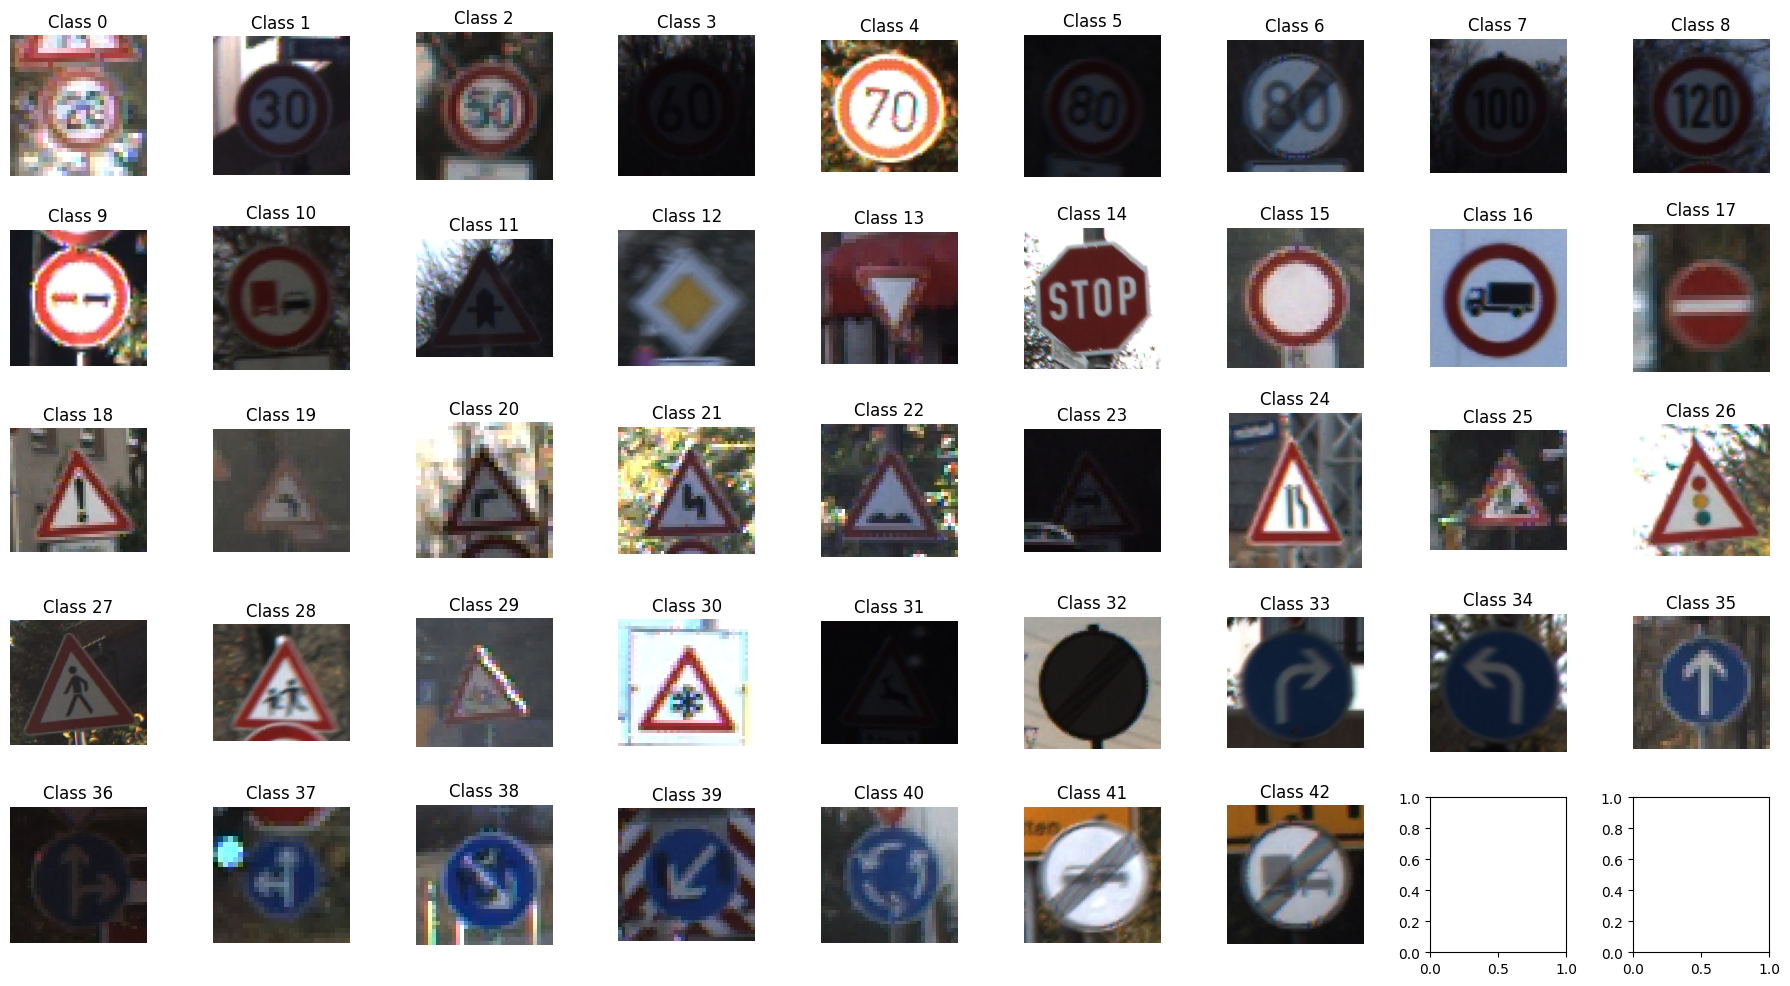

In [13]:
# Hiển thị mẫu ảnh của các lớp
fig, axes = plt.subplots(5, 9, figsize=(18, 10))
for ax, class_id in zip(axes.ravel(), range(NUM_CLASSES)):
    rows = df[df.label == class_id]
    if len(rows):
        fp = rows.sample(1, random_state=SEED).iloc[0]["path"]
        with Image.open(fp) as im:
            ax.imshow(im.convert("RGB"))
    ax.set_title(f"Class {class_id}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Chia Train / Validation / Test

**Giữ nguyên tập Test chính thức từ `Test.csv`.** Chỉ chia `Train.csv` thành Train và Validation.

GTSRB gồm các *track*: mỗi track là khoảng 30 ảnh liên tiếp của **cùng một biển báo vật lý**. Nếu chia ngẫu nhiên theo ảnh, các khung hình gần như giống hệt nhau sẽ nằm ở cả Train lẫn Validation, làm Validation Macro-F1 cao ảo và làm sai lệch việc chọn checkpoint/mô hình. Vì vậy Validation được tách bằng `StratifiedGroupKFold` theo nhóm `(lớp, track)` suy ra từ tên file `<lớp>_<track>_<khung>.png`; notebook kiểm tra bằng code rằng không nhóm nào xuất hiện ở cả hai tập và dừng lại nếu không suy ra được nhóm.

Split manifest (có cột `group`) được lưu để tái lập. Chia theo track loại bỏ nguồn rò rỉ chính nhưng không loại trừ hoàn toàn mọi ảnh gần giống (ví dụ cùng một biển báo chụp ở hai track khác nhau); cần nêu giới hạn này trong báo cáo.

In [14]:
# Chỉ chia Train.csv thành Train và Validation; Test.csv được giữ nguyên.
from sklearn.model_selection import StratifiedGroupKFold

# Suy ra nhóm (lớp, track) từ tên file <lớp>_<track>_<khung>.png
_parts = df["path"].map(lambda p: Path(p).stem).str.extract(r"^(\d+)_(\d+)_(\d+)$")
if _parts.isna().any().any():
    raise ValueError(
        "Không suy ra được (lớp, track) từ tên file cho một số ảnh Train. "
        "Chia theo nhóm là bắt buộc để tránh rò rỉ; hãy sửa biểu thức trích nhóm theo tên file của dataset."
    )
df["group"] = _parts[0] + "_" + _parts[1]
_group_sizes = df.groupby("group").size()
print(f"Số nhóm (track): {len(_group_sizes):,} | kích thước nhóm: trung vị={_group_sizes.median():.0f}, min={_group_sizes.min()}, max={_group_sizes.max()}")
if _group_sizes.median() < 10:
    raise ValueError("Kích thước nhóm trung vị quá nhỏ: việc suy ra track có thể sai và sẽ gây rò rỉ.")

_sgkf = StratifiedGroupKFold(n_splits=GROUP_SPLIT_FOLDS, shuffle=True, random_state=SEED)
_splits = list(_sgkf.split(df, df["label"], df["group"]))
for _fold_i, (_train_idx, _val_idx) in enumerate(_splits):
    if (len(set(df.iloc[_train_idx]["label"])) == NUM_CLASSES and
            len(set(df.iloc[_val_idx]["label"])) == NUM_CLASSES):
        break   # chọn fold đầu tiên có đủ 43 lớp ở cả Train và Validation
else:
    raise ValueError("Không có fold nào đủ 43 lớp ở cả Train và Validation; hãy đổi SEED hoặc GROUP_SPLIT_FOLDS.")
print("Fold dùng làm Validation:", _fold_i)
train_df = df.iloc[_train_idx].reset_index(drop=True)
val_df = df.iloc[_val_idx].reset_index(drop=True)

# Kiểm tra rò rỉ bằng code.
assert not (set(train_df["group"]) & set(val_df["group"])), "RÒ RỈ: có nhóm (track) ở cả Train và Validation"
assert not (set(train_df["path"]) & set(val_df["path"])), "RÒ RỈ: trùng đường dẫn giữa Train và Validation"
for _nm, _d in [("Train", train_df), ("Validation", val_df)]:
    _missing = sorted(set(range(NUM_CLASSES)) - set(_d["label"]))
    if _missing:
        raise ValueError(f"{_nm} thiếu lớp {_missing}. Hãy đổi SEED hoặc GROUP_SPLIT_FOLDS.")
print("Kiểm tra rò rỉ Train/Validation: OK (không nhóm/đường dẫn nào chung)")
test_df = test_df.reset_index(drop=True)  # Đây là Test.csv chính thức, không random split.

print(f"Train (từ Train.csv): {len(train_df):,}")
print(f"Validation (tách từ Train.csv): {len(val_df):,}")
print(f"Test (giữ nguyên Test.csv): {len(test_df):,}")

print("\nClass distribution check:")
class_distribution = pd.DataFrame({
    "train": train_df.label.value_counts().sort_index(),
    "validation": val_df.label.value_counts().sort_index(),
    "official_test": test_df.label.value_counts().sort_index(),
}).reindex(range(NUM_CLASSES)).fillna(0).astype(int)
display(class_distribution)
class_distribution.to_csv(OUTPUT_DIR / "class_distribution_after_split.csv", index_label="class_id")

# Lưu manifest để tái lập thí nghiệm (chỉ đường dẫn và nhãn, không copy ảnh).
train_df.to_csv(OUTPUT_DIR / "split_train.csv", index=False)
val_df.to_csv(OUTPUT_DIR / "split_validation.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "split_official_test.csv", index=False)
print("Đã lưu split manifest vào", OUTPUT_DIR)


Số nhóm (track): 1,307 | kích thước nhóm: trung vị=30, min=22, max=30
Fold dùng làm Validation: 3
Kiểm tra rò rỉ Train/Validation: OK (không nhóm/đường dẫn nào chung)
Train (từ Train.csv): 33,592
Validation (tách từ Train.csv): 5,609
Test (giữ nguyên Test.csv): 12,630

Class distribution check:


,train,validation,official_test
label,,,
0,180,30,60
1,1890,330,720
2,1950,300,750
3,1200,210,450
4,1710,270,660
5,1590,270,630
6,330,90,150
7,1260,180,450
8,1230,180,450


Đã lưu split manifest vào /kaggle/working/gtsrb_results_staged_10models


## 5.1 EDA — phân bố lớp giữa các split

Biểu đồ so sánh cả số ảnh và tỷ trọng phần trăm của từng lớp trên Train, Validation và Test. Phân bố Train/Validation được tạo từ `Train.csv`; `Test.csv` là split chính thức.

Dùng biểu đồ để mô tả sự khác nhau giữa các split và kiểm tra stratification. Không dùng thống kê hoặc kết quả của Test để thay đổi cách chia dữ liệu, augmentation hay siêu tham số sau khi đã xem kết quả cuối.

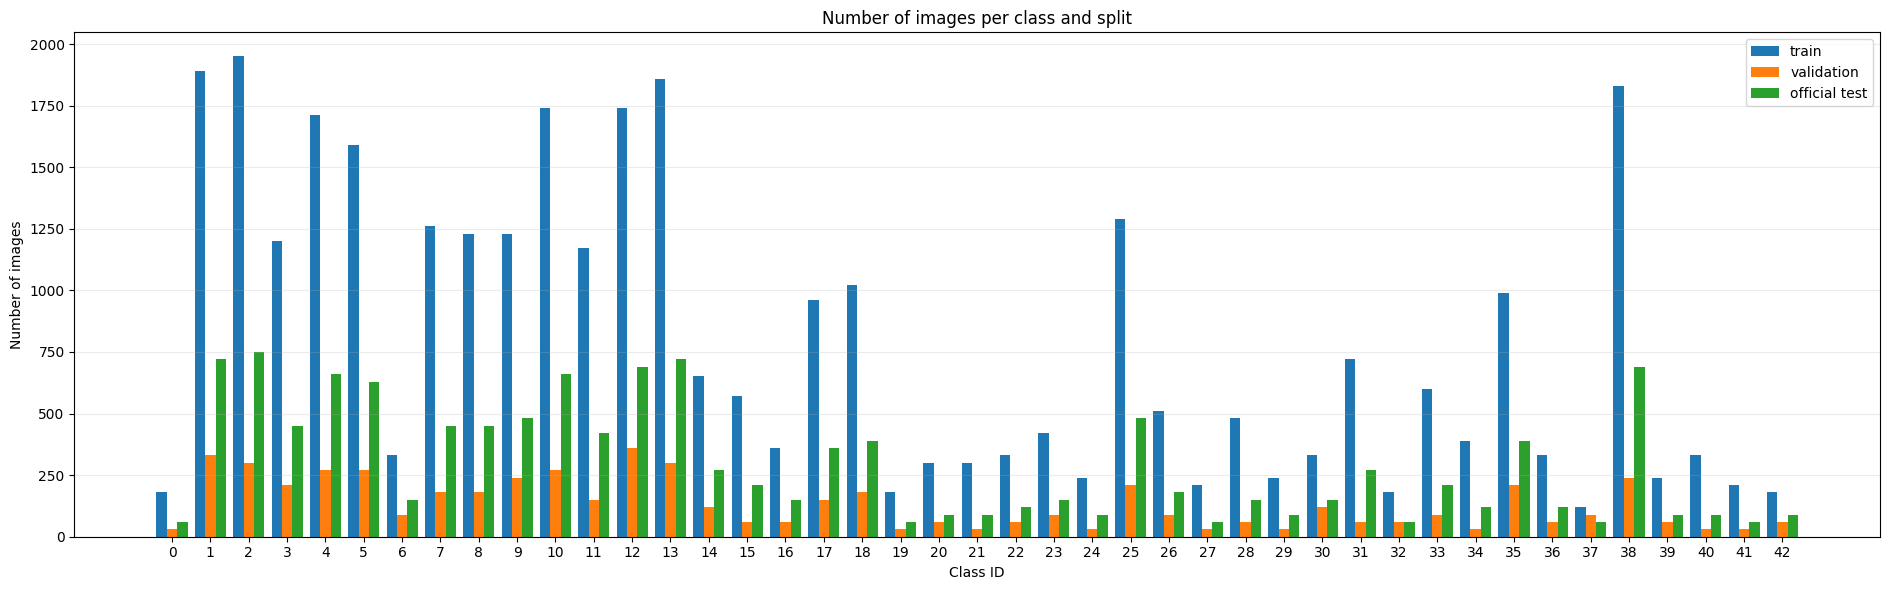

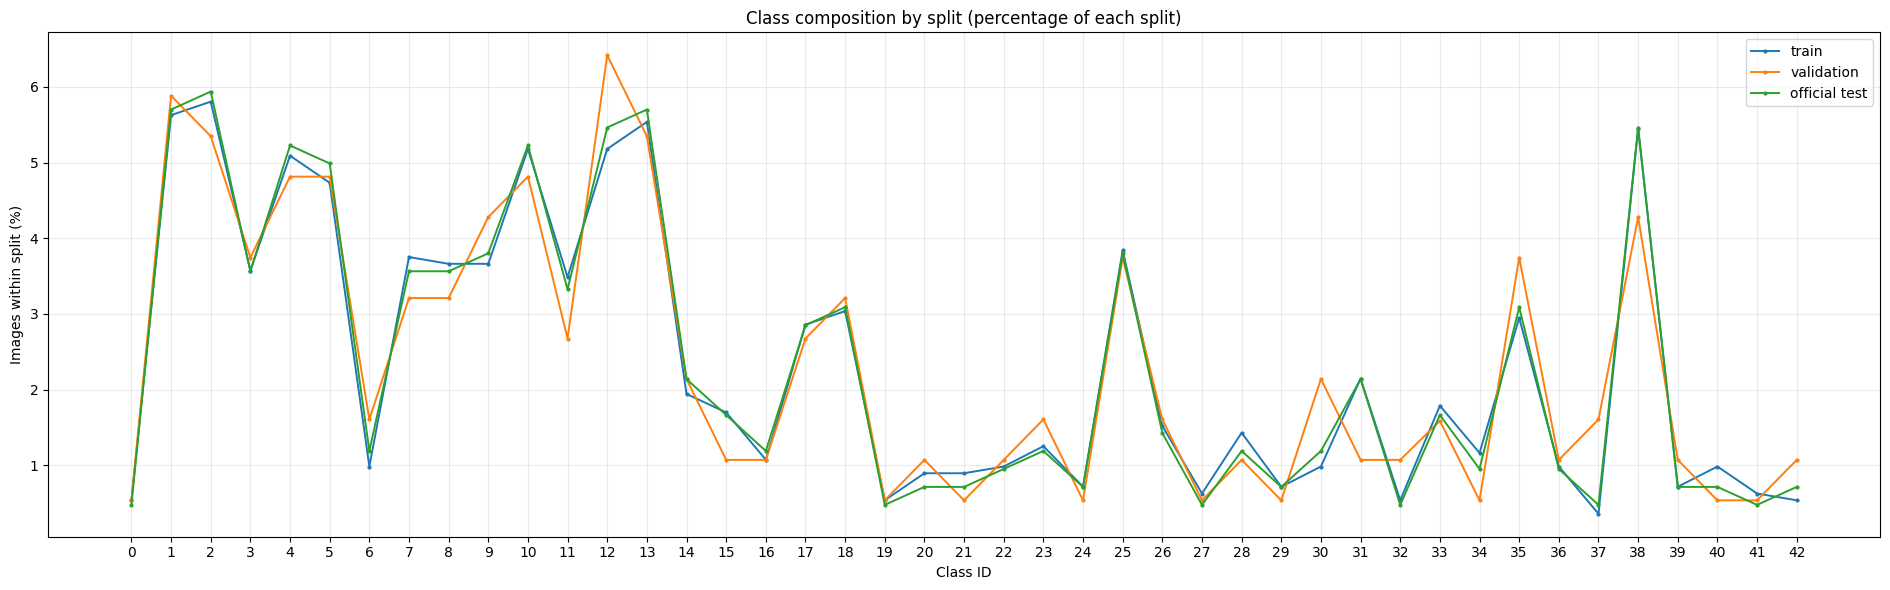

Split balance summary (descriptive only; no model selection based on Test):


,split,total_images,classes_present,min_nonzero_class_count,max_class_count,max_to_min_class_ratio
0,train,33592,43,120,1950,16.25
1,validation,5609,43,30,360,12.00
2,official_test,12630,43,60,750,12.50


In [15]:
# EDA_SPLIT_CLASS_DISTRIBUTION
# class_distribution đã được tạo ngay phía trên: hàng là ClassId, cột là các split.

_split_counts = class_distribution.copy()
_split_counts.index.name = "class_id"
_split_counts.to_csv(OUTPUT_DIR / "eda_class_counts_by_split.csv")

_split_percentages = _split_counts.div(_split_counts.sum(axis=0).replace(0, np.nan), axis=1) * 100
_split_percentages = _split_percentages.fillna(0)
_split_percentages.to_csv(OUTPUT_DIR / "eda_class_percentages_by_split.csv")

_x = np.arange(NUM_CLASSES)
_bar_width = 0.27
fig, ax = plt.subplots(figsize=(19, 6))
for j, col in enumerate(["train", "validation", "official_test"]):
    ax.bar(_x + (j - 1) * _bar_width, _split_counts[col].values,
           width=_bar_width, label=col.replace("_", " "))
ax.set_title("Number of images per class and split")
ax.set_xlabel("Class ID")
ax.set_ylabel("Number of images")
ax.set_xticks(_x)
ax.set_xticklabels([str(i) for i in _x])
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "eda_class_counts_by_split.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(19, 6))
for col in ["train", "validation", "official_test"]:
    ax.plot(_x, _split_percentages[col].values, marker=".", markersize=4,
            linewidth=1.4, label=col.replace("_", " "))
ax.set_title("Class composition by split (percentage of each split)")
ax.set_xlabel("Class ID")
ax.set_ylabel("Images within split (%)")
ax.set_xticks(_x)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "eda_class_percentages_by_split.png", dpi=160, bbox_inches="tight")
plt.show()

_split_summary_rows = []
for col in ["train", "validation", "official_test"]:
    counts = _split_counts[col]
    positive_counts = counts[counts > 0]
    _split_summary_rows.append({
        "split": col,
        "total_images": int(counts.sum()),
        "classes_present": int((counts > 0).sum()),
        "min_nonzero_class_count": int(positive_counts.min()) if len(positive_counts) else 0,
        "max_class_count": int(positive_counts.max()) if len(positive_counts) else 0,
        "max_to_min_class_ratio": float(positive_counts.max() / positive_counts.min()) if len(positive_counts) else np.nan,
    })
_split_summary = pd.DataFrame(_split_summary_rows)
_split_summary.to_csv(OUTPUT_DIR / "eda_split_balance_summary.csv", index=False)
print("Split balance summary (descriptive only; no model selection based on Test):")
display(_split_summary)


## 6. Tiền xử lý và Data Augmentation

Các mô hình sử dụng pipeline ảnh nhất quán trong từng thí nghiệm. Augmentation chỉ áp dụng cho **Train**; Validation và Test chỉ thực hiện resize cùng normalization.

Các phép biến đổi chính trong pipeline gồm xoay góc nhỏ, crop/scale, biến đổi độ sáng/tương phản và ColorJitter, cùng nhiễu/blur nhẹ nếu được cấu hình. Không bật Horizontal Flip mặc định vì lật ngang có thể làm thay đổi ý nghĩa một số biển báo.

Trực quan hóa augmentation ở phần kế tiếp trước khi train dài để kiểm tra không cắt mất biển báo hoặc làm biến đổi nhãn về mặt ngữ nghĩa.

In [16]:
# ImageNet normalization cho ResNet50/EfficientNet pretrained.
# CNN baseline dùng cùng normalization để giữ quy trình input nhất quán.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Crop/resize giữ tỷ lệ gần vuông; augmentation vừa phải để tránh cắt mất biển báo nhỏ.
def build_transform_set(img_size):
    """Trả về (train_aug, train_no_aug, eval) cho một kích thước ảnh; dùng lại khi so sánh các hồ sơ độ phân giải."""
    train_aug = transforms.Compose([
        transforms.RandomResizedCrop(img_size, scale=(0.85, 1.0), ratio=(0.90, 1.10)),
        transforms.RandomRotation(degrees=8),
        transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02),
        transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))], p=0.08),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    plain = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    return train_aug, plain, plain

train_tfms_aug, train_tfms_no_aug, eval_tfms = build_transform_set(IMG_SIZE)

class GTSRBFrameDataset(Dataset):
    def __init__(self, frame, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row["path"]) as im:
            image = im.convert("RGB")
        label = int(row["label"])
        if self.transform:
            image = self.transform(image)
        return image, label, row["path"]

def seed_worker(worker_id):
    """Đồng bộ seed Python/NumPy cho từng DataLoader worker."""
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loaders(use_augmentation=True, seed=SEED, train_tfms_override=None):
    train_tfms = train_tfms_override if train_tfms_override is not None else (
        train_tfms_aug if use_augmentation else train_tfms_no_aug)
    train_ds = GTSRBFrameDataset(train_df, train_tfms)
    val_ds = GTSRBFrameDataset(val_df, eval_tfms)
    test_ds = GTSRBFrameDataset(test_df, eval_tfms)

    # Dùng generator riêng giúp thứ tự shuffle tái lập giữa các lần chạy.
    train_generator = torch.Generator().manual_seed(seed)
    val_generator = torch.Generator().manual_seed(seed + 1)
    test_generator = torch.Generator().manual_seed(seed + 2)
    common_kwargs = {
        "batch_size": BATCH_SIZE,
        "num_workers": NUM_WORKERS,
        "pin_memory": PIN_MEMORY,
        "worker_init_fn": seed_worker,
    }
    # persistent_workers=False: worker processes are recreated each epoch so their seeds
    # are derived from the checkpointable DataLoader generator during resume.
    train_loader = DataLoader(train_ds, shuffle=True, generator=train_generator, **common_kwargs)
    val_loader = DataLoader(val_ds, shuffle=False, generator=val_generator, **common_kwargs)
    test_loader = DataLoader(test_ds, shuffle=False, generator=test_generator, **common_kwargs)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders(True)
print("Batches (train/val/test):", len(train_loader), len(val_loader), len(test_loader))


# Helpers đã tích hợp từ bản rà soát: split theo seed, loaders nhận split rõ ràng, latency median/p95.
SPLIT_PER_SEED = True   # mỗi seed dùng một split Train/Val khác nhau (vẫn theo nhóm track); Test giữ nguyên

def make_group_split(seed, fold=None):
    """Chia df (đã có cột 'group') thành train/val theo StratifiedGroupKFold với random_state=seed.
    Mặc định lấy fold 0 (với seed == SEED trùng split ở mục 5); nếu fold đó thiếu lớp ở Train hoặc Val
    thì thử các fold tiếp theo (lớp hiếm chỉ có ~7 track nên có thể xảy ra)."""
    # Seed chính phải dùng đúng split đã dùng cho E1-E5; các seed phụ có split riêng.
    if int(seed) == int(SEED) and fold is None:
        return train_df.copy().reset_index(drop=True), val_df.copy().reset_index(drop=True)
    sgkf = StratifiedGroupKFold(n_splits=GROUP_SPLIT_FOLDS, shuffle=True, random_state=seed)
    splits = list(sgkf.split(df, df["label"], df["group"]))
    candidates = [fold] if fold is not None else list(range(len(splits)))
    last_msg = ""
    for f in candidates:
        tr_idx, va_idx = splits[f]
        tr = df.iloc[tr_idx].reset_index(drop=True)
        va = df.iloc[va_idx].reset_index(drop=True)
        assert not (set(tr["group"]) & set(va["group"])), "RÒ RỈ: nhóm (track) nằm ở cả Train và Val"
        assert not (set(tr["path"]) & set(va["path"])), "RÒ RỈ: trùng đường dẫn"
        miss_tr = sorted(set(range(NUM_CLASSES)) - set(tr["label"]))
        miss_va = sorted(set(range(NUM_CLASSES)) - set(va["label"]))
        if not miss_tr and not miss_va:
            if f != candidates[0]:
                print(f"[make_group_split] seed={seed}: fold {candidates[0]} thiếu lớp, dùng fold {f}.")
            return tr, va
        last_msg = f"fold {f}: Train thiếu {miss_tr}, Val thiếu {miss_va}"
    raise ValueError(f"Không có fold nào đủ 43 lớp ở cả Train và Val (seed={seed}). {last_msg}")

def stratified_sample(frame, per_class, seed=SEED):
    """Lấy tối đa per_class ảnh mỗi lớp (cố định theo seed)."""
    parts = [g.sample(n=min(per_class, len(g)), random_state=seed) for _, g in frame.groupby("label")]
    return pd.concat(parts, ignore_index=True)

def make_loaders(use_augmentation=True, seed=SEED, train_tfms_override=None, tr_df=None, va_df=None):
    tr_df = train_df if tr_df is None else tr_df
    va_df = val_df if va_df is None else va_df
    train_tfms = train_tfms_override if train_tfms_override is not None else (
        train_tfms_aug if use_augmentation else train_tfms_no_aug)
    train_ds = GTSRBFrameDataset(tr_df, train_tfms)
    val_ds = GTSRBFrameDataset(va_df, eval_tfms)
    test_ds = GTSRBFrameDataset(test_df, eval_tfms)
    common = {"batch_size": BATCH_SIZE, "num_workers": NUM_WORKERS,
              "pin_memory": PIN_MEMORY, "worker_init_fn": seed_worker}
    train_loader = DataLoader(train_ds, shuffle=True, generator=torch.Generator().manual_seed(seed), **common)
    val_loader = DataLoader(val_ds, shuffle=False, generator=torch.Generator().manual_seed(seed + 1), **common)
    test_loader = DataLoader(test_ds, shuffle=False, generator=torch.Generator().manual_seed(seed + 2), **common)
    return train_loader, val_loader, test_loader

def _cuda_sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def benchmark_latency_stats(model, warmup=30, runs=200, amp=None):
    """Latency model-only, batch=1, đo từng lượt (median/p95), có chọn fp32 hoặc AMP."""
    amp = USE_AMP if amp is None else bool(amp)
    model.eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    times = []
    for i in range(warmup + runs):
        _cuda_sync()
        t0 = time.perf_counter()
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
            _ = model(x)
        _cuda_sync()
        if i >= warmup:
            times.append((time.perf_counter() - t0) * 1000)
    t = np.asarray(times)
    return {"median_ms": float(np.median(t)), "p95_ms": float(np.percentile(t, 95)),
            "mean_ms": float(t.mean()), "std_ms": float(t.std())}

def benchmark_model_latency(model, warmup=30, runs=200):
    """Giữ tên cũ (suite/mục 15 gọi hàm này) nhưng trả median ms, cùng chế độ precision với đánh giá chính."""
    return benchmark_latency_stats(model, warmup, runs, amp=USE_AMP)["median_ms"]

print("Helper P3 sẵn sàng. SPLIT_PER_SEED =", SPLIT_PER_SEED)

Batches (train/val/test): 1050 176 395
Helper P3 sẵn sàng. SPLIT_PER_SEED = True


## 6.1 Kiểm tra batch sau preprocessing

Kiểm tra shape, kiểu dữ liệu, nhãn và khoảng giá trị sau resize/normalization. Bước này nhằm xác minh batch có thể truyền vào mô hình và preprocessing không vô tình áp dụng augmentation lên Validation/Test.

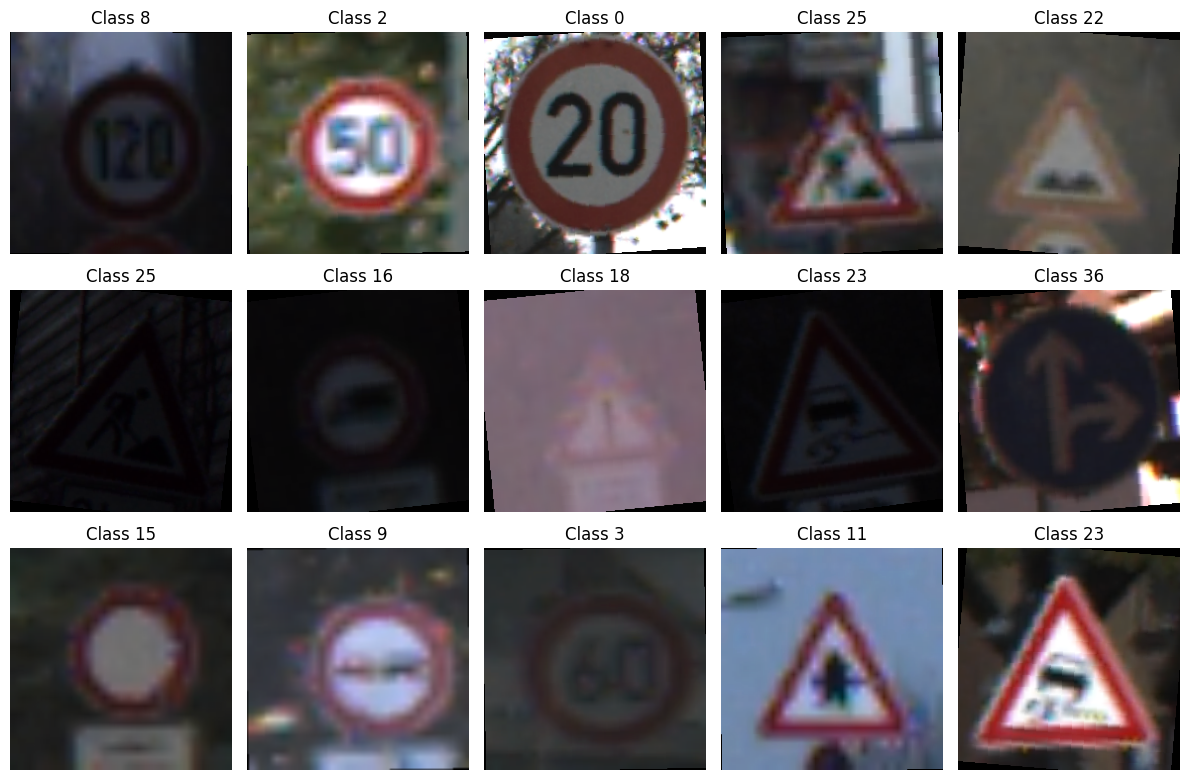

In [17]:
def denormalize(tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return torch.clamp(tensor.cpu() * std + mean, 0, 1)

images, labels, paths = next(iter(train_loader))

fig, axes = plt.subplots(3, 5, figsize=(12, 8))
for ax, img, label in zip(axes.ravel(), images[:15], labels[:15]):
    ax.imshow(denormalize(img).permute(1, 2, 0))
    ax.set_title(f"Class {label.item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6.2 EDA — trực quan hóa Data Augmentation

Hiển thị ảnh gốc cạnh nhiều phiên bản tăng cường từ cùng một ảnh nguồn. Kiểm tra xoay/crop/điều chỉnh màu có làm mất biển báo, che ký hiệu hoặc khiến nhãn không còn đúng hay không.

Hình ảnh là bằng chứng định tính để kiểm tra pipeline; hiệu quả augmentation vẫn cần được đánh giá định lượng trong thí nghiệm A1 và các phép đo Validation.

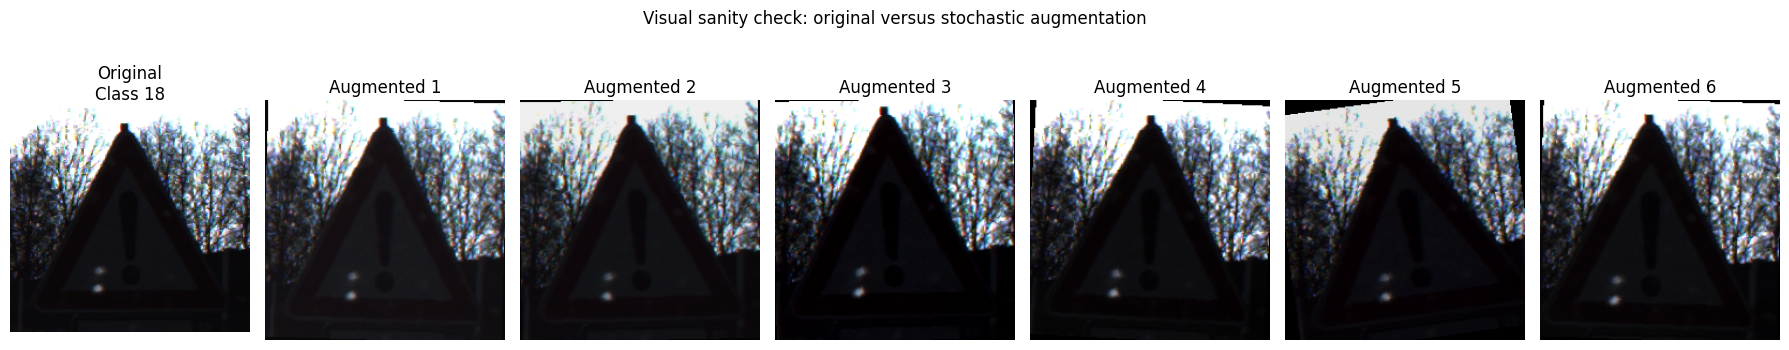

Nguồn ảnh: /kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Train/18/00018_00033_00029.png
Nhãn gốc: 18 - General caution
Nếu augmentation làm mất phần nhận dạng quan trọng của biển báo, hãy giảm độ mạnh trước khi train.


In [18]:
# EDA_AUGMENTATION_VISUAL_CHECK
# Cùng một ảnh nguồn, áp dụng pipeline augmentation nhiều lần để xem mức độ biến thiên.

_aug_row = train_df.sample(n=1, random_state=SEED).iloc[0]
with Image.open(_aug_row["path"]) as _im:
    _source_image = _im.convert("RGB")

_n_augmented_views = 6
fig, axes = plt.subplots(1, _n_augmented_views + 1, figsize=(18, 3.6))
axes[0].imshow(_source_image)
axes[0].set_title(f"Original\nClass {_aug_row['label']}")
axes[0].axis("off")
for _view_idx in range(_n_augmented_views):
    _aug_tensor = train_tfms_aug(_source_image.copy())
    axes[_view_idx + 1].imshow(denormalize(_aug_tensor).permute(1, 2, 0).numpy())
    axes[_view_idx + 1].set_title(f"Augmented {_view_idx + 1}")
    axes[_view_idx + 1].axis("off")
fig.suptitle("Visual sanity check: original versus stochastic augmentation", y=1.04)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "eda_augmentation_visual_check.png", dpi=160, bbox_inches="tight")
plt.show()
print("Nguồn ảnh:", _aug_row["path"])
print("Nhãn gốc:", int(_aug_row["label"]), "-", CLASS_LABEL_NAMES.get(str(int(_aug_row["label"])), "Unknown"))
print("Nếu augmentation làm mất phần nhận dạng quan trọng của biển báo, hãy giảm độ mạnh trước khi train.")


# 7. E1 — CNN huấn luyện từ đầu

CNN Scratch là baseline Deep Learning không dùng trọng số pretrained. Cấu trúc gồm các khối convolution, BatchNorm, ReLU và pooling, sau đó là tầng phân loại 43 lớp.

Mục tiêu là đo mức hiệu quả có thể đạt được khi mô hình tự học đặc trưng từ GTSRB, tạo baseline để so sánh với các backbone pretrained. Không mặc định rằng baseline này phải thấp hơn; kết quả phụ thuộc dữ liệu, kiến trúc và quá trình tối ưu.

In [19]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=0.0):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(dropout)
        )

    def forward(self, x):
        return self.block(x)

class CNNBaseline(nn.Module):
    def __init__(self, num_classes=43):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32, 0.05),
            ConvBlock(32, 64, 0.08),
            ConvBlock(64, 128, 0.10),
            ConvBlock(128, 256, 0.15),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.30),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

cnn = CNNBaseline(NUM_CLASSES).to(DEVICE)
print(cnn)

CNNBaseline(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (7): Dropout2d(p=0.05, inplace=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(

## 8. ResNet50 và EfficientNet-B0 pretrained

Hai backbone sử dụng trọng số pretrained ImageNet khi có thể tải/cached weights:

- **Transfer Learning (TL):** đóng băng backbone và chỉ cập nhật classifier.
- **Fine-tuning (FT):** mở khóa một phần các tầng cuối và tiếp tục huấn luyện với learning rate nhỏ cho backbone.

So sánh TL với FT giúp phân tích lợi ích của việc cập nhật đặc trưng pretrained và chi phí huấn luyện bổ sung. Vì cả hai mô hình được huấn luyện trên cùng dataset, kết luận cần dựa trên số liệu thực tế thay vì giả định một kiến trúc luôn tốt hơn.

In [20]:
def build_resnet50(num_classes=NUM_CLASSES, pretrained=True):
    # Ghim phiên bản weights để tái lập khi torchvision đổi DEFAULT.
    weights = models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
    model = models.resnet50(weights=weights)
    for p in model.parameters():
        p.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Sequential(nn.Dropout(0.30), nn.Linear(in_features, num_classes))
    return model

def build_efficientnet_b0(num_classes=NUM_CLASSES, pretrained=True):
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.efficientnet_b0(weights=weights)
    for p in model.parameters():
        p.requires_grad = False
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Sequential(nn.Dropout(0.30), nn.Linear(in_features, num_classes))
    return model

PRETRAINED_WEIGHTS_USED = {"resnet50": "ResNet50_Weights.IMAGENET1K_V2",
                           "efficientnet_b0": "EfficientNet_B0_Weights.IMAGENET1K_V1"}
def build_convnext_tiny(num_classes=NUM_CLASSES, pretrained=True):
    """ConvNeXt-Tiny with a 43-class head; pretrained=False means random initialization."""
    weights = models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.convnext_tiny(weights=weights)
    for p in model.parameters():
        p.requires_grad = False
    in_features = model.classifier[2].in_features
    model.classifier[2] = nn.Sequential(nn.Dropout(0.30), nn.Linear(in_features, num_classes))
    return model

PRETRAINED_WEIGHTS_USED["convnext_tiny"] = "ConvNeXt_Tiny_Weights.IMAGENET1K_V1"
print("Model builders ready:", PRETRAINED_WEIGHTS_USED)


Model builders ready: {'resnet50': 'ResNet50_Weights.IMAGENET1K_V2', 'efficientnet_b0': 'EfficientNet_B0_Weights.IMAGENET1K_V1', 'convnext_tiny': 'ConvNeXt_Tiny_Weights.IMAGENET1K_V1'}


# 9. Tiện ích huấn luyện và quản lý checkpoint

Các tiện ích theo dõi Train/Validation loss, Accuracy, Macro-F1 và learning rate. Checkpoint tốt nhất của mỗi giai đoạn được xác định bằng **Validation Macro-F1**.

Nếu cần tiếp tục sau khi phiên Kaggle bị ngắt, chỉ bật resume khi checkpoint `*_last.pt` tương ứng vẫn tồn tại và thuộc đúng cấu hình thí nghiệm. Lưu riêng checkpoint phục vụ resume và file weights dùng để đo dung lượng; không so sánh kích thước tệp có cấu trúc lưu khác nhau.

In [21]:
# Các hàm tiện ích của Mục 9 — phải được định nghĩa trước fit_model/E1.

def count_parameters(model):
    """Tổng số tham số của mô hình, gồm cả tham số đang đóng băng."""
    return sum(p.numel() for p in model.parameters())


def count_trainable_parameters(model):
    """Số tham số thực sự được optimizer cập nhật."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def set_frozen_batchnorm_eval(model):
    """Giữ running stats của BatchNorm đóng băng khi fine-tune một phần backbone."""
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            params = list(module.parameters(recurse=False))
            if params and not any(p.requires_grad for p in params):
                module.eval()


def run_epoch(model, loader, criterion, optimizer=None, scaler=None, desc=None):
    """Chạy một epoch train (optimizer khác None) hoặc validation; trả loss, accuracy, macro-F1."""
    is_train = optimizer is not None
    model.train(is_train)
    if is_train:
        set_frozen_batchnorm_eval(model)
    total_loss, total_seen, correct_n = 0.0, 0, 0
    y_true, y_pred = [], []
    use_amp = bool(USE_AMP and DEVICE.type == "cuda")
    pbar = tqdm(loader, leave=False, dynamic_ncols=True, desc=desc or ('train' if is_train else 'val'))
    for images, labels, *_ in pbar:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True).long()
        if is_train:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(is_train):
            try:
                amp_context = torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp)
            except (AttributeError, TypeError):
                from contextlib import nullcontext
                amp_context = torch.cuda.amp.autocast(enabled=use_amp) if use_amp else nullcontext()
            with amp_context:
                logits = model(images)
                loss = criterion(logits, labels)
            if is_train:
                if scaler is not None and scaler.is_enabled():
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()
        batch_n = int(labels.size(0))
        total_loss += float(loss.detach().item()) * batch_n
        total_seen += batch_n
        correct_n += int((logits.detach().argmax(dim=1) == labels).sum().item())
        pbar.set_postfix(loss=f"{total_loss / total_seen:.4f}", acc=f"{correct_n / total_seen:.4f}")
        y_true.extend(labels.detach().cpu().numpy().tolist())
        y_pred.extend(logits.detach().argmax(dim=1).cpu().numpy().tolist())
    if total_seen == 0:
        raise ValueError("DataLoader rỗng; không thể chạy run_epoch.")
    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    return total_loss / total_seen, float(accuracy), float(macro_f1)


def save_checkpoint(model, path, model_name, history, extra=None, optimizer=None,
                    scheduler=None, epoch=0, train_generator=None, experiment_seed=SEED):
    """Lưu checkpoint có thể resume, bao gồm optimizer/scheduler và trạng thái RNG."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    payload = {
        "model_name": str(model_name),
        "state_dict": model.state_dict(),
        "history": {k: list(v) for k, v in (history or {}).items()},
        "extra": dict(extra or {}),
        "epoch": int(epoch),
        "experiment_seed": int(experiment_seed),
        "optimizer_state_dict": optimizer.state_dict() if optimizer is not None else None,
        "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
        "python_rng_state": random.getstate(),
        "numpy_rng_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state_all": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "train_generator_state": train_generator.get_state() if train_generator is not None else None,
    }
    torch.save(payload, path)
    return path


def load_checkpoint_for_resume(model, optimizer, scheduler, checkpoint_path,
                               train_generator=None, experiment_seed=SEED):
    """Khôi phục model, optimizer, scheduler, lịch sử và RNG; trả (epoch đã xong, history, extra)."""
    checkpoint_path = Path(checkpoint_path)
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy checkpoint để resume: {checkpoint_path}")
    try:
        checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
    except TypeError:
        checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    if "state_dict" not in checkpoint:
        raise ValueError(f"Checkpoint không có state_dict: {checkpoint_path}")
    saved_seed = checkpoint.get("experiment_seed")
    if saved_seed is not None and int(saved_seed) != int(experiment_seed):
        raise ValueError(f"Seed checkpoint ({saved_seed}) khác seed hiện tại ({experiment_seed}); không resume nhầm run.")
    model.load_state_dict(checkpoint["state_dict"])
    if optimizer is not None and checkpoint.get("optimizer_state_dict") is not None:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    if scheduler is not None and checkpoint.get("scheduler_state_dict") is not None:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    if checkpoint.get("python_rng_state") is not None:
        random.setstate(checkpoint["python_rng_state"])
    if checkpoint.get("numpy_rng_state") is not None:
        np.random.set_state(checkpoint["numpy_rng_state"])
    if checkpoint.get("torch_rng_state") is not None:
        torch.set_rng_state(checkpoint["torch_rng_state"].cpu())
    cuda_states = checkpoint.get("cuda_rng_state_all")
    if torch.cuda.is_available() and cuda_states is not None:
        try:
            torch.cuda.set_rng_state_all(cuda_states)
        except Exception as exc:
            print("Cảnh báo: không khôi phục được CUDA RNG:", exc)
    gen_state = checkpoint.get("train_generator_state")
    if train_generator is not None and gen_state is not None:
        train_generator.set_state(gen_state.cpu())
    extra = dict(checkpoint.get("extra") or {})
    return int(checkpoint.get("epoch", 0)), dict(checkpoint.get("history") or {}), extra


def maybe_resume_path(model_name):
    """Chỉ resume *_last.pt khi RESUME_FROM_LAST=True; mặc định không resume checkpoint cũ."""
    if not globals().get("RESUME_FROM_LAST", False):
        return None
    path = Path(OUTPUT_DIR) / f"{model_name}_last.pt"
    if path.is_file():
        print(f"Resume checkpoint: {path}")
        return path
    print(f"RESUME_FROM_LAST=True nhưng chưa có checkpoint: {path}; bắt đầu mới.")
    return None


def plot_history(history, title="Training history"):
    """Vẽ và lưu learning curves nếu history có dữ liệu."""
    if not history or not history.get("train_loss"):
        print(f"Không có history để vẽ: {title}")
        return None
    epochs_axis = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    panels = [
        ("loss", "Loss", "train_loss", "val_loss"),
        ("accuracy", "Accuracy", "train_acc", "val_acc"),
        ("macro_f1", "Macro-F1", "train_macro_f1", "val_macro_f1"),
    ]
    for ax, (_, ylabel, train_key, val_key) in zip(axes, panels):
        if train_key in history:
            ax.plot(epochs_axis[:len(history[train_key])], history[train_key], label="Train")
        if val_key in history:
            ax.plot(epochs_axis[:len(history[val_key])], history[val_key], label="Validation")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    safe_title = "".join(ch if ch.isalnum() or ch in "-_" else "_" for ch in title).strip("_")
    output_path = Path(OUTPUT_DIR) / f"{safe_title or 'training_history'}.png"
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    print("Đã lưu learning curves:", output_path)
    return output_path


FT_TL_LOG = []   # mỗi dòng: một cặp TL→FT



def fit_model(model, train_loader, val_loader, epochs, lr, model_name,
              weight_decay=WEIGHT_DECAY, scheduler=True, patience=EARLY_STOP_PATIENCE,
              min_delta=MIN_DELTA, param_groups=None, resume_from=None, experiment_seed=SEED,
              initial_best_f1=None, skip_if_done=None):
    if initial_best_f1 is not None:
        raise ValueError("initial_best_f1 đã bị bỏ: nó khiến Val F1 của FT luôn >= TL theo cấu trúc. "
                         "Hãy xoá tham số này khỏi lời gọi và dùng log_ft_vs_tl() để so sánh.")
    # ---- Bỏ qua nếu mô hình đã train xong với CÙNG cấu hình (đổi seed/lr/batch/img/epochs => train lại) ----
    _skip = SKIP_IF_DONE if skip_if_done is None else bool(skip_if_done)
    done_path = OUTPUT_DIR / f"{model_name}_done.json"
    _sig = {"epochs": int(epochs), "lr": float(lr), "weight_decay": float(weight_decay),
            "patience": int(patience), "seed": int(experiment_seed), "scheduler": bool(scheduler),
            "batch_size": int(train_loader.batch_size), "img_size": int(IMG_SIZE),
            "n_train": int(len(train_loader.dataset)), "n_val": int(len(val_loader.dataset))}
    _best_file = OUTPUT_DIR / f"{model_name}_best.pt"
    if _skip and resume_from is None and done_path.is_file() and _best_file.is_file():
        _d = json.loads(done_path.read_text(encoding="utf-8"))
        if _d.get("signature") == _sig:
            try:
                _ck = torch.load(_best_file, map_location=DEVICE, weights_only=False)
            except TypeError:
                _ck = torch.load(_best_file, map_location=DEVICE)
            model.load_state_dict(_ck["state_dict"])
            print(f"[SKIP] {model_name}: đã train xong (best epoch {_d.get('best_epoch')}, "
                  f"val Macro-F1 {_d.get('best_val_macro_f1', float('nan')):.4f}); nạp best checkpoint, không train lại.")
            return model, _d["history"], float(_d["elapsed_sec"])
        print(f"[{model_name}] cấu hình đã đổi so với lần train trước -> train lại.")

    criterion = nn.CrossEntropyLoss()
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    optimizer_params = param_groups if param_groups is not None else [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.AdamW(optimizer_params, lr=lr, weight_decay=weight_decay)
    sched = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=3, min_lr=1e-7) if scheduler else None

    history = defaultdict(list)
    best_val_f1, best_epoch, start_epoch, stale_epochs = -1.0, 0, 0, 0
    best_state = copy.deepcopy(model.state_dict())
    last_path = OUTPUT_DIR / f"{model_name}_last.pt"
    best_path = OUTPUT_DIR / f"{model_name}_best.pt"
    weights_path = OUTPUT_DIR / f"{model_name}_weights.pt"

    if resume_from is None:
        # Tránh dùng nhầm file của lần chạy trước (cùng tên) khi huấn luyện mới.
        for p_ in (last_path, best_path, weights_path, done_path):
            if p_.exists():
                p_.unlink()
    else:
        start_epoch, loaded_history, extra = load_checkpoint_for_resume(
            model, optimizer, sched, resume_from, train_generator=getattr(train_loader, "generator", None),
            experiment_seed=experiment_seed)
        history = defaultdict(list, {k: list(v) for k, v in loaded_history.items()})
        best_val_f1 = float(extra.get("best_validation_macro_f1", -1.0))
        best_epoch = int(extra.get("best_epoch", start_epoch))
        stale_epochs = int(extra.get("stale_epochs", 0))
        best_state = copy.deepcopy(model.state_dict())
        if best_path.exists():
            try:
                bp = torch.load(best_path, map_location=DEVICE, weights_only=False)
            except TypeError:
                bp = torch.load(best_path, map_location=DEVICE)
            best_state = copy.deepcopy(bp["state_dict"])
        print(f"Resuming {model_name} at epoch {start_epoch + 1}")

    _cuda_sync()
    start_time = time.perf_counter()
    print(f"[{model_name}] bắt đầu train: tối đa {epochs} epoch | lr={lr} | trainable={count_trainable_parameters(model):,} | "
          f"train={len(train_loader.dataset):,} ảnh, val={len(val_loader.dataset):,} ảnh", flush=True)
    _epoch_times = []
    for epoch in range(start_epoch + 1, epochs + 1):
        _t_ep = time.perf_counter()
        train_loss, train_acc, train_f1 = run_epoch(model, train_loader, criterion, optimizer, scaler=scaler,
                                                    desc=f"Epoch {epoch}/{epochs} [train]")
        val_loss, val_acc, val_f1 = run_epoch(model, val_loader, criterion, optimizer=None,
                                              desc=f"Epoch {epoch}/{epochs} [val]")
        current_lrs = [float(g["lr"]) for g in optimizer.param_groups]
        for key, value in {"train_loss": train_loss, "train_acc": train_acc, "train_macro_f1": train_f1,
                           "val_loss": val_loss, "val_acc": val_acc, "val_macro_f1": val_f1,
                           "learning_rate": current_lrs[0]}.items():
            history[key].append(float(value))

        if val_f1 > best_val_f1 + min_delta:
            best_val_f1, best_epoch, stale_epochs = val_f1, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
            save_checkpoint(model, best_path, model_name, dict(history),
                            {"best_epoch": best_epoch, "selection_metric": "validation_macro_f1",
                             "best_validation_macro_f1": best_val_f1},
                            optimizer=None, scheduler=None, epoch=epoch,
                            train_generator=getattr(train_loader, "generator", None),
                            experiment_seed=experiment_seed)
            torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, weights_path)
        else:
            stale_epochs += 1
        if sched is not None:
            sched.step(val_f1)
        save_checkpoint(model, last_path, model_name, dict(history),
                        {"best_epoch": best_epoch, "best_validation_macro_f1": best_val_f1,
                         "stale_epochs": stale_epochs},
                        optimizer=optimizer, scheduler=sched, epoch=epoch,
                        train_generator=getattr(train_loader, "generator", None),
                        experiment_seed=experiment_seed)
        _epoch_times.append(time.perf_counter() - _t_ep)
        _eta_min = (sum(_epoch_times) / len(_epoch_times)) * (epochs - epoch) / 60
        _star = " ★ best" if best_epoch == epoch else f" (chưa cải thiện {stale_epochs}/{patience})"
        _mem = f" | GPU {torch.cuda.max_memory_allocated() / 1024**3:.1f}GB" if DEVICE.type == "cuda" else ""
        print(f"Epoch {epoch:02d}/{epochs} | train loss={train_loss:.4f} acc={train_acc:.4f} F1={train_f1:.4f} | "
              f"val loss={val_loss:.4f} acc={val_acc:.4f} F1={val_f1:.4f} | lr={', '.join(f'{v:.2e}' for v in current_lrs)} | "
              f"{_epoch_times[-1]:.0f}s/epoch, còn tối đa ~{_eta_min:.1f} phút{_mem}{_star}", flush=True)
        if stale_epochs >= patience:
            print(f"Early stopping: Val Macro-F1 không cải thiện sau {patience} epoch.")
            break

    _cuda_sync()
    elapsed = time.perf_counter() - start_time
    model.load_state_dict(best_state)
    print(f"Best epoch: {best_epoch} | best validation Macro-F1: {best_val_f1:.4f}")
    done_path.write_text(json.dumps({
        "signature": _sig, "history": {k: list(map(float, v)) for k, v in history.items()},
        "elapsed_sec": float(elapsed), "best_epoch": int(best_epoch),
        "best_val_macro_f1": float(best_val_f1)}), encoding="utf-8")
    return model, dict(history), elapsed

def log_ft_vs_tl(name, h_tl, h_ft, model=None, seed=SEED):
    """Ghi lại FT vs TL KHÔNG thiên lệch: FT dùng best epoch của chính nó (có thể thấp hơn TL)."""
    tl_best, ft_best = max(h_tl["val_macro_f1"]), max(h_ft["val_macro_f1"])
    row = {"backbone": name, "seed": int(seed), "tl_best_val_f1": tl_best, "ft_best_val_f1": ft_best,
           "delta_ft_minus_tl_pts": (ft_best - tl_best) * 100,
           "ft_better_than_tl": bool(ft_best > tl_best + MIN_DELTA),
           "ft_best_epoch": int(np.argmax(h_ft["val_macro_f1"])) + 1}
    if model is not None:
        total = count_parameters(model)
        row["trainable_params_ft"] = int(count_trainable_parameters(model))
        row["trainable_fraction_ft"] = row["trainable_params_ft"] / total
    FT_TL_LOG.append(row)
    pd.DataFrame(FT_TL_LOG).to_csv(OUTPUT_DIR / "ft_vs_tl_log.csv", index=False)
    print(f"[{name} seed {seed}] TL={tl_best:.4f} | FT={ft_best:.4f} | Δ={row['delta_ft_minus_tl_pts']:+.3f} điểm % | "
          f"FT tốt hơn TL: {row['ft_better_than_tl']}")
    return row
print("fit_model mới sẵn sàng (không còn initial_best_f1).")

fit_model mới sẵn sàng (không còn initial_best_f1).


## Preflight — kiểm tra data batch, forward/backward và lưu–nạp weights

Chạy trước khi bắt đầu huấn luyện dài. Cell này **không** thay đổi các DataFrame split, không đọc/đánh giá official Test, không ghi đè checkpoint dự án và không thay đổi số epoch.


In [22]:
RUN_PREFLIGHT = True
if RUN_PREFLIGHT:
    import io
    _saved_rng = torch.get_rng_state()
    _smoke_train_loader, _smoke_val_loader, _ = make_loaders(
        use_augmentation=True, seed=SEED,
        tr_df=stratified_sample(train_df, per_class=2, seed=SEED),
        va_df=stratified_sample(val_df, per_class=2, seed=SEED))
    _images, _labels, _paths = next(iter(_smoke_train_loader))
    _images, _labels = _images[:2].to(DEVICE), _labels[:2].to(DEVICE)
    _smoke_rows = []
    for _name, _builder in [
        ("CNN", lambda: CNNBaseline(NUM_CLASSES)),
        ("ResNet50", lambda: build_resnet50(pretrained=False)),
        ("EfficientNet-B0", lambda: build_efficientnet_b0(pretrained=False)),
        ("ConvNeXt-Tiny", lambda: build_convnext_tiny(pretrained=False)),
    ]:
        _m = _builder().to(DEVICE)
        _m.train()
        _logits = _m(_images)
        _loss = nn.CrossEntropyLoss()(_logits, _labels)
        _loss.backward()
        assert _logits.shape == (len(_labels), NUM_CLASSES), f"Sai output shape: {_name} {_logits.shape}"
        _buffer = io.BytesIO()
        torch.save({k: v.detach().cpu() for k, v in _m.state_dict().items()}, _buffer)
        _buffer.seek(0)
        try:
            _state = torch.load(_buffer, map_location="cpu", weights_only=True)
        except TypeError:
            _buffer.seek(0)
            _state = torch.load(_buffer, map_location="cpu")
        _m.load_state_dict(_state)
        _smoke_rows.append({"model": _name, "logits_shape": tuple(_logits.shape), "loss_finite": bool(torch.isfinite(_loss).item()), "weights_roundtrip": "OK"})
        del _m, _logits, _loss, _buffer, _state
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    torch.set_rng_state(_saved_rng)
    display(pd.DataFrame(_smoke_rows))
    print("PREFLIGHT OK. Đây là kiểm tra kỹ thuật nhanh, không thay thế việc chạy hết notebook.")
else:
    print("RUN_PREFLIGHT=False: đã bỏ qua preflight.")


,model,logits_shape,loss_finite,weights_roundtrip
0,CNN,"(2, 43)",True,OK
1,ResNet50,"(2, 43)",True,OK
2,EfficientNet-B0,"(2, 43)",True,OK
3,ConvNeXt-Tiny,"(2, 43)",True,OK


PREFLIGHT OK. Đây là kiểm tra kỹ thuật nhanh, không thay thế việc chạy hết notebook.


In [23]:
# PREFLIGHT 2 — kiểm tra đầy đủ TRƯỚC khi train dài (thường < 3 phút). Lỗi sẽ dừng ngay ở đây.
RUN_PREFLIGHT_FULL = True
if RUN_PREFLIGHT_FULL:
    import shutil as _shutil
    _free_gb = _shutil.disk_usage(str(OUTPUT_DIR)).free / 1024 ** 3
    print(f"[1/4] Dung lượng trống ở OUTPUT_DIR: {_free_gb:.1f} GB")
    if _free_gb < 8:
        print("  CẢNH BÁO: dưới 8 GB trống; checkpoint 10 mô hình (+ multi-seed) có thể không đủ chỗ.")

    print("[2/4] Kiểm tra pretrained weights (cần Internet ON hoặc weights đã cache)...")
    for _n, _b in [("ResNet50", build_resnet50), ("EfficientNet-B0", build_efficientnet_b0),
                   ("ConvNeXt-Tiny", build_convnext_tiny)]:
        try:
            _tmp = _b(pretrained=True); del _tmp
        except Exception as _exc:
            raise RuntimeError(f"Không tải được pretrained weights của {_n}. Bật Internet trong Kaggle "
                               f"(Settings → Internet) hoặc đính kèm weights đã cache. Chi tiết: {_exc}") from _exc
        print("  OK:", _n)

    print("[3/4] Chạy thử fit_model + checkpoint + resume + evaluate + latency trên tập con nhỏ...")
    _ptl, _pvl, _ = make_loaders(True, seed=SEED,
                                 tr_df=stratified_sample(train_df, per_class=2, seed=SEED),
                                 va_df=stratified_sample(val_df, per_class=2, seed=SEED))
    seed_everything(SEED)
    _m = CNNBaseline(NUM_CLASSES).to(DEVICE)
    _m, _h, _ = fit_model(_m, _ptl, _pvl, epochs=1, lr=LR_CNN, model_name="PREFLIGHT_tmp", skip_if_done=False)
    _m2 = CNNBaseline(NUM_CLASSES).to(DEVICE)
    _m2, _h2, _ = fit_model(_m2, _ptl, _pvl, epochs=2, lr=LR_CNN, model_name="PREFLIGHT_tmp",
                            resume_from=OUTPUT_DIR / "PREFLIGHT_tmp_last.pt", skip_if_done=False)
    assert len(_h2["train_loss"]) == 2, "Resume không nối tiếp lịch sử đúng"
    _m3 = CNNBaseline(NUM_CLASSES).to(DEVICE)
    _m3, _h3, _ = fit_model(_m3, _ptl, _pvl, epochs=1, lr=LR_CNN, model_name="PREFLIGHT_tmp", skip_if_done=True)
    _vl_loss, _vl_acc, _vl_f1 = run_epoch(_m2, _pvl, nn.CrossEntropyLoss())   # đường eval + AMP
    assert np.isfinite(_vl_loss)
    _tlm = build_resnet50().to(DEVICE)   # TL: BatchNorm đóng băng + AMP
    _tlm, _, _ = fit_model(_tlm, _ptl, _pvl, epochs=1, lr=LR_HEAD, model_name="PREFLIGHT_tmp_tl", skip_if_done=False)
    benchmark_latency_stats(_tlm, warmup=2, runs=5)
    for _f in OUTPUT_DIR.glob("PREFLIGHT_tmp*"):
        _f.unlink()
    del _m, _m2, _m3, _tlm
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print("  OK: fit_model / resume / skip-if-done / eval / latency")

    print("[4/4] Ước lượng thời gian (chặn dưới: chỉ tính data pipeline)...")
    _pl, _, _ = make_loaders(True, seed=SEED)
    _t0, _n = time.perf_counter(), 0
    for _i, (_x, _y, _p) in enumerate(_pl):
        _n += len(_y)
        if _i >= 40:
            break
    _ips = _n / (time.perf_counter() - _t0)
    _epoch_min = len(train_df) / _ips / 60
    _n_cnn = 2 + (4 if RUN_COMPONENT_ABLATION else 0)
    _max_epochs = (_n_cnn * EPOCHS_CNN + 3 * EPOCHS_SCRATCH_BACKBONE + 3 * EPOCHS_TL + 3 * EPOCHS_FT)
    print(f"  ~{_ips:.0f} ảnh/s => ~{_epoch_min:.1f} phút/epoch; tối đa {_max_epochs} epoch "
          f"=> tối đa ~{_max_epochs * _epoch_min / 60:.1f} giờ (early stopping sẽ giảm). Giới hạn phiên Kaggle: 12 giờ.")
    if _max_epochs * _epoch_min / 60 > 10:
        print("  CẢNH BÁO: có thể vượt giới hạn phiên; dùng quy trình nhiều lượt + RESTORE_FROM.")
    del _pl
    seed_everything(SEED)
    print("PREFLIGHT 2 OK.")
else:
    print("RUN_PREFLIGHT_FULL=False: đã bỏ qua.")


[1/4] Dung lượng trống ở OUTPUT_DIR: 19.5 GB
[2/4] Kiểm tra pretrained weights (cần Internet ON hoặc weights đã cache)...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 221MB/s]


  OK: ResNet50
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 155MB/s]


  OK: EfficientNet-B0
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


...

[PREFLIGHT_tmp_tl] bắt đầu train: tối đa 1 epoch | lr=0.001 | trainable=88,107 | train=86 ảnh, val=86 ảnh


Epoch 1/1 [train]:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 1/1 [val]:   0%|          | 0/3 [00:00<?, ?it/s]

Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 257, in _feed
    reader_close()
    ~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 183, in close
    self._close()
    ~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
    ~~~~~~^^^^^^^^^^^^^^
OSError: [Errno 9] Bad file descriptor

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 289, in _feed
    queue_sem.release()
    ~~~~~~~~~~~~~~~~~^^
ValueError: semaphore or lock released too ma

Epoch 01/1 | train loss=3.8231 acc=0.0233 F1=0.0105 | val loss=3.7191 acc=0.0465 F1=0.0232 | lr=1.00e-03 | 32s/epoch, còn tối đa ~0.0 phút | GPU 1.1GB ★ best
Best epoch: 1 | best validation Macro-F1: 0.0232
  OK: fit_model / resume / skip-if-done / eval / latency
[4/4] Ước lượng thời gian (chặn dưới: chỉ tính data pipeline)...
  ~262 ảnh/s => ~2.1 phút/epoch; tối đa 370 epoch => tối đa ~13.2 giờ (early stopping sẽ giảm). Giới hạn phiên Kaggle: 12 giờ.
  CẢNH BÁO: có thể vượt giới hạn phiên; dùng quy trình nhiều lượt + RESTORE_FROM.
PREFLIGHT 2 OK.


# 10. E1 — CNN Baseline

Huấn luyện CNN Scratch với pipeline train đã cấu hình. Kết quả được lựa chọn theo Validation Macro-F1; learning curves và thời gian chạy được lưu để phân tích hội tụ, overfitting và chi phí tính toán.

[E1_CNN_Baseline] bắt đầu train: tối đa 50 epoch | lr=0.001 | trainable=1,211,659 | train=33,592 ảnh, val=5,609 ảnh


Epoch 1/50 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

Epoch 1/50 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c3f8607ab60>Exception ignored in: 
Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7c3f8607ab60>Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c3f8607ab60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1655, in _shutdown_workers
    self._pin_memory_thread.join()
  File "/usr/lib/python3.13/threading.py", line 1088, in join
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

Traceback (most recent call last):
    raise RuntimeError("cannot join current thread")
RuntimeError: cannot join current thread
    self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/util

Epoch 01/50 | train loss=2.9300 acc=0.1750 F1=0.0760 | val loss=2.8770 acc=0.2118 F1=0.0800 | lr=1.00e-03 | 134s/epoch, còn tối đa ~109.1 phút | GPU 1.1GB ★ best


...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c3f8607ab60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c3f8607ab60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c3f8607ab60>    self._shutdown_workers()
Traceback (most recent call last):
  File "/usr/local/lib/pyth

Epoch 19/50 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]


AssertionErrorcan only test a child processException ignored in: can only test a child process: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7c3f8607ab60>
Exception ignored in: 
Traceback (most recent call last):
Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7c3f8607ab60>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        self._shutdown_workers()if w.is_alive():
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers


      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
if w.is_alive():      File "/usr/lib/python3.13/multiprocessing/process.py", l

Epoch 19/50 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 19/50 | train loss=0.0200 acc=0.9939 F1=0.9917 | val loss=0.1357 acc=0.9845 F1=0.9764 | lr=5.00e-04 | 128s/epoch, còn tối đa ~70.2 phút | GPU 1.1GB (chưa cải thiện 6/6)
Early stopping: Val Macro-F1 không cải thiện sau 6 epoch.
Best epoch: 13 | best validation Macro-F1: 0.9806


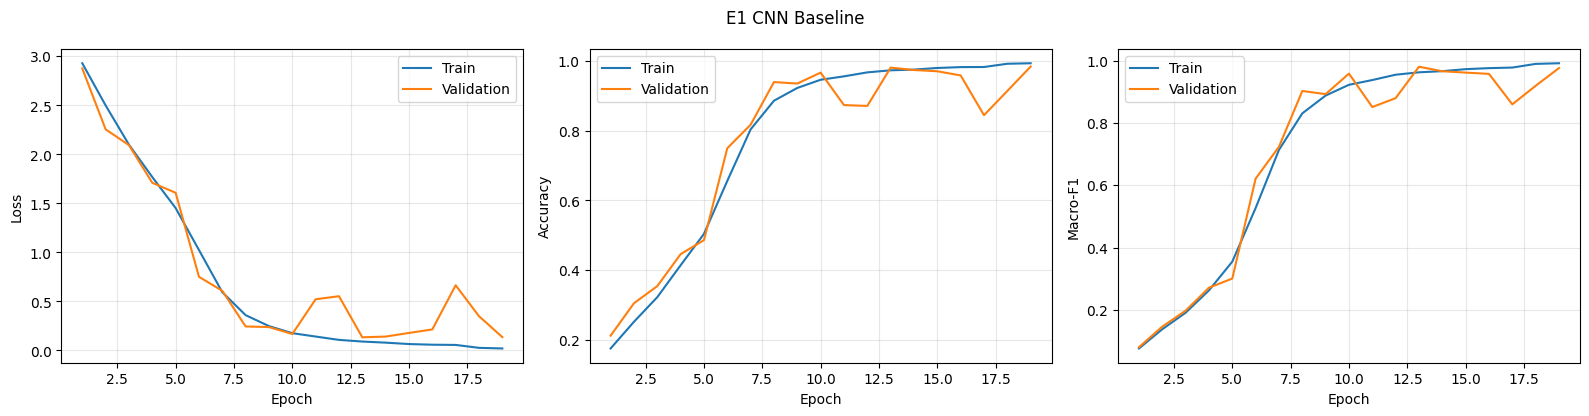

Đã lưu learning curves: /kaggle/working/gtsrb_results_staged_10models/E1_CNN_Baseline.png
Parameters: 1211659
Trainable: 1211659
Training time: 43.0 minutes


In [24]:
# E1
train_loader, val_loader, test_loader = make_loaders(use_augmentation=True)

seed_everything(SEED)
cnn = CNNBaseline(NUM_CLASSES).to(DEVICE)

cnn, hist_cnn, time_cnn = fit_model(
    cnn,
    train_loader,
    val_loader,
    epochs=EPOCHS_CNN,
    lr=LR_CNN,
    model_name="E1_CNN_Baseline",
    resume_from=maybe_resume_path("E1_CNN_Baseline")
)

plot_history(hist_cnn, "E1 CNN Baseline")

print("Parameters:", count_parameters(cnn))
print("Trainable:", count_trainable_parameters(cnn))
print("Training time:", round(time_cnn / 60, 2), "minutes")

# 11. E2 — ResNet50 Transfer Learning

Đóng băng backbone ResNet50 pretrained và huấn luyện classifier cuối. Đây là cấu hình đo hiệu quả khi tận dụng đặc trưng ImageNet mà không cập nhật phần backbone.

[SKIP] E2_ResNet50_TransferLearning: đã train xong (best epoch 20, val Macro-F1 0.7187); nạp best checkpoint, không train lại.


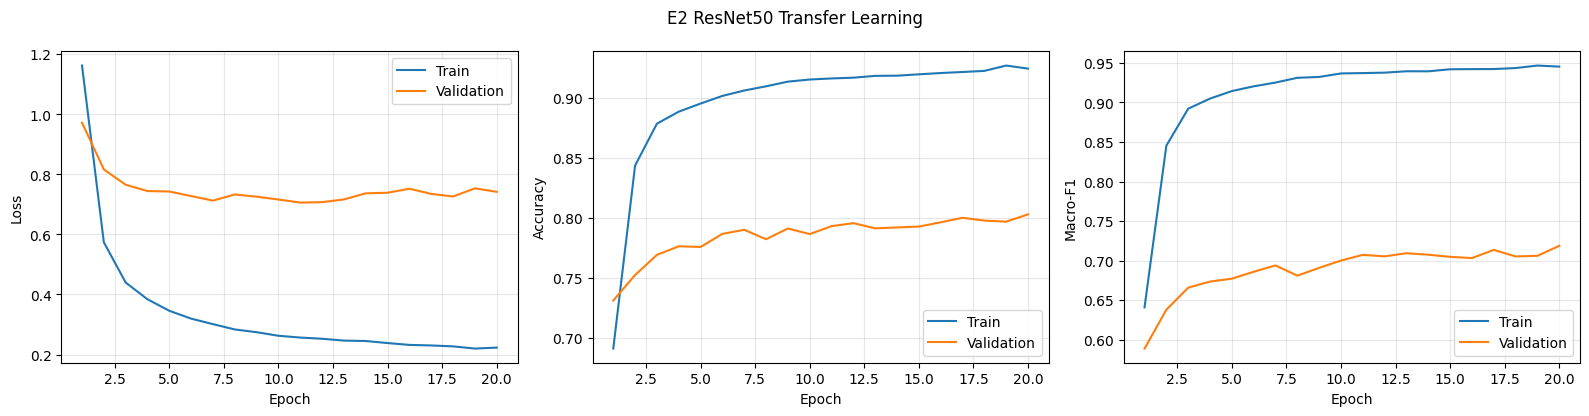

Đã lưu learning curves: /kaggle/working/gtsrb_results_staged_10models/E2_ResNet50_Transfer_Learning.png
Total parameters: 23596139
Trainable parameters: 88107
Training time: 53.08 minutes


In [28]:
train_loader, val_loader, test_loader = make_loaders(use_augmentation=True)

seed_everything(SEED)
resnet50 = build_resnet50().to(DEVICE)

resnet50, hist_rn_tl, time_rn_tl = fit_model(
    resnet50,
    train_loader,
    val_loader,
    epochs=EPOCHS_TL,
    lr=LR_HEAD,
    model_name="E2_ResNet50_TransferLearning",
    resume_from=maybe_resume_path("E2_ResNet50_TransferLearning")
)

plot_history(hist_rn_tl, "E2 ResNet50 Transfer Learning")

print("Total parameters:", count_parameters(resnet50))
print("Trainable parameters:", count_trainable_parameters(resnet50))
print("Training time:", round(time_rn_tl / 60, 2), "minutes")

# 12. E3 — ResNet50 Fine-tuning

Khởi đầu từ checkpoint Transfer Learning tốt nhất rồi mở khóa các tầng cuối đã cấu hình. Learning rate backbone thấp hơn classifier để giảm nguy cơ làm biến đổi quá mạnh các đặc trưng pretrained. So sánh với E2 bằng Validation Macro-F1, thời gian và số tham số được cập nhật.

Trainable parameters: 22151211
[E3_ResNet50_FineTuning] bắt đầu train: tối đa 10 epoch | lr=1e-05 | trainable=22,151,211 | train=33,592 ảnh, val=5,609 ảnh


Epoch 1/10 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

Epoch 1/10 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 01/10 | train loss=0.5148 acc=0.8476 F1=0.8360 | val loss=0.3916 acc=0.8889 F1=0.8239 | lr=1.00e-05, 1.00e-04 | 149s/epoch, còn tối đa ~22.3 phút | GPU 1.1GB ★ best


Epoch 2/10 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

...

Epoch 9/10 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 09/10 | train loss=0.0064 acc=0.9978 F1=0.9979 | val loss=0.1976 acc=0.9620 F1=0.9333 | lr=1.00e-05, 1.00e-04 | 171s/epoch, còn tối đa ~2.8 phút | GPU 1.1GB ★ best


Epoch 10/10 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

Epoch 10/10 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 10/10 | train loss=0.0053 acc=0.9983 F1=0.9984 | val loss=0.2191 acc=0.9590 F1=0.9280 | lr=1.00e-05, 1.00e-04 | 171s/epoch, còn tối đa ~0.0 phút | GPU 1.1GB (chưa cải thiện 1/5)
Best epoch: 9 | best validation Macro-F1: 0.9333
[ResNet50 seed 42] TL=0.7187 | FT=0.9333 | Δ=+21.461 điểm % | FT tốt hơn TL: True


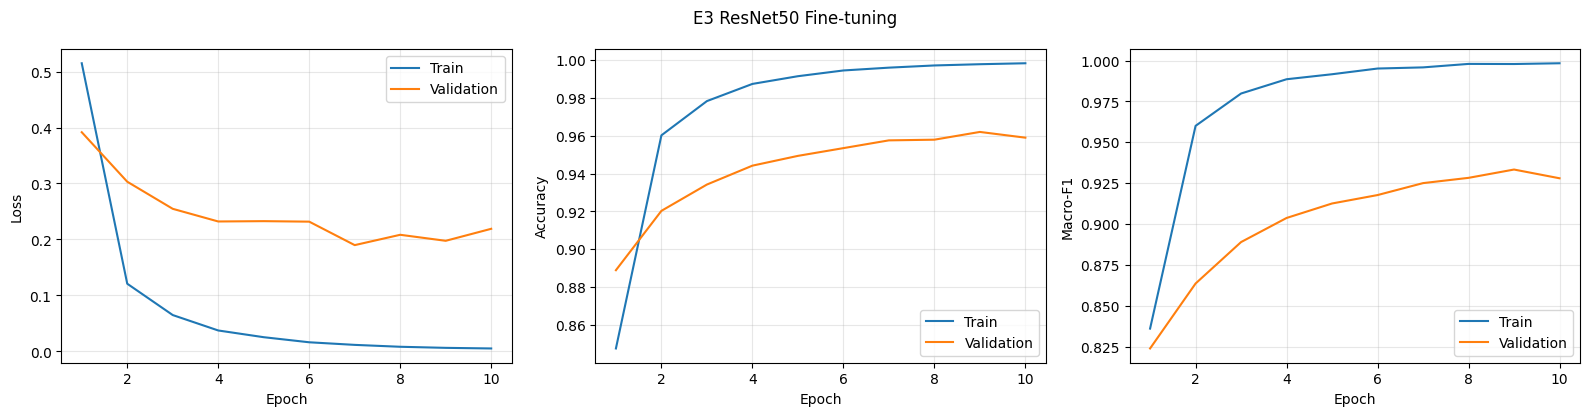

Đã lưu learning curves: /kaggle/working/gtsrb_results_staged_10models/E3_ResNet50_Fine-tuning.png


PosixPath('/kaggle/working/gtsrb_results_staged_10models/E3_ResNet50_Fine-tuning.png')

In [29]:
def unfreeze_resnet_last_blocks(model, n_blocks=2):
    # Freeze toàn bộ trước
    for p in model.parameters():
        p.requires_grad = False

    # Luôn train classifier
    for p in model.fc.parameters():
        p.requires_grad = True

    # Mở các layer cuối
    if n_blocks >= 1:
        for p in model.layer4.parameters():
            p.requires_grad = True
    if n_blocks >= 2:
        for p in model.layer3.parameters():
            p.requires_grad = True

unfreeze_resnet_last_blocks(resnet50, n_blocks=2)

print("Trainable parameters:", count_trainable_parameters(resnet50))

resnet_ft_param_groups = [
    {"params": list(resnet50.layer3.parameters()) + list(resnet50.layer4.parameters()), "lr": LR_BACKBONE_FINE},
    {"params": list(resnet50.fc.parameters()), "lr": LR_HEAD_FINE},
]
resnet50, hist_rn_ft, time_rn_ft = fit_model(
    resnet50, train_loader, val_loader,
    epochs=EPOCHS_FT, lr=LR_BACKBONE_FINE,
    model_name="E3_ResNet50_FineTuning",
    param_groups=resnet_ft_param_groups, patience=EARLY_STOP_PATIENCE,
    resume_from=maybe_resume_path("E3_ResNet50_FineTuning")
)

log_ft_vs_tl("ResNet50", hist_rn_tl, hist_rn_ft, model=resnet50, seed=SEED)
plot_history(hist_rn_ft, "E3 ResNet50 Fine-tuning")

# 13. E4 — EfficientNet-B0 Transfer Learning

Đóng băng backbone EfficientNet-B0 pretrained và chỉ huấn luyện classifier. Thiết lập này tạo đối chứng TL với ResNet50 trong cùng giao thức dữ liệu và đánh giá.

[E4_EfficientNetB0_TransferLearning] bắt đầu train: tối đa 20 epoch | lr=0.001 | trainable=55,083 | train=33,592 ảnh, val=5,609 ảnh


Epoch 1/20 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

Epoch 1/20 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 01/20 | train loss=1.1805 acc=0.6662 F1=0.6116 | val loss=0.9931 acc=0.6994 F1=0.5709 | lr=1.00e-03 | 150s/epoch, còn tối đa ~47.6 phút | GPU 1.1GB ★ best


Epoch 2/20 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

...

Epoch 16/20 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 16/20 | train loss=0.4181 acc=0.8541 F1=0.8708 | val loss=0.7681 acc=0.7720 F1=0.6612 | lr=5.00e-04 | 159s/epoch, còn tối đa ~10.2 phút | GPU 1.1GB (chưa cải thiện 5/6)


Epoch 17/20 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

Epoch 17/20 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 17/20 | train loss=0.4083 acc=0.8577 F1=0.8751 | val loss=0.7553 acc=0.7720 F1=0.6625 | lr=5.00e-04 | 160s/epoch, còn tối đa ~7.7 phút | GPU 1.1GB (chưa cải thiện 6/6)
Early stopping: Val Macro-F1 không cải thiện sau 6 epoch.
Best epoch: 11 | best validation Macro-F1: 0.6752


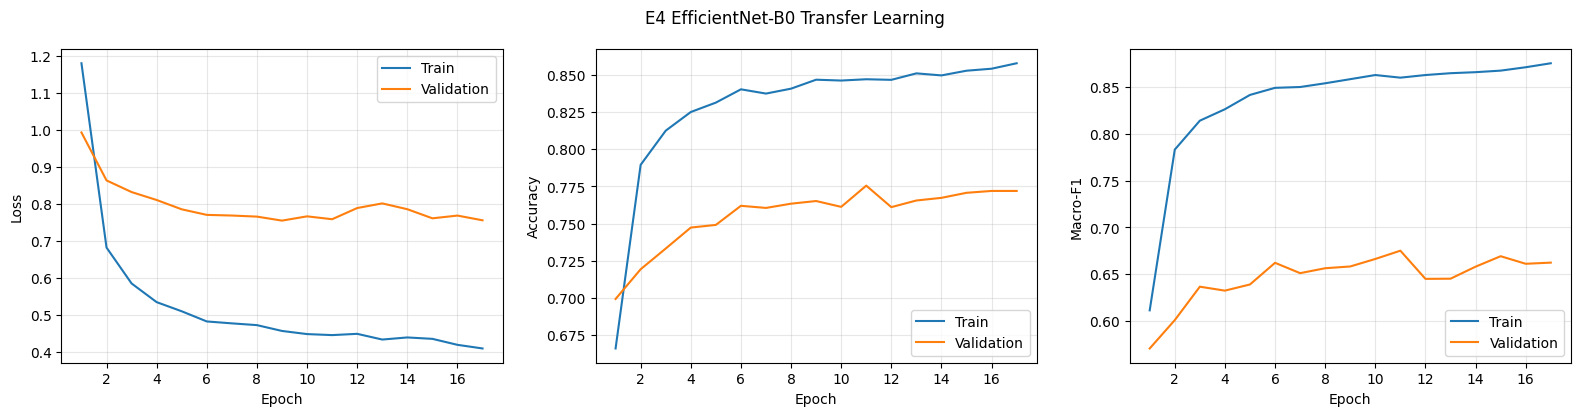

Đã lưu learning curves: /kaggle/working/gtsrb_results_staged_10models/E4_EfficientNet-B0_Transfer_Learning.png
Total parameters: 4062631
Trainable parameters: 55083


In [30]:
train_loader, val_loader, test_loader = make_loaders(use_augmentation=True)

seed_everything(SEED)
efficientnet = build_efficientnet_b0().to(DEVICE)

efficientnet, hist_eff_tl, time_eff_tl = fit_model(
    efficientnet,
    train_loader,
    val_loader,
    epochs=EPOCHS_TL,
    lr=LR_HEAD,
    model_name="E4_EfficientNetB0_TransferLearning",
    resume_from=maybe_resume_path("E4_EfficientNetB0_TransferLearning")
)

plot_history(hist_eff_tl, "E4 EfficientNet-B0 Transfer Learning")

print("Total parameters:", count_parameters(efficientnet))
print("Trainable parameters:", count_trainable_parameters(efficientnet))

# 14. E5 — EfficientNet-B0 Fine-tuning

Khởi đầu từ checkpoint EfficientNet-B0 Transfer Learning và mở khóa các block cuối theo cấu hình. Đánh giá lợi ích bổ sung của Fine-tuning so với E4 cùng chi phí huấn luyện.

Trainable parameters: 3210823
[E5_EfficientNetB0_FineTuning] bắt đầu train: tối đa 10 epoch | lr=1e-05 | trainable=3,210,823 | train=33,592 ảnh, val=5,609 ảnh


Epoch 1/10 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

Epoch 1/10 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 01/10 | train loss=0.9999 acc=0.7092 F1=0.6709 | val loss=0.7437 acc=0.7616 F1=0.6496 | lr=1.00e-05, 1.00e-04 | 145s/epoch, còn tối đa ~21.8 phút | GPU 1.1GB ★ best


Epoch 2/10 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

...

Epoch 09/10 | train loss=0.0938 acc=0.9688 F1=0.9678 | val loss=0.2581 acc=0.9160 F1=0.8594 | lr=1.00e-05, 1.00e-04 | 166s/epoch, còn tối đa ~2.7 phút | GPU 1.1GB ★ best


Epoch 10/10 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c3f8607ab60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c3f8607ab60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7c3f8607ab60>

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/d

Epoch 10/10 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 10/10 | train loss=0.0773 acc=0.9742 F1=0.9739 | val loss=0.2384 acc=0.9239 F1=0.8664 | lr=1.00e-05, 1.00e-04 | 168s/epoch, còn tối đa ~0.0 phút | GPU 1.1GB ★ best
Best epoch: 10 | best validation Macro-F1: 0.8664
[EfficientNet-B0 seed 42] TL=0.6752 | FT=0.8664 | Δ=+19.120 điểm % | FT tốt hơn TL: True


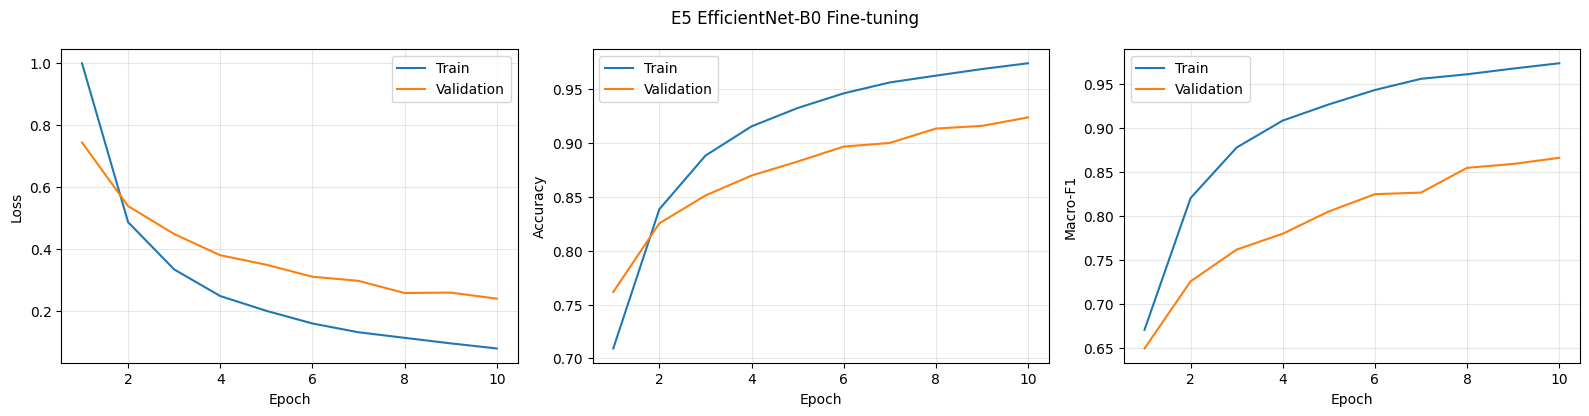

Đã lưu learning curves: /kaggle/working/gtsrb_results_staged_10models/E5_EfficientNet-B0_Fine-tuning.png


PosixPath('/kaggle/working/gtsrb_results_staged_10models/E5_EfficientNet-B0_Fine-tuning.png')

In [31]:
def unfreeze_efficientnet_last_blocks(model):
    for p in model.parameters():
        p.requires_grad = False

    for p in model.classifier.parameters():
        p.requires_grad = True

    # Mở các block cuối của EfficientNet
    for p in model.features[-3:].parameters():
        p.requires_grad = True

unfreeze_efficientnet_last_blocks(efficientnet)

print("Trainable parameters:", count_trainable_parameters(efficientnet))

efficientnet_ft_param_groups = [
    {"params": list(efficientnet.features[-3:].parameters()), "lr": LR_BACKBONE_FINE},
    {"params": list(efficientnet.classifier.parameters()), "lr": LR_HEAD_FINE},
]
efficientnet, hist_eff_ft, time_eff_ft = fit_model(
    efficientnet, train_loader, val_loader,
    epochs=EPOCHS_FT, lr=LR_BACKBONE_FINE,
    model_name="E5_EfficientNetB0_FineTuning",
    param_groups=efficientnet_ft_param_groups, patience=EARLY_STOP_PATIENCE,
    resume_from=maybe_resume_path("E5_EfficientNetB0_FineTuning")
)

log_ft_vs_tl("EfficientNet-B0", hist_eff_tl, hist_eff_ft, model=efficientnet, seed=SEED)
plot_history(hist_eff_ft, "E5 EfficientNet-B0 Fine-tuning")

## 15. E6 — ResNet50 Scratch

ResNet50 được khởi tạo ngẫu nhiên (`weights=None`) và **toàn bộ tham số được huấn luyện**. So sánh với ResNet50-TL/FT để tách ảnh hưởng của trọng số ImageNet khỏi ảnh hưởng của kiến trúc. Vì đây là backbone sâu khởi tạo ngẫu nhiên, thời gian train có thể cao hơn TL; dùng cùng split, augmentation, image size và batch size.


[E6_ResNet50_Scratch] bắt đầu train: tối đa 60 epoch | lr=0.0003 | trainable=23,596,139 | train=33,592 ảnh, val=5,609 ảnh


Epoch 1/60 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

Epoch 1/60 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 01/60 | train loss=1.6893 acc=0.5063 F1=0.4166 | val loss=0.4681 acc=0.8561 F1=0.7682 | lr=3.00e-04 | 176s/epoch, còn tối đa ~173.0 phút | GPU 2.2GB ★ best


Epoch 2/60 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

...

Epoch 13/60 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 13/60 | train loss=0.0044 acc=0.9988 F1=0.9987 | val loss=0.0557 acc=0.9929 F1=0.9917 | lr=1.50e-04 | 173s/epoch, còn tối đa ~150.5 phút | GPU 2.2GB (chưa cải thiện 5/6)


Epoch 14/60 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

Epoch 14/60 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 14/60 | train loss=0.0040 acc=0.9988 F1=0.9984 | val loss=0.0976 acc=0.9913 F1=0.9879 | lr=1.50e-04 | 193s/epoch, còn tối đa ~147.3 phút | GPU 2.2GB (chưa cải thiện 6/6)
Early stopping: Val Macro-F1 không cải thiện sau 6 epoch.
Best epoch: 8 | best validation Macro-F1: 0.9917


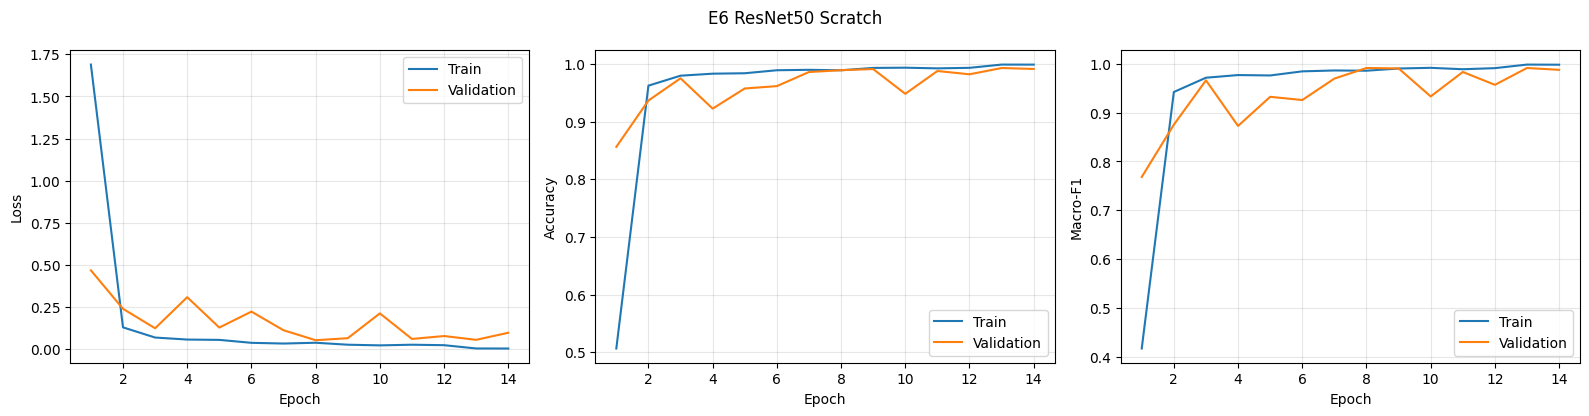

Đã lưu learning curves: /kaggle/working/gtsrb_results_staged_10models/E6_ResNet50_Scratch.png
Total parameters: 23596139
Trainable parameters: 23596139
Training time: 44.84 minutes


In [32]:
# E6 — ResNet50 Scratch
train_loader, val_loader, test_loader = make_loaders(use_augmentation=True)
seed_everything(SEED)
resnet50_scratch = build_resnet50(pretrained=False).to(DEVICE)
for p in resnet50_scratch.parameters():
    p.requires_grad = True
resnet50_scratch, hist_rn_scratch, time_rn_scratch = fit_model(
    resnet50_scratch, train_loader, val_loader,
    epochs=EPOCHS_SCRATCH_BACKBONE, lr=LR_SCRATCH_BACKBONE,
    model_name="E6_ResNet50_Scratch", patience=EARLY_STOP_PATIENCE,
    resume_from=maybe_resume_path("E6_ResNet50_Scratch")
)
plot_history(hist_rn_scratch, "E6 ResNet50 Scratch")
print("Total parameters:", count_parameters(resnet50_scratch))
print("Trainable parameters:", count_trainable_parameters(resnet50_scratch))
print("Training time:", round(time_rn_scratch / 60, 2), "minutes")


## 16. E7 — EfficientNet-B0 Scratch

EfficientNet-B0 được khởi tạo ngẫu nhiên (`weights=None`) và huấn luyện toàn bộ tham số. Đây là đối chứng trực tiếp với EfficientNet-B0-TL/FT. Không dùng checkpoint ImageNet ở cấu hình Scratch; chỉ dùng cùng kiến trúc và classifier đầu ra 43 lớp.


[E7_EfficientNetB0_Scratch] bắt đầu train: tối đa 60 epoch | lr=0.0003 | trainable=4,062,631 | train=33,592 ảnh, val=5,609 ảnh


Epoch 1/60 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

Epoch 1/60 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 01/60 | train loss=1.7077 acc=0.4947 F1=0.3983 | val loss=0.4287 acc=0.8709 F1=0.7912 | lr=3.00e-04 | 164s/epoch, còn tối đa ~161.5 phút | GPU 2.2GB ★ best


Epoch 2/60 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

...

Epoch 20/60 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 20/60 | train loss=0.0027 acc=0.9991 F1=0.9989 | val loss=0.0755 acc=0.9913 F1=0.9868 | lr=1.50e-04 | 175s/epoch, còn tối đa ~115.5 phút | GPU 2.2GB (chưa cải thiện 5/6)


Epoch 21/60 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

Epoch 21/60 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 21/60 | train loss=0.0026 acc=0.9994 F1=0.9995 | val loss=0.0672 acc=0.9922 F1=0.9889 | lr=1.50e-04 | 175s/epoch, còn tối đa ~112.6 phút | GPU 2.2GB (chưa cải thiện 6/6)
Early stopping: Val Macro-F1 không cải thiện sau 6 epoch.
Best epoch: 15 | best validation Macro-F1: 0.9945


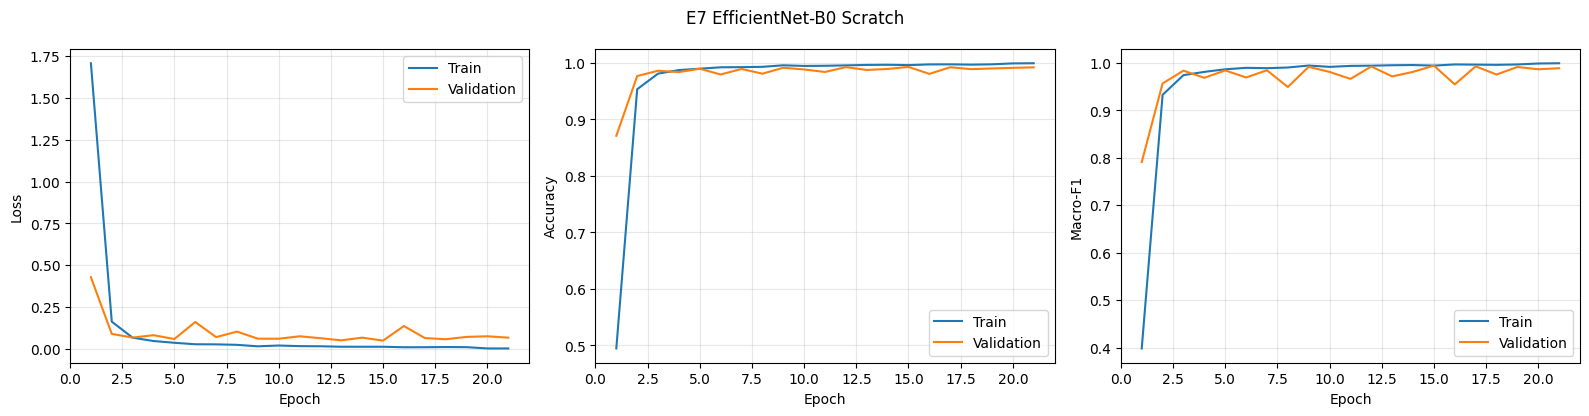

Đã lưu learning curves: /kaggle/working/gtsrb_results_staged_10models/E7_EfficientNet-B0_Scratch.png
Total parameters: 4062631
Trainable parameters: 4062631
Training time: 60.64 minutes


In [33]:
# E7 — EfficientNet-B0 Scratch
train_loader, val_loader, test_loader = make_loaders(use_augmentation=True)
seed_everything(SEED)
efficientnet_scratch = build_efficientnet_b0(pretrained=False).to(DEVICE)
for p in efficientnet_scratch.parameters():
    p.requires_grad = True
efficientnet_scratch, hist_eff_scratch, time_eff_scratch = fit_model(
    efficientnet_scratch, train_loader, val_loader,
    epochs=EPOCHS_SCRATCH_BACKBONE, lr=LR_SCRATCH_BACKBONE,
    model_name="E7_EfficientNetB0_Scratch", patience=EARLY_STOP_PATIENCE,
    resume_from=maybe_resume_path("E7_EfficientNetB0_Scratch")
)
plot_history(hist_eff_scratch, "E7 EfficientNet-B0 Scratch")
print("Total parameters:", count_parameters(efficientnet_scratch))
print("Trainable parameters:", count_trainable_parameters(efficientnet_scratch))
print("Training time:", round(time_eff_scratch / 60, 2), "minutes")


## E8 — ConvNeXt-Tiny Scratch

ConvNeXt-Tiny được khởi tạo ngẫu nhiên (`weights=None`) và huấn luyện toàn bộ tham số. Đây là đối chứng để đo hiệu quả của kiến trúc hiện đại khi không có kiến thức ImageNet. ConvNeXt-Tiny có thể tốn VRAM/thời gian hơn EfficientNet-B0; theo dõi OOM và giảm batch size đồng nhất cho tất cả mô hình nếu cần.


[E8_ConvNeXtTiny_Scratch] bắt đầu train: tối đa 60 epoch | lr=0.0003 | trainable=27,853,195 | train=33,592 ảnh, val=5,609 ảnh


Epoch 1/60 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

Epoch 1/60 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 01/60 | train loss=2.3083 acc=0.3100 F1=0.1875 | val loss=1.5189 acc=0.5238 F1=0.2968 | lr=3.00e-04 | 211s/epoch, còn tối đa ~207.3 phút | GPU 3.0GB ★ best


Epoch 2/60 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

...

Epoch 21/60 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 21/60 | train loss=0.0043 acc=0.9988 F1=0.9986 | val loss=0.0615 acc=0.9888 F1=0.9818 | lr=1.50e-04 | 199s/epoch, còn tối đa ~138.8 phút | GPU 3.0GB (chưa cải thiện 5/6)


Epoch 22/60 [train]:   0%|          | 0/1050 [00:00<?, ?it/s]

Epoch 22/60 [val]:   0%|          | 0/176 [00:00<?, ?it/s]

Epoch 22/60 | train loss=0.0071 acc=0.9979 F1=0.9975 | val loss=0.0666 acc=0.9911 F1=0.9895 | lr=1.50e-04 | 198s/epoch, còn tối đa ~134.8 phút | GPU 3.0GB (chưa cải thiện 6/6)
Early stopping: Val Macro-F1 không cải thiện sau 6 epoch.
Best epoch: 16 | best validation Macro-F1: 0.9943


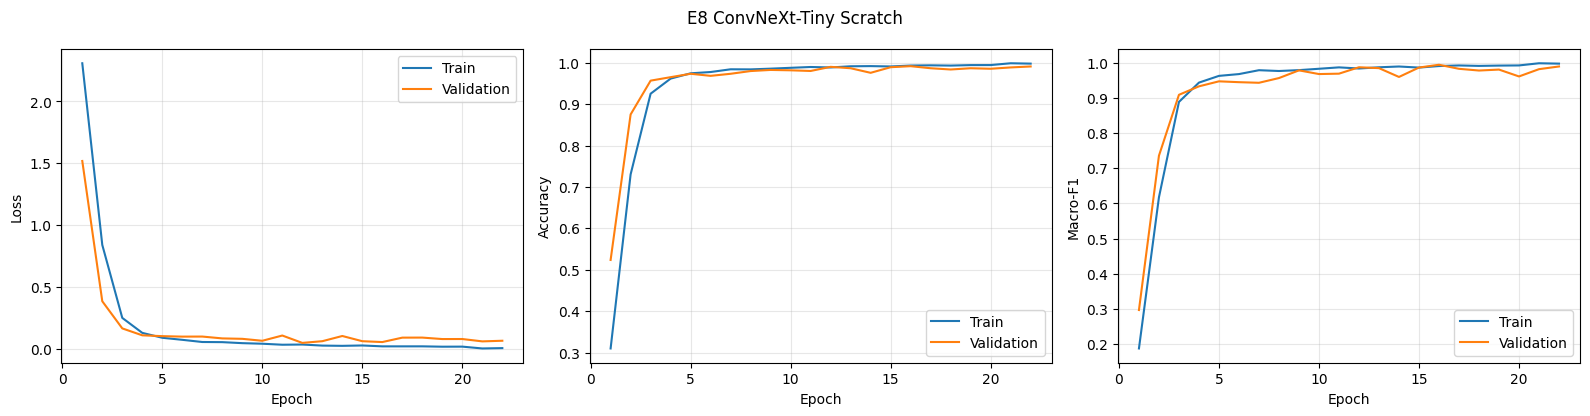

Đã lưu learning curves: /kaggle/working/gtsrb_results_staged_10models/E8_ConvNeXt-Tiny_Scratch.png
Total parameters: 27853195
Trainable parameters: 27853195
Training time: 78.22 minutes


In [34]:
# E8 — ConvNeXt-Tiny Scratch
train_loader, val_loader, test_loader = make_loaders(use_augmentation=True)
seed_everything(SEED)
convnext_scratch = build_convnext_tiny(pretrained=False).to(DEVICE)
for p in convnext_scratch.parameters():
    p.requires_grad = True
convnext_scratch, hist_cnx_scratch, time_cnx_scratch = fit_model(
    convnext_scratch, train_loader, val_loader,
    epochs=EPOCHS_SCRATCH_BACKBONE, lr=LR_SCRATCH_BACKBONE,
    model_name="E8_ConvNeXtTiny_Scratch", patience=EARLY_STOP_PATIENCE,
    resume_from=maybe_resume_path("E8_ConvNeXtTiny_Scratch")
)
plot_history(hist_cnx_scratch, "E8 ConvNeXt-Tiny Scratch")
print("Total parameters:", count_parameters(convnext_scratch))
print("Trainable parameters:", count_trainable_parameters(convnext_scratch))
print("Training time:", round(time_cnx_scratch / 60, 2), "minutes")


## E9 — ConvNeXt-Tiny Transfer Learning

Sử dụng trọng số ImageNet và đóng băng toàn bộ backbone; chỉ classifier 43 lớp được cập nhật. Đối chiếu trực tiếp với ConvNeXt-Tiny Scratch để đo lợi ích của pretrained weights.


In [5]:
# E9 — ConvNeXt-Tiny Transfer Learning
train_loader, val_loader, test_loader = make_loaders(use_augmentation=True)
seed_everything(SEED)
convnext_tiny = build_convnext_tiny(pretrained=True).to(DEVICE)
convnext_tiny, hist_cnx_tl, time_cnx_tl = fit_model(
    convnext_tiny, train_loader, val_loader,
    epochs=EPOCHS_TL, lr=LR_HEAD,
    model_name="E9_ConvNeXtTiny_TransferLearning",
    resume_from=maybe_resume_path("E9_ConvNeXtTiny_TransferLearning")
)
plot_history(hist_cnx_tl, "E9 ConvNeXt-Tiny Transfer Learning")
print("Total parameters:", count_parameters(convnext_tiny))
print("Trainable parameters:", count_trainable_parameters(convnext_tiny))


NameError: name 'make_loaders' is not defined

## E10 — ConvNeXt-Tiny Fine-tuning

Tiếp tục từ checkpoint TL tốt nhất, mở khóa stage cuối (`features[-1]`) cùng classifier. Learning rate của backbone thấp hơn learning rate của head. Khi diễn giải, so sánh E10 với E9 để định lượng lợi ích bổ sung của fine-tuning.


In [ ]:
# E10 — ConvNeXt-Tiny Fine-tuning
for p in convnext_tiny.parameters():
    p.requires_grad = False
for p in convnext_tiny.features[-1].parameters():
    p.requires_grad = True
for p in convnext_tiny.classifier.parameters():
    p.requires_grad = True
print("Trainable parameters:", count_trainable_parameters(convnext_tiny))
convnext_ft_param_groups = [
    {"params": list(convnext_tiny.features[-1].parameters()), "lr": LR_BACKBONE_FINE},
    {"params": list(convnext_tiny.classifier.parameters()), "lr": LR_HEAD_FINE},
]
convnext_tiny, hist_cnx_ft, time_cnx_ft = fit_model(
    convnext_tiny, train_loader, val_loader,
    epochs=EPOCHS_FT, lr=LR_BACKBONE_FINE,
    model_name="E10_ConvNeXtTiny_FineTuning",
    param_groups=convnext_ft_param_groups, patience=EARLY_STOP_PATIENCE,
    resume_from=maybe_resume_path("E10_ConvNeXtTiny_FineTuning")
)
log_ft_vs_tl("ConvNeXt-Tiny", hist_cnx_tl, hist_cnx_ft, model=convnext_tiny, seed=SEED)
plot_history(hist_cnx_ft, "E10 ConvNeXt-Tiny Fine-tuning")


## 17. Hàm đánh giá và nguyên tắc lựa chọn

Các hàm dự đoán trả về nhãn thật, nhãn dự đoán, xác suất và thông tin cần cho phân tích sau huấn luyện. **Validation** được dùng để so sánh và chọn cấu hình; Test chỉ được dùng trong phần đánh giá cuối theo giao thức đã định trước.


In [ ]:
@torch.no_grad()
def predict_model(model, loader):
    """Đo thời gian toàn pipeline evaluation, gồm DataLoader và forward pass."""
    model.eval()
    y_true, y_pred, y_prob, paths = [], [], [], []
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for images, labels, batch_paths in tqdm(loader, leave=False):
        images = images.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(images)
        probs = torch.softmax(logits.float(), dim=1)
        y_true.extend(labels.numpy().tolist())
        y_pred.extend(probs.argmax(dim=1).cpu().numpy().tolist())
        y_prob.extend(probs.cpu().numpy().tolist())
        paths.extend(batch_paths)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    return np.array(y_true), np.array(y_pred), np.array(y_prob), paths, elapsed

def benchmark_model_latency(model, warmup=30, runs=200):
    """Model-only batch=1 latency; returns median milliseconds in evaluation precision."""
    return benchmark_latency_stats(model, warmup=warmup, runs=runs, amp=USE_AMP)["median_ms"]

def evaluate_model(model, loader, model_name):
    y_true, y_pred, y_prob, paths, infer_time = predict_model(model, loader)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
    )
    top5_indices = np.argsort(y_prob, axis=1)[:, -min(5, y_prob.shape[1]):]
    top5_accuracy = float(np.mean([int(y) in row for y, row in zip(y_true, top5_indices)]))
    result = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "top5_accuracy": top5_accuracy,
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
        "pipeline_eval_time_sec": infer_time,
        "pipeline_ms_per_image": infer_time / max(len(y_true), 1) * 1000,
        "pipeline_images_per_sec": len(y_true) / max(infer_time, 1e-12),
        "parameters": count_parameters(model),
        "trainable_parameters": count_trainable_parameters(model)
    }
    return result, y_true, y_pred, y_prob, paths

def load_saved_model_state(model, checkpoint_path):
    try:
        payload = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
    except TypeError:
        payload = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(payload["state_dict"])
    return model

# Recreate TL checkpoints separately. Without this, the in-memory model objects are overwritten by FT.
resnet50_tl = load_saved_model_state(
    build_resnet50(pretrained=False).to(DEVICE), OUTPUT_DIR / "E2_ResNet50_TransferLearning_best.pt"
)
efficientnet_tl = load_saved_model_state(
    build_efficientnet_b0(pretrained=False).to(DEVICE), OUTPUT_DIR / "E4_EfficientNetB0_TransferLearning_best.pt"
)

models_final = {
    "CNN": cnn,
    "ResNet50-Scratch": resnet50_scratch,
    "ResNet50-TL": resnet50_tl,
    "ResNet50-FT": resnet50,
    "EfficientNet-B0-Scratch": efficientnet_scratch,
    "EfficientNet-B0-TL": efficientnet_tl,
    "EfficientNet-B0-FT": efficientnet,
    "ConvNeXt-Tiny-Scratch": convnext_scratch,
    "ConvNeXt-Tiny-TL": load_saved_model_state(build_convnext_tiny(pretrained=False).to(DEVICE), OUTPUT_DIR / "E9_ConvNeXtTiny_TransferLearning_best.pt"),
    "ConvNeXt-Tiny-FT": convnext_tiny,
}

# Model selection is based on Validation Macro-F1 only.
validation_results, validation_cache = [], {}
for name, model in models_final.items():
    result, y_true_val, y_pred_val, y_prob_val, paths_val = evaluate_model(model, val_loader, name)
    validation_results.append(result)
    validation_cache[name] = (y_true_val, y_pred_val, y_prob_val, paths_val)
validation_results_df = pd.DataFrame(validation_results).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(validation_results_df)
best_model_name = validation_results_df.iloc[0]["model"]
print("Best model selected using Validation Macro-F1:", best_model_name)
final_model_name = best_model_name   # có thể được thay bằng lựa chọn theo mean đa-seed ở mục 28.1 (chỉ dùng Validation)

# Efficiency benchmark is measured once per configuration after warm-up.
latency_rows = []
for name, model in models_final.items():
    _lat = benchmark_latency_stats(model, warmup=30, runs=200, amp=USE_AMP)
    latency_rows.append({"model": name,
                         "model_only_latency_ms_batch1": _lat["median_ms"],
                         "model_only_latency_p95_ms_batch1": _lat["p95_ms"],
                         "model_only_latency_mean_ms_batch1": _lat["mean_ms"],
                         "latency_precision": "AMP-fp16" if USE_AMP else "FP32",
                         "latency_device": str(DEVICE)})
latency_df = pd.DataFrame(latency_rows)
validation_results_df = validation_results_df.merge(latency_df, on="model", how="left")


## 16. Classification report trên Validation

Chọn mô hình theo Validation Macro-F1 rồi kiểm tra Precision/Recall/F1 theo lớp trên **Validation**. Báo cáo theo lớp giúp nhận diện lớp khó ngay trong quá trình phát triển; kết quả này không thay thế đánh giá Test cuối cùng.

In [ ]:
best_model_name = validation_results_df.sort_values("f1_macro", ascending=False).iloc[0]["model"]

y_true, y_pred, y_prob, paths = validation_cache[best_model_name]

report = classification_report(
    y_true, y_pred,
    labels=list(range(NUM_CLASSES)),
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T
report_df.index.name = "class_id_or_summary"
report_df = report_df.reset_index()
report_df["class_name"] = report_df["class_id_or_summary"].map(
    lambda value: CLASS_LABEL_NAMES.get(str(value), "")
)
display(report_df.round(4))
print("Best model:", best_model_name)

# 17. Confusion Matrix trên Validation

Confusion matrix cho thấy lớp thật nào thường bị dự đoán thành lớp nào. Nên quan sát các cặp biển báo dễ nhầm, nhưng cần đối chiếu với support của từng lớp để tránh kết luận từ số lượng mẫu quá ít.

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

plt.figure(figsize=(16, 13))
sns.heatmap(cm, cmap="Blues", annot=False, square=True)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

In [ ]:
# Top các cặp lớp bị nhầm
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm_off[i, j] > 0:
            pairs.append((i, j, cm_off[i, j]))

pairs_df = pd.DataFrame(
    sorted(pairs, key=lambda x: x[2], reverse=True)[:20],
    columns=["true_class", "predicted_class", "count"]
)

pairs_df["true_class_name"] = pairs_df["true_class"].map(lambda x: CLASS_LABEL_NAMES.get(str(x), ""))
pairs_df["predicted_class_name"] = pairs_df["predicted_class"].map(lambda x: CLASS_LABEL_NAMES.get(str(x), ""))
display(pairs_df)
pairs_df.to_csv(OUTPUT_DIR / "top_confused_class_pairs.csv", index=False)

# 18. Error Analysis trên Validation

Hiển thị các ảnh dự đoán sai cùng nhãn thật, nhãn dự đoán và độ tin cậy khi có. Khi thảo luận, xem xét các nguyên nhân có thể như kích thước biển báo, độ mờ, điều kiện sáng và sự giống nhau về hình dạng/ký hiệu.

Các trường hợp hiển thị là ví dụ định tính, không đủ để kết luận một nguyên nhân là phổ biến nếu chưa có thống kê hỗ trợ.

In [ ]:
wrong_idx = np.where(y_true != y_pred)[0]

print("Số mẫu dự đoán sai:", len(wrong_idx))
print("Error rate:", round(len(wrong_idx) / len(y_true), 4))

show_n = min(25, len(wrong_idx))

fig, axes = plt.subplots(5, 5, figsize=(15, 15))
for ax in axes.ravel():
    ax.axis("off")

for ax, idx in zip(axes.ravel(), wrong_idx[:show_n]):
    with Image.open(paths[idx]) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(
        f"True: {y_true[idx]} | Pred: {y_pred[idx]}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

# 19. Kích thước mô hình

Đo số tham số và dung lượng tệp weights chỉ chứa `state_dict`. Cần phân biệt **số tham số**, **số tham số trainable** và **dung lượng file**; chúng không phải cùng một chỉ số. So sánh latency cần thực hiện trong cùng môi trường phần cứng, input size, batch size và quy trình warm-up.

In [ ]:
def file_size_mb(path):
    return Path(path).stat().st_size / (1024 ** 2) if Path(path).exists() else np.nan

checkpoint_map = {
    "CNN": OUTPUT_DIR / "E1_CNN_Baseline_weights.pt",
    "ResNet50-Scratch": OUTPUT_DIR / "E6_ResNet50_Scratch_weights.pt",
    "ResNet50-TL": OUTPUT_DIR / "E2_ResNet50_TransferLearning_weights.pt",
    "ResNet50-FT": OUTPUT_DIR / "E3_ResNet50_FineTuning_weights.pt",
    "EfficientNet-B0-Scratch": OUTPUT_DIR / "E7_EfficientNetB0_Scratch_weights.pt",
    "EfficientNet-B0-TL": OUTPUT_DIR / "E4_EfficientNetB0_TransferLearning_weights.pt",
    "EfficientNet-B0-FT": OUTPUT_DIR / "E5_EfficientNetB0_FineTuning_weights.pt",
    "ConvNeXt-Tiny-Scratch": OUTPUT_DIR / "E8_ConvNeXtTiny_Scratch_weights.pt",
    "ConvNeXt-Tiny-TL": OUTPUT_DIR / "E9_ConvNeXtTiny_TransferLearning_weights.pt",
    "ConvNeXt-Tiny-FT": OUTPUT_DIR / "E10_ConvNeXtTiny_FineTuning_weights.pt",
}

validation_results_df["model_size_mb"] = validation_results_df["model"].map(
    lambda name: file_size_mb(checkpoint_map[name])
)
display(validation_results_df.sort_values("f1_macro", ascending=False).round(4))


# 20. A1 — Ablation: ảnh hưởng của Data Augmentation

So sánh CNN Scratch khi tắt và bật augmentation trên cùng split. Đây là ablation một yếu tố nhằm khảo sát đóng góp của pipeline augmentation; các yếu tố khác cần được giữ nhất quán tối đa.

Nếu chỉ chạy một seed, hãy trình bày đây là kết quả của lần chạy cụ thể, không khái quát thành kết luận chắc chắn về mọi lần huấn luyện.

In [ ]:
# E6A - CNN without augmentation
train_loader_noaug, val_loader_noaug, test_loader_noaug = make_loaders(False)

# Cùng seed/init như E1 để phép so sánh augmentation có kiểm soát hơn.
seed_everything(SEED)
cnn_noaug = CNNBaseline(NUM_CLASSES).to(DEVICE)

cnn_noaug, hist_cnn_noaug, time_cnn_noaug = fit_model(
    cnn_noaug,
    train_loader_noaug,
    val_loader_noaug,
    epochs=EPOCHS_CNN,
    lr=LR_CNN,
    model_name="E6_CNN_NoAug",
    resume_from=maybe_resume_path("E6_CNN_NoAug")
)
plot_history(hist_cnn_noaug, "E6 CNN NoAug")

res_noaug, *_ = evaluate_model(
    cnn_noaug, val_loader_noaug, "CNN_NoAug"
)

res_aug, *_ = evaluate_model(
    cnn, val_loader, "CNN_Aug"
)

augmentation_df = pd.DataFrame([res_noaug, res_aug])
display(augmentation_df[[
    "model", "accuracy", "precision_macro",
    "recall_macro", "f1_macro"
]])
augmentation_df.to_csv(OUTPUT_DIR / "augmentation_ablation.csv", index=False)


## 20.1 Thí nghiệm nhiều seed cho cả mười cấu hình

Một lần chạy không đo được biến thiên do khởi tạo/thứ tự dữ liệu. Với GTSRB, các mô hình tốt đều rất gần nhau nên chênh lệch nhỏ có thể nằm trong dao động giữa các seed. Cell dưới huấn luyện lại **cả mười cấu hình** (CNN, ResNet50 Scratch/TL/FT, EfficientNet-B0 Scratch/TL/FT, ConvNeXt-Tiny Scratch/TL/FT) với các seed trong `SUITE_SEEDS` (mỗi seed một split theo track khi `SPLIT_PER_SEED=True`, cùng siêu tham số) và lưu kết quả Validation/Test từng seed vào `multi_seed/`. Seed `SEED=42` lấy từ các mục E1–E5. Bảng tổng hợp mean ± std nằm ở mục 28.1, sau khi đánh giá Test.

Có cơ chế resume: seed nào đã có tệp kết quả sẽ được bỏ qua. Đặt `RUN_MULTI_SEED_SUITE = False` để bỏ qua (khi đó mọi kết luận chỉ dựa trên một seed).

**Quy tắc Test:** cell này lưu cả kết quả Test của các seed phụ vào `multi_seed/`, nhưng chỉ in ra Validation. Không mở/diễn giải số Test trước mục 28 và không dùng chúng để chọn mô hình.

In [ ]:
SUITE_DIR = OUTPUT_DIR / "multi_seed"
SUITE_DIR.mkdir(parents=True, exist_ok=True)
_SUITE_KEYS = ["accuracy", "top5_accuracy", "precision_macro", "recall_macro", "f1_macro"]
_ALL_MULTI_MODELS = [
    "CNN", "ResNet50-Scratch", "ResNet50-TL", "ResNet50-FT",
    "EfficientNet-B0-Scratch", "EfficientNet-B0-TL", "EfficientNet-B0-FT",
    "ConvNeXt-Tiny-Scratch", "ConvNeXt-Tiny-TL", "ConvNeXt-Tiny-FT"
]

def _suite_row(name, seed, train_seconds, res_val, latency_ms=float("nan")):
    row = {"model": name, "seed": int(seed), "train_seconds": float(train_seconds),
           "latency_ms_batch1": float(latency_ms), "img_size": int(IMG_SIZE), "batch_size": int(BATCH_SIZE)}
    row.update({f"val_{k}": float(res_val[k]) for k in _SUITE_KEYS})
    return row

def run_seed_suite(seed, tag="", selected_models=None):
    """Chạy các model đã chọn trên Validation; không truy vấn official Test.

    Nếu chọn FT, TL cùng kiến trúc cũng được huấn luyện để cung cấp checkpoint khởi đầu
    và tạo đối chứng trực tiếp. Chỉ các mô hình được chọn (cộng TL prerequisite) được ghi.
    """
    selected = set(_ALL_MULTI_MODELS if selected_models is None else selected_models)
    unknown = selected - set(_ALL_MULTI_MODELS)
    if unknown:
        raise ValueError(f"Tên model không hợp lệ trong SELECTED_MULTI_SEED_MODELS: {sorted(unknown)}")
    if not selected:
        raise ValueError("SELECTED_MULTI_SEED_MODELS đang rỗng. Hãy chọn ít nhất một mô hình trước khi bật multi-seed.")
    # Bao gồm TL nếu FT được chọn vì FT phải khởi đầu từ checkpoint TL.
    run_resnet_tl = bool(selected & {"ResNet50-TL", "ResNet50-FT"})
    run_eff_tl = bool(selected & {"EfficientNet-B0-TL", "EfficientNet-B0-FT"})
    run_cnx_tl = bool(selected & {"ConvNeXt-Tiny-TL", "ConvNeXt-Tiny-FT"})
    selection_slug = "|".join(sorted(selected))
    import hashlib
    selection_id = hashlib.md5(selection_slug.encode("utf-8")).hexdigest()[:8]
    out_file = SUITE_DIR / f"suite_{tag}seed{seed}_{selection_id}.json"
    if out_file.exists():
        print(f"Seed {seed}: đã có kết quả, bỏ qua ({out_file.name}). Xóa file nếu muốn chạy lại.")
        return json.loads(out_file.read_text(encoding="utf-8"))
    tr_df_seed, va_df_seed = make_group_split(seed) if SPLIT_PER_SEED else (train_df, val_df)
    tr, va, _ = make_loaders(use_augmentation=True, seed=seed, tr_df=tr_df_seed, va_df=va_df_seed)
    rows = []

    def finish(name, model, seconds, include=True):
        if include:
            rv, *_ = evaluate_model(model, va, name)
            rows.append(_suite_row(name, seed, seconds, rv, benchmark_model_latency(model)))

    if "CNN" in selected:
        seed_everything(seed)
        m = CNNBaseline(NUM_CLASSES).to(DEVICE)
        m, h, t = fit_model(m, tr, va, EPOCHS_CNN, LR_CNN, f"{tag}SEED{seed}_E1_CNN", experiment_seed=seed)
        finish("CNN", m, t); del m

    if "ResNet50-Scratch" in selected:
        seed_everything(seed)
        m = build_resnet50(pretrained=False).to(DEVICE)
        for p in m.parameters(): p.requires_grad = True
        m, h, t = fit_model(m, tr, va, EPOCHS_SCRATCH_BACKBONE, LR_SCRATCH_BACKBONE,
                            f"{tag}SEED{seed}_E6_ResNet50_Scratch", experiment_seed=seed)
        finish("ResNet50-Scratch", m, t); del m
        if DEVICE.type == "cuda": torch.cuda.empty_cache()

    if run_resnet_tl:
        seed_everything(seed)
        m = build_resnet50().to(DEVICE)
        m, h_tl, t_tl = fit_model(m, tr, va, EPOCHS_TL, LR_HEAD, f"{tag}SEED{seed}_E2_ResNet50_TL", experiment_seed=seed)
        finish("ResNet50-TL", m, t_tl, include="ResNet50-TL" in selected)
        if "ResNet50-FT" in selected:
            unfreeze_resnet_last_blocks(m, n_blocks=2)
            groups = [{"params": list(m.layer3.parameters()) + list(m.layer4.parameters()), "lr": LR_BACKBONE_FINE},
                      {"params": list(m.fc.parameters()), "lr": LR_HEAD_FINE}]
            m, h_ft, t_ft = fit_model(m, tr, va, EPOCHS_FT, LR_BACKBONE_FINE, f"{tag}SEED{seed}_E3_ResNet50_FT",
                                      param_groups=groups, patience=EARLY_STOP_PATIENCE, experiment_seed=seed)
            finish("ResNet50-FT", m, t_tl + t_ft)
        del m
        if DEVICE.type == "cuda": torch.cuda.empty_cache()

    if "EfficientNet-B0-Scratch" in selected:
        seed_everything(seed)
        m = build_efficientnet_b0(pretrained=False).to(DEVICE)
        for p in m.parameters(): p.requires_grad = True
        m, h, t = fit_model(m, tr, va, EPOCHS_SCRATCH_BACKBONE, LR_SCRATCH_BACKBONE,
                            f"{tag}SEED{seed}_E7_EffNetB0_Scratch", experiment_seed=seed)
        finish("EfficientNet-B0-Scratch", m, t); del m
        if DEVICE.type == "cuda": torch.cuda.empty_cache()

    if run_eff_tl:
        seed_everything(seed)
        m = build_efficientnet_b0().to(DEVICE)
        m, h_tl, t_tl = fit_model(m, tr, va, EPOCHS_TL, LR_HEAD, f"{tag}SEED{seed}_E4_EffNetB0_TL", experiment_seed=seed)
        finish("EfficientNet-B0-TL", m, t_tl, include="EfficientNet-B0-TL" in selected)
        if "EfficientNet-B0-FT" in selected:
            unfreeze_efficientnet_last_blocks(m)
            groups = [{"params": list(m.features[-3:].parameters()), "lr": LR_BACKBONE_FINE},
                      {"params": list(m.classifier.parameters()), "lr": LR_HEAD_FINE}]
            m, h_ft, t_ft = fit_model(m, tr, va, EPOCHS_FT, LR_BACKBONE_FINE, f"{tag}SEED{seed}_E5_EffNetB0_FT",
                                      param_groups=groups, patience=EARLY_STOP_PATIENCE, experiment_seed=seed)
            finish("EfficientNet-B0-FT", m, t_tl + t_ft)
        del m
        if DEVICE.type == "cuda": torch.cuda.empty_cache()

    if "ConvNeXt-Tiny-Scratch" in selected:
        seed_everything(seed)
        m = build_convnext_tiny(pretrained=False).to(DEVICE)
        for p in m.parameters(): p.requires_grad = True
        m, h, t = fit_model(m, tr, va, EPOCHS_SCRATCH_BACKBONE, LR_SCRATCH_BACKBONE,
                            f"{tag}SEED{seed}_E8_ConvNeXtTiny_Scratch", experiment_seed=seed)
        finish("ConvNeXt-Tiny-Scratch", m, t); del m
        if DEVICE.type == "cuda": torch.cuda.empty_cache()

    if run_cnx_tl:
        seed_everything(seed)
        m = build_convnext_tiny(pretrained=True).to(DEVICE)
        m, h_tl, t_tl = fit_model(m, tr, va, EPOCHS_TL, LR_HEAD,
                                  f"{tag}SEED{seed}_E9_ConvNeXtTiny_TL", experiment_seed=seed)
        finish("ConvNeXt-Tiny-TL", m, t_tl, include="ConvNeXt-Tiny-TL" in selected)
        if "ConvNeXt-Tiny-FT" in selected:
            for p in m.parameters(): p.requires_grad = False
            for p in m.features[-1].parameters(): p.requires_grad = True
            for p in m.classifier.parameters(): p.requires_grad = True
            groups = [{"params": list(m.features[-1].parameters()), "lr": LR_BACKBONE_FINE},
                      {"params": list(m.classifier.parameters()), "lr": LR_HEAD_FINE}]
            m, h_ft, t_ft = fit_model(m, tr, va, EPOCHS_FT, LR_BACKBONE_FINE,
                                      f"{tag}SEED{seed}_E10_ConvNeXtTiny_FT", param_groups=groups,
                                      patience=EARLY_STOP_PATIENCE, experiment_seed=seed)
            finish("ConvNeXt-Tiny-FT", m, t_tl + t_ft)
        del m
        if DEVICE.type == "cuda": torch.cuda.empty_cache()

    out_file.write_text(json.dumps(rows, indent=2), encoding="utf-8")
    print("Đã lưu multi-seed Validation:", out_file)
    return rows

if RUN_MULTI_SEED_SUITE:
    if not SELECTED_MULTI_SEED_MODELS:
        raise ValueError("Đã bật RUN_MULTI_SEED_SUITE nhưng SELECTED_MULTI_SEED_MODELS đang rỗng. Hãy chọn mô hình cần chạy.")
    for _s in SUITE_SEEDS:
        _rows = run_seed_suite(_s, selected_models=SELECTED_MULTI_SEED_MODELS)
        print(f"Seed {_s} xong (Validation Macro-F1):", {r["model"]: round(r["val_f1_macro"], 4) for r in _rows})
    seed_everything(SEED)
else:
    print("RUN_MULTI_SEED_SUITE=False: chỉ chạy seed chính; chưa ước lượng biến thiên giữa seed.")


## 20.1b So sánh cấu hình huấn luyện: độ phân giải và batch size

Cấu hình chính dùng thống nhất cho cả mười cấu hình mô hình là **224 × 224, batch size 32**. Thí nghiệm phụ (mặc định tắt) được thiết kế để chỉ thay đổi một yếu tố mỗi lần: `B_128px_bs32` kiểm tra image size 128 so với 224 với batch giữ ở 32; `C_224px_bs16` và `D_224px_bs64` kiểm tra batch size 16/64 so với 32 với image size giữ ở 224. Mỗi profile được áp dụng như nhau cho cả mười cấu hình mô hình.

Chỉ bật `RUN_PROFILE_COMPARISON = True` nếu cần chạy ablation và có đủ thời gian GPU. Không gộp thay đổi image size và batch size trong cùng một profile nếu mục tiêu là kết luận tác động riêng của từng yếu tố.


In [ ]:
def run_profile(profile, img_size, batch_size, seed):
    """Chạy bộ 5 mô hình với (img_size, batch_size) rồi khôi phục cấu hình chính."""
    global IMG_SIZE, BATCH_SIZE, train_tfms_aug, train_tfms_no_aug, eval_tfms
    saved = (IMG_SIZE, BATCH_SIZE, train_tfms_aug, train_tfms_no_aug, eval_tfms)
    try:
        IMG_SIZE, BATCH_SIZE = int(img_size), int(batch_size)
        train_tfms_aug, train_tfms_no_aug, eval_tfms = build_transform_set(IMG_SIZE)
        print(f"=== Hồ sơ {profile}: IMG_SIZE={IMG_SIZE}, BATCH_SIZE={BATCH_SIZE}, seed={seed} ===")
        return run_seed_suite(seed, tag=f"{profile}_")
    finally:
        IMG_SIZE, BATCH_SIZE, train_tfms_aug, train_tfms_no_aug, eval_tfms = saved

if RUN_PROFILE_COMPARISON:
    for _pname, _pcfg in COMPARISON_PROFILES.items():
        for _s in COMPARISON_SEEDS:
            _rows = run_profile(_pname, _pcfg["img_size"], _pcfg["batch_size"], _s)
            print(f"{_pname} seed {_s} xong (Validation Macro-F1):", {r["model"]: round(r["val_f1_macro"], 4) for r in _rows})
    seed_everything(SEED)
    print(f"Đã khôi phục cấu hình chính: IMG_SIZE={IMG_SIZE}, BATCH_SIZE={BATCH_SIZE}")
else:
    print("RUN_PROFILE_COMPARISON=False: bỏ qua so sánh cấu hình huấn luyện.")


## 20.2 Learning curves và phân tích overfitting

So sánh Train và Validation loss/Macro-F1 để nhận diện xu hướng hội tụ, underfitting hoặc khoảng cách tổng quát hóa. `best_epoch` là epoch có Validation Macro-F1 cao nhất trong từng giai đoạn; E3/E5 là giai đoạn Fine-tuning nối tiếp checkpoint TL, không phải một lịch sử huấn luyện độc lập từ epoch đầu.

Không kết luận overfitting chỉ từ một đường cong: cần xem đồng thời loss, metric và chênh lệch Train–Validation.

In [ ]:
# TRAINING_DYNAMICS_SUMMARY
_histories_for_report = {
    "CNN": hist_cnn,
    "ResNet50-TL": hist_rn_tl,
    "ResNet50-FT stage": hist_rn_ft,
    "EfficientNet-B0-TL": hist_eff_tl,
    "EfficientNet-B0-FT stage": hist_eff_ft,
    "CNN-NoAug": hist_cnn_noaug if "hist_cnn_noaug" in globals() else None,
}
_training_summary_rows = []
for _name, _history in _histories_for_report.items():
    if not _history or not _history.get("val_macro_f1"):
        continue
    _best_i = int(np.argmax(_history["val_macro_f1"]))
    _training_summary_rows.append({
        "experiment": _name,
        "epochs_recorded": len(_history["val_macro_f1"]),
        "best_epoch_within_stage": _best_i + 1,
        "best_val_macro_f1": float(_history["val_macro_f1"][_best_i]),
        "val_accuracy_at_best_f1": float(_history["val_acc"][_best_i]),
        "train_macro_f1_at_best_f1": float(_history["train_macro_f1"][_best_i]),
        "train_minus_val_macro_f1_gap": float(_history["train_macro_f1"][_best_i] - _history["val_macro_f1"][_best_i]),
        "val_loss_at_best_f1": float(_history["val_loss"][_best_i]),
    })
training_dynamics_df = pd.DataFrame(_training_summary_rows)
display(training_dynamics_df.round(4))
training_dynamics_df.to_csv(OUTPUT_DIR / "training_dynamics_summary.csv", index=False)

if not training_dynamics_df.empty:
    _plot_df = training_dynamics_df.sort_values("train_minus_val_macro_f1_gap")
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(_plot_df["experiment"], _plot_df["train_minus_val_macro_f1_gap"])
    ax.axvline(0, linewidth=1)
    ax.set_xlabel("Train Macro-F1 − Validation Macro-F1")
    ax.set_title("Generalization gap at each stage's best validation epoch")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "training_generalization_gaps.png", dpi=180, bbox_inches="tight")
    plt.show()


# Generalization gap so sánh công bằng: Train subset và Validation đều dùng eval_tfms (không augmentation/dropout).
_gap_train_df = stratified_sample(train_df, per_class=40, seed=SEED)
_gap_train_loader = DataLoader(GTSRBFrameDataset(_gap_train_df, eval_tfms), batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
_gap_rows = []
for _name, _model in models_final.items():
    _tr_res, *_ = evaluate_model(_model, _gap_train_loader, _name)
    _va_res = validation_results_df.loc[validation_results_df.model == _name].iloc[0]
    _gap_rows.append({"model": _name, "train_eval_subset_n": len(_gap_train_df),
                      "train_eval_accuracy": float(_tr_res["accuracy"]),
                      "validation_accuracy": float(_va_res["accuracy"]),
                      "train_eval_macro_f1": float(_tr_res["f1_macro"]),
                      "validation_macro_f1": float(_va_res["f1_macro"]),
                      "macro_f1_gap_train_minus_val": float(_tr_res["f1_macro"] - _va_res["f1_macro"]),
                      "train_eval_protocol": "stratified Train subset, eval transforms, model.eval()"})
generalization_gap_df = pd.DataFrame(_gap_rows)
display(generalization_gap_df.round(4))
generalization_gap_df.to_csv(OUTPUT_DIR / "generalization_gap_eval_transform.csv", index=False)


# 21. A2 — Ablation Study mở rộng

Ablation có ý nghĩa khi thay đổi một thành phần tại một thời điểm và giữ các yếu tố khác nhất quán. Notebook hiện thực hiện so sánh bật/tắt augmentation trên CNN. Các hướng như bỏ riêng ColorJitter/Rotation/Blur hoặc mở khóa số block khác nhau chỉ là **hướng mở rộng**, không được trình bày như thí nghiệm đã chạy nếu chưa bổ sung code và kết quả.

Ghi lại cấu hình, seed và metric Validation cho mọi ablation được thực hiện.

In [ ]:
ablation_rows = []

# Kết quả đã có từ E6
for _, row in augmentation_df.iterrows():
    ablation_rows.append({
        "experiment": row["model"],
        "augmentation": "No" if "NoAug" in row["model"] else "Yes",
        "accuracy": row["accuracy"],
        "macro_f1": row["f1_macro"]
    })

ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df)

## 21.1 A2 — Ablation từng thành phần augmentation (CNN)

Mỗi lần **chỉ bỏ một thành phần** (random-resized-crop, xoay, color jitter, blur), giữ nguyên mọi thứ khác (cùng split, seed, kiến trúc, siêu tham số). `full` = E1, `none` = A1 (CNN-NoAug). Kết luận dựa trên **Validation Macro-F1** (split theo track); Δ âm nghĩa là bỏ thành phần đó làm kết quả tệ hơn. Với một seed, chênh lệch nhỏ (< ~0,2 điểm %) chưa thể coi là có thật; thêm seed vào `ABLATION_SEEDS` để lấy mean ± std.

In [ ]:
def build_train_tfms(crop=True, rotation=True, color=True, blur=True):
    ops = [transforms.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0), ratio=(0.90, 1.10))] if crop \
        else [transforms.Resize((IMG_SIZE, IMG_SIZE))]
    if rotation:
        ops.append(transforms.RandomRotation(degrees=8))
    if color:
        ops.append(transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02))
    if blur:
        ops.append(transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))], p=0.08))
    ops += [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
    return transforms.Compose(ops)

ABLATION_VARIANTS = {
    "full": None,                                   # = E1
    "no_crop": dict(crop=False),
    "no_rotation": dict(rotation=False),
    "no_color_jitter": dict(color=False),
    "no_blur": dict(blur=False),
    "none": "noaug",                                # = E6
}
if not RUN_COMPONENT_ABLATION:
    ABLATION_VARIANTS = {k: v for k, v in ABLATION_VARIANTS.items() if k in ("full", "none")}
    print("RUN_COMPONENT_ABLATION=False: chỉ so sánh full vs none (A1), chưa ablation từng thành phần (A2).")
ablation_models = {}           # chỉ giữ mô hình của seed chính để chạy robustness
_abl_rows = []
for _seed in ABLATION_SEEDS:
    _tr_seed, _va_seed = make_group_split(_seed) if SPLIT_PER_SEED else (train_df, val_df)
    _tl_seed, _vl_seed, _ = make_loaders(True, seed=_seed, tr_df=_tr_seed, va_df=_va_seed)
    for _vname, _kw in ABLATION_VARIANTS.items():
        if _seed == SEED and _vname == "full":
            _model = cnn
        elif _seed == SEED and _vname == "none":
            _model = cnn_noaug
        else:
            _tfms = train_tfms_no_aug if _kw == "noaug" else (train_tfms_aug if _kw is None else build_train_tfms(**_kw))
            _tl, _vl, _ = make_loaders(True, seed=_seed, train_tfms_override=_tfms, tr_df=_tr_seed, va_df=_va_seed)
            seed_everything(_seed)
            _model = CNNBaseline(NUM_CLASSES).to(DEVICE)
            _model, _hist, _secs = fit_model(_model, _tl, _vl, EPOCHS_CNN, LR_CNN,
                                             f"E7_{_vname}_seed{_seed}", experiment_seed=_seed)
        _res, *_ = evaluate_model(_model, _vl_seed, _vname)
        _abl_rows.append({"seed": _seed, "variant": _vname, "val_accuracy": _res["accuracy"], "val_macro_f1": _res["f1_macro"]})
        if _seed == SEED:
            ablation_models[_vname] = _model
        else:
            del _model
        torch.cuda.empty_cache()
seed_everything(SEED)

abl_long = pd.DataFrame(_abl_rows)
_full = abl_long[abl_long.variant == "full"].set_index("seed")["val_macro_f1"]
abl_long["delta_vs_full_pts"] = (abl_long["val_macro_f1"] - abl_long["seed"].map(_full)) * 100
e7_summary = abl_long.groupby("variant").agg(
    n_seeds=("seed", "nunique"),
    val_macro_f1_mean=("val_macro_f1", "mean"), val_macro_f1_std=("val_macro_f1", "std"),
    delta_vs_full_pts_mean=("delta_vs_full_pts", "mean"),
).reindex(list(ABLATION_VARIANTS)).round(4)
display(e7_summary)
e7_summary.to_csv(OUTPUT_DIR / "e7_augmentation_ablation_summary.csv")
abl_long.to_csv(OUTPUT_DIR / "e7_augmentation_ablation_by_seed.csv", index=False)

_plot = e7_summary.drop(index="full")["delta_vs_full_pts_mean"].sort_values()
plt.figure(figsize=(8, 4)); plt.barh(_plot.index, _plot.values); plt.axvline(0, color="k", linewidth=1)
plt.xlabel("Δ Validation Macro-F1 so với full augmentation (điểm %)")
plt.title("E7: đóng góp của từng thành phần augmentation (Δ<0: bỏ đi làm tệ hơn)")
plt.grid(axis="x", alpha=0.25); plt.tight_layout()
plt.savefig(OUTPUT_DIR / "e7_augmentation_ablation.png", dpi=180, bbox_inches="tight"); plt.show()
if abl_long.groupby("variant").seed.nunique().min() < 3:
    print("Lưu ý: dưới 3 seed cho mỗi cấu hình; chỉ coi kết quả ablation là gợi ý.")


## 22. So sánh mô hình trên Validation

Bảng so sánh dùng để lựa chọn cấu hình trước khi mở phần đánh giá Test. Nên xem cùng lúc:

- Chất lượng: Accuracy, Macro-Precision, Macro-Recall, Macro-F1 và Top-5 Accuracy.
- Chi phí: thời gian huấn luyện, model-only latency, end-to-end latency, số tham số và dung lượng weights.
- Độ tin cậy của kết luận: độ ổn định qua seed nếu đã chạy và khoảng tin cậy khi báo cáo đánh giá Test.

Không mặc định mô hình có Accuracy cao nhất là lựa chọn tốt nhất; cần cân nhắc mục tiêu và chi phí triển khai.

In [ ]:
summary = validation_results_df.copy()

training_time_map = {
    "CNN": time_cnn,
    "ResNet50-Scratch": time_rn_scratch,
    "ResNet50-TL": time_rn_tl,
    "ResNet50-FT": time_rn_tl + time_rn_ft,
    "EfficientNet-B0-Scratch": time_eff_scratch,
    "EfficientNet-B0-TL": time_eff_tl,
    "EfficientNet-B0-FT": time_eff_tl + time_eff_ft,
    "ConvNeXt-Tiny-Scratch": time_cnx_scratch,
    "ConvNeXt-Tiny-TL": time_cnx_tl,
    "ConvNeXt-Tiny-FT": time_cnx_tl + time_cnx_ft,
}
summary["training_time_sec"] = summary["model"].map(training_time_map)
summary["training_time_min"] = summary["training_time_sec"] / 60
summary = summary[[
    "model", "accuracy", "top5_accuracy", "precision_macro", "recall_macro", "f1_macro",
    "training_time_min", "pipeline_eval_time_sec", "pipeline_ms_per_image",
    "pipeline_images_per_sec", "model_only_latency_ms_batch1",
    "parameters", "trainable_parameters", "model_size_mb"
]].sort_values("f1_macro", ascending=False)

display(summary.round(4))
summary.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)


# 23. Biểu đồ so sánh các mô hình trên Validation

Các biểu đồ hỗ trợ quan sát khác biệt giữa mười cấu hình. Khi trình bày trong báo cáo, nêu rõ biểu đồ này sử dụng Validation và không nhầm lẫn với kết quả đánh giá cuối trên Test.

In [ ]:
plot_df = summary.set_index("model")

metrics = ["accuracy", "top5_accuracy", "precision_macro", "recall_macro", "f1_macro"]

for metric in metrics:
    plt.figure(figsize=(9, 5))
    plot_df[metric].plot(kind="bar")
    plt.title(metric)
    plt.ylabel(metric)
    plt.xticks(rotation=0)
    plt.ylim(0, 1.05)
    plt.grid(axis="y", alpha=0.25)
    plt.show()

plt.figure(figsize=(9, 5))
plot_df["model_only_latency_ms_batch1"].plot(kind="bar")
plt.title("Model-only latency (batch size = 1)")
plt.ylabel("Milliseconds / image (warm benchmark)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.show()

# 24. Lưu kết quả và cấu hình thực nghiệm

Lưu metric, learning histories, cấu hình thí nghiệm, split manifest và checkpoint để tái lập. Kết quả phải gắn với đúng model, seed, preprocessing và split; không kết hợp số liệu từ các lần chạy có cấu hình khác nhau mà không ghi chú.

In [ ]:
config = {
    "seed": SEED,
    "python_version": sys.version,
    "pytorch_version": torch.__version__,
    "torchvision_version": __import__("torchvision").__version__,
    "selection_metric": "validation_macro_f1",
    "test_policy": "official Test.csv held out until final evaluation; never used for model selection",
    "test_source": str(TEST_CSV),
    "split_counts": {"train": int(len(train_df)), "validation": int(len(val_df)), "test": int(len(test_df))},
    "device": str(DEVICE),
    "image_size": IMG_SIZE,
    "num_classes": NUM_CLASSES,
    "model_families": ["CNN", "ResNet50", "EfficientNet-B0", "ConvNeXt-Tiny"],
    "main_experiment_configurations": 10,
    "batch_size": BATCH_SIZE,
    "epochs_cnn": EPOCHS_CNN,
    "epochs_scratch_backbone": EPOCHS_SCRATCH_BACKBONE,
    "lr_scratch_backbone": LR_SCRATCH_BACKBONE,
    "pretrained_weights": PRETRAINED_WEIGHTS_USED,
    "flags": {"RUN_FINAL_TEST": bool(RUN_FINAL_TEST), "RUN_COMPONENT_ABLATION": bool(RUN_COMPONENT_ABLATION),
              "SKIP_IF_DONE": bool(SKIP_IF_DONE), "SPLIT_PER_SEED": bool(SPLIT_PER_SEED)},
    "epochs_transfer_learning": EPOCHS_TL,
    "epochs_fine_tuning": EPOCHS_FT,
    "lr_cnn": LR_CNN,
    "lr_head": LR_HEAD,
    "lr_backbone_fine_tune": LR_BACKBONE_FINE,
    "lr_head_fine_tune": LR_HEAD_FINE,
    "early_stop_patience": EARLY_STOP_PATIENCE,
    "min_delta": MIN_DELTA,
    "deterministic_cudnn": torch.backends.cudnn.deterministic,
    "weight_decay": WEIGHT_DECAY,
    "validation_fraction_of_train_csv": 1 / GROUP_SPLIT_FOLDS,
    "validation_split_method": "StratifiedGroupKFold by (class, track) parsed from file name",
    "amp_fp16": bool(USE_AMP),
    "multi_seed_main_seed": SEED,
    "diagnostic_settings": {
        "robustness_max_samples_cap": 700,
        "bootstrap_replicates": 1000,
        "calibration_bins_top_label_ece": 15,
        "multi_seed_suite_enabled": bool(RUN_MULTI_SEED_SUITE),
        "profile_comparison_enabled": bool(RUN_PROFILE_COMPARISON),
        "comparison_profiles": COMPARISON_PROFILES,
        "comparison_seeds": list(COMPARISON_SEEDS),
        "multi_seed_suite_extra_seeds": list(SUITE_SEEDS),
        "e7_ablation_seeds": list(ABLATION_SEEDS),
    },
    "augmentation": {
        "random_resized_crop": {"scale": [0.85, 1.0], "ratio": [0.90, 1.10]},
        "rotation_degrees": 8,
        "color_jitter": {"brightness": 0.15, "contrast": 0.15, "saturation": 0.10, "hue": 0.02},
        "gaussian_blur_probability": 0.08,
        "horizontal_flip": False
    }
}

with open(OUTPUT_DIR / "experiment_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

# Lưu histories
histories = {
    "E1_CNN_Baseline": hist_cnn,
    "E6_ResNet50_Scratch": hist_rn_scratch,
    "E7_EfficientNetB0_Scratch": hist_eff_scratch,
    "E2_ResNet50_TL": hist_rn_tl,
    "E3_ResNet50_FT": hist_rn_ft,
    "E4_EfficientNetB0_TL": hist_eff_tl,
    "E5_EfficientNetB0_FT": hist_eff_ft,
    "E8_ConvNeXtTiny_Scratch": hist_cnx_scratch,
    "E9_ConvNeXtTiny_TL": hist_cnx_tl,
    "E10_ConvNeXtTiny_FT": hist_cnx_ft,
    "E6_CNN_NoAug": hist_cnn_noaug
}

if "seed_stability_df" in globals():
    histories["SUPP_CNN_SeedStability"] = seed_stability_df.to_dict(orient="records")

with open(OUTPUT_DIR / "training_histories.json", "w", encoding="utf-8") as f:
    json.dump(histories, f, indent=2)

print("Saved to:", OUTPUT_DIR)


# 25. Demo dự đoán một ảnh biển báo

Demo sử dụng một ảnh từ Validation để minh họa đầu vào, nhãn thật, dự đoán và Top-5 xác suất. Đây là demo kỹ thuật, không phải bằng chứng đánh giá tổng quát và không dùng ảnh demo để điều chỉnh mô hình sau khi chốt Test.

In [ ]:
@torch.no_grad()
def predict_single(model, image_path):
    model.eval()

    image = Image.open(image_path).convert("RGB")
    tensor = eval_tfms(image).unsqueeze(0).to(DEVICE)

    logits = model(tensor)
    probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    top5 = probs.argsort()[-5:][::-1]

    return image, top5, probs[top5]

sample_path = val_df.sample(1, random_state=SEED).iloc[0]["path"]
sample_true = int(val_df[val_df.path == sample_path].iloc[0]["label"])

model_for_demo = models_final[best_model_name]

image, top5, top5_probs = predict_single(model_for_demo, sample_path)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(f"True class: {sample_true} | Predicted: {top5[0]}")
plt.axis("off")
plt.show()

print("Top-5 predictions:")
for cls, prob in zip(top5, top5_probs):
    print(f"Class {cls:2d}: {prob:.4f}")

# 26. Checklist hoàn thành dự án

- EDA và data audit: schema CSV, nhãn/đường dẫn, ảnh lỗi/trùng, phân bố lớp, kích thước ảnh, đặc trưng ảnh mẫu và trực quan hóa augmentation.
- Giữ nguyên `Test.csv`; chỉ tạo Train/Validation từ `Train.csv` và lưu split manifest.
- Chia Train/Validation theo track (không rò rỉ), kiểm tra bằng code.
- Huấn luyện mười cấu hình chính: CNN Scratch; ResNet50, EfficientNet-B0, ConvNeXt-Tiny ở dạng Scratch/TL/FT; chạy nhiều seed có chọn lọc (mean ± std).
- Ablation từng thành phần augmentation (E7) và robustness cho tất cả mô hình.
- Chọn checkpoint bằng Validation Macro-F1; lưu cấu hình và trạng thái huấn luyện.
- Phân tích augmentation, learning curves, lớp khó, robustness trên ảnh biến đổi tổng hợp và Grad-CAM.
- Đo hiệu năng tính toán và báo cáo các giới hạn của dữ liệu/thí nghiệm.
- Chỉ đánh dấu mục hoàn thành sau khi kiểm tra notebook chạy thành công và có tệp kết quả tương ứng.

## 27. Robustness stress test trên Validation

Đo Accuracy/Macro-F1 khi cùng một tập con Validation trải qua nhiều mức giảm sáng, giảm tương phản hoặc blur. Dùng cùng mẫu ở các điều kiện để so sánh mức suy giảm tương đối so với ảnh sạch.

Đây là **stress test tổng hợp có kiểm soát**, không phải benchmark ngoài thực tế. Báo cáo cần nêu loại biến đổi, độ mạnh, số mẫu và các giới hạn; không dùng kết quả này để tự động khẳng định khả năng vận hành ngoài đường phố.

In [ ]:
from PIL import ImageEnhance, ImageFilter

class CorruptedGTSRBDataset(Dataset):
    def __init__(self, frame, condition, severity):
        self.frame = frame.reset_index(drop=True)
        self.condition = condition
        self.severity = severity
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row["path"]) as image:
            image = image.convert("RGB")
            if self.condition == "brightness":
                image = ImageEnhance.Brightness(image).enhance(float(self.severity))
            elif self.condition == "contrast":
                image = ImageEnhance.Contrast(image).enhance(float(self.severity))
            elif self.condition == "blur":
                image = image.filter(ImageFilter.GaussianBlur(radius=float(self.severity)))
            tensor = eval_tfms(image)
        return tensor, int(row["label"]), row["path"]

# Fixed subset reused for every corruption type/level: lower runtime, paired comparison.
ROBUSTNESS_MAX_SAMPLES = min(700, len(val_df))
robustness_sample_df = val_df.sample(n=ROBUSTNESS_MAX_SAMPLES, random_state=SEED).reset_index(drop=True)
robustness_conditions = [
    ("clean", "clean", 1.0),
    ("brightness_0.90", "brightness", 0.90),
    ("brightness_0.70", "brightness", 0.70),
    ("brightness_0.50", "brightness", 0.50),
    ("contrast_0.80", "contrast", 0.80),
    ("contrast_0.60", "contrast", 0.60),
    ("blur_0.5", "blur", 0.5),
    ("blur_1.0", "blur", 1.0),
    ("blur_1.5", "blur", 1.5),
]

def evaluate_corrupted_subset(model, frame, condition, severity):
    dataset = CorruptedGTSRBDataset(frame, condition, severity)
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=min(NUM_WORKERS, 2), pin_memory=PIN_MEMORY
    )
    y_true_chunks, y_pred_chunks = [], []
    model.eval()
    with torch.inference_mode():
        for images, labels, _ in tqdm(loader, desc=f"Robustness: {condition}/{severity}", leave=False):
            logits = model(images.to(DEVICE, non_blocking=True))
            y_true_chunks.append(labels.numpy())
            y_pred_chunks.append(logits.argmax(1).cpu().numpy())
    y_true_local = np.concatenate(y_true_chunks)
    y_pred_local = np.concatenate(y_pred_chunks)
    return {
        "condition": condition if condition != "clean" else "clean",
        "corruption_type": condition,
        "severity": float(severity),
        "accuracy": float(accuracy_score(y_true_local, y_pred_local)),
        "macro_f1": float(f1_score(y_true_local, y_pred_local, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)),
        "n_samples": int(len(y_true_local)),
    }

robustness_models = dict(models_final)
if "cnn_noaug" in globals():
    robustness_models["CNN-NoAug"] = cnn_noaug

robustness_rows = []
for _mname, _mod in robustness_models.items():
    for _label, _kind, _severity in robustness_conditions:
        _row = evaluate_corrupted_subset(_mod, robustness_sample_df, _kind, _severity)
        _row["condition"] = _label
        _row["model"] = _mname
        robustness_rows.append(_row)
robustness_df = pd.DataFrame(robustness_rows)
_clean = robustness_df[robustness_df.condition == "clean"].set_index("model")
robustness_df["macro_f1_delta_vs_clean"] = robustness_df["macro_f1"] - robustness_df["model"].map(_clean["macro_f1"])
robustness_df["accuracy_delta_vs_clean"] = robustness_df["accuracy"] - robustness_df["model"].map(_clean["accuracy"])
robustness_df.to_csv(OUTPUT_DIR / "validation_robustness_severity_sweep.csv", index=False)

_cond_order = [c[0] for c in robustness_conditions]
_pivot_f1 = robustness_df.pivot(index="model", columns="condition", values="macro_f1")[_cond_order]
display(_pivot_f1.round(4))
display(robustness_df.pivot(index="model", columns="condition", values="macro_f1_delta_vs_clean")[_cond_order].round(4))

fig, ax = plt.subplots(figsize=(12, 5))
for _mname in _pivot_f1.index:
    ax.plot(_cond_order, _pivot_f1.loc[_mname].values, marker="o", label=_mname)
ax.set_ylabel("Macro-F1 (Validation subset)"); ax.set_title("Robustness theo mức nhiễu tổng hợp — tất cả mô hình")
ax.tick_params(axis="x", rotation=55); ax.grid(alpha=0.25); ax.legend()
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "validation_robustness_severity_sweep.png", dpi=180, bbox_inches="tight"); plt.show()
print("Tập con Validation cố định:", len(robustness_sample_df), "ảnh (dùng chung cho mọi mô hình/điều kiện → so sánh ghép cặp).")
print("Diễn giải: so sánh Δ so với clean; không khái quát ra ngoài các biến đổi tổng hợp này.")


## 27.1 Robustness của các biến thể augmentation (trả lời RQ4)

Đánh giá các CNN của ablation A2 (seed chính) trên cùng tập con Validation bị làm hỏng nhân tạo, để xem augmentation nào thật sự giúp chịu nhiễu, không chỉ giúp ảnh sạch.

In [ ]:
_abl_rob = []
for _vname, _mod in ablation_models.items():
    for _label, _kind, _severity in robustness_conditions:
        _r = evaluate_corrupted_subset(_mod, robustness_sample_df, _kind, _severity)
        _abl_rob.append({"variant": _vname, "condition": _label, "macro_f1": _r["macro_f1"], "accuracy": _r["accuracy"]})
abl_rob_df = pd.DataFrame(_abl_rob)
_piv = abl_rob_df.pivot(index="variant", columns="condition", values="macro_f1")[_cond_order]
_piv["mean_over_corruptions"] = _piv[[c for c in _cond_order if c != "clean"]].mean(axis=1)
display(_piv.round(4))
_piv.round(5).to_csv(OUTPUT_DIR / "e7_augmentation_robustness.csv")
print("Đọc kết quả: cột mean_over_corruptions cho biết cấu hình augmentation nào giữ Macro-F1 tốt nhất dưới nhiễu.")


## 28.1 Tổng hợp nhiều seed (mean ± std) và so sánh ghép cặp theo seed

Bảng này chỉ tổng hợp **Validation** qua seed. Không tổng hợp Test theo seed để tránh dùng official Test lặp đi lặp lại trong quá trình phát triển. Độ biến thiên qua seed được báo cáo riêng với khoảng tin cậy bootstrap trên Test ở mục 31, có điều kiện theo mô hình cuối đã huấn luyện.


In [ ]:
# Multi-seed summary: suite chỉ đánh giá Validation; official Test không được truy vấn trong vòng lặp seed.
_K = ["accuracy", "top5_accuracy", "precision_macro", "recall_macro", "f1_macro"]
_v = validation_results_df.set_index("model")
_rows = [{"model": n, "seed": SEED, "train_seconds": float("nan"),
          **{f"val_{k}": float(_v.loc[n, k]) for k in _K}} for n in models_final]
for _f in sorted((OUTPUT_DIR / "multi_seed").glob("suite_seed*.json")):
    _rows.extend(json.loads(_f.read_text(encoding="utf-8")))
multi_df = pd.DataFrame(_rows)
# Nếu cùng model/seed đã được chạy lại ở các phiên bản lựa chọn khác nhau, giữ kết quả gần nhất.
if not multi_df.empty and {"model", "seed"}.issubset(multi_df.columns):
    multi_df = multi_df.drop_duplicates(subset=["model", "seed"], keep="last")
multi_df.to_csv(OUTPUT_DIR / "multi_seed_validation_all_runs.csv", index=False)
_order = list(models_final)

def _ms(col, scale=100):
    g = multi_df.groupby("model")[col].agg(["mean", "std"]).reindex(_order)
    return g.apply(lambda r: f"{r['mean']*scale:.2f} ± {0 if pd.isna(r['std']) else r['std']*scale:.2f}", axis=1)

multi_summary = pd.DataFrame({
    "n_seeds": multi_df.groupby("model").seed.nunique().reindex(_order),
    "Validation Accuracy (%)": _ms("val_accuracy"),
    "Validation Macro-F1 (%)": _ms("val_f1_macro"),
})
display(multi_summary)
multi_summary.to_csv(OUTPUT_DIR / "multi_seed_validation_summary.csv")
if multi_df.seed.nunique() < 3:
    print("CẢNH BÁO: dưới 3 seed — độ lệch chuẩn chưa ổn định; không kết luận mạnh về chênh lệch mô hình.")
_best_by_mean = multi_df.groupby("model")["val_f1_macro"].mean().idxmax()
print("Mô hình có Validation Macro-F1 trung bình cao nhất qua seed:", _best_by_mean)

_pv = multi_df.pivot(index="seed", columns="model", values="val_f1_macro")
_pairs = [("ResNet50-TL", "ResNet50-Scratch"), ("ResNet50-FT", "ResNet50-TL"),
          ("EfficientNet-B0-TL", "EfficientNet-B0-Scratch"), ("EfficientNet-B0-FT", "EfficientNet-B0-TL"),
          ("ResNet50-Scratch", "CNN"), ("EfficientNet-B0-Scratch", "CNN"),
          ("ResNet50-FT", "EfficientNet-B0-FT"),
          ("ConvNeXt-Tiny-TL", "ConvNeXt-Tiny-Scratch"),
          ("ConvNeXt-Tiny-FT", "ConvNeXt-Tiny-TL"),
          ("ConvNeXt-Tiny-Scratch", "CNN"),
          ("ConvNeXt-Tiny-FT", "ResNet50-FT")]
_pairs = [(_a, _b) for _a, _b in _pairs if _a in _pv.columns and _b in _pv.columns]
_prow = []
for _a, _b in _pairs:
    _dv = (_pv[_a] - _pv[_b]) * 100
    _prow.append({"A − B": f"{_a} − {_b}", "Δ Validation Macro-F1 (điểm %)": f"{_dv.mean():+.3f} ± {0 if len(_dv) < 2 else _dv.std():.3f}",
                  "số seed A>B (Validation)": f"{int((_dv > 0).sum())}/{len(_dv)}"})
paired_seed_df = pd.DataFrame(_prow); display(paired_seed_df)
paired_seed_df.to_csv(OUTPUT_DIR / "multi_seed_paired_validation_deltas.csv", index=False)
_g = multi_df.groupby("model")["val_f1_macro"].agg(["mean", "std"]).reindex(_order)
fig, ax = plt.subplots(figsize=(10, 4.5)); _x = np.arange(len(_order))
ax.bar(_x, _g["mean"] * 100, 0.6, yerr=_g["std"].fillna(0) * 100, capsize=3)
ax.set_xticks(_x); ax.set_xticklabels(_order, rotation=20, ha="right"); ax.set_ylabel("Validation Macro-F1 (%)")
ax.set_ylim(max(0, float(_g["mean"].min()*100)-5), 100.5); ax.set_title("Validation Macro-F1 trung bình ± độ lệch chuẩn qua seed")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "multi_seed_validation_macro_f1.png", dpi=180, bbox_inches="tight"); plt.show()


# ---- Chốt mô hình báo cáo cuối: chỉ dựa trên Validation ----
_cnt = multi_df.groupby("model").seed.nunique()
if int(_cnt.max()) >= 2:
    _elig = _cnt[_cnt == _cnt.max()].index   # chỉ so các mô hình có cùng số seed
    final_model_name = multi_df[multi_df.model.isin(_elig)].groupby("model")["val_f1_macro"].mean().idxmax()
    print(f"final_model_name (Validation Macro-F1 trung bình qua {int(_cnt.max())} seed): {final_model_name}")
else:
    final_model_name = best_model_name
    print(f"final_model_name (1 seed, Validation Macro-F1): {final_model_name}")


## 28. Đánh giá cuối trên official Test

> **Cổng:** các cell Test (mục 28, 29, 30, 31) chỉ chạy khi `RUN_FINAL_TEST = True` (ô cấu hình). Mô hình báo cáo `final_model_name` được chốt ở mục 28.1 bằng Validation.

**Gate bắt buộc:** chỉ chạy mục này sau khi đã chốt cấu hình bằng Validation. Suite đa seed, robustness và ablation không được đánh giá official Test. Cell này đánh giá các mô hình đã định trước một lần để lập bảng báo cáo; không chọn mô hình mới dựa trên kết quả Test.


Chạy sau khi đã chốt quy trình, cách chọn checkpoint và các quyết định phát triển bằng Validation. Bảng Test cuối được dùng để báo cáo hiệu năng của các cấu hình đã định trước; không tiếp tục điều chỉnh mô hình dựa trên kết quả này rồi gọi đó là đánh giá độc lập.

Khi trình bày, ghi rõ số lượng mẫu Test thực tế sau audit và các metric đã tính.

In [ ]:
if RUN_FINAL_TEST:
    # Final evaluation: lần đầu và duy nhất dùng test_loader cho so sánh báo cáo cuối.
    # Bảng test là báo cáo mô tả sau khi chốt mô hình bằng Validation, không dùng để chọn model.
    final_test_rows, final_test_cache = [], {}
    for name, model in models_final.items():
        result, yt, yp, prob, paths = evaluate_model(model, test_loader, name)
        final_test_rows.append(result)
        final_test_cache[name] = (yt, yp, prob, paths)
    final_test_results = pd.DataFrame(final_test_rows).reset_index(drop=True)  # Giữ thứ tự đã định trước, không xếp hạng theo Test
    final_test_results["model_size_mb"] = final_test_results["model"].map(lambda name: file_size_mb(checkpoint_map[name]))
    display(final_test_results.round(4))
    final_test_results.to_csv(OUTPUT_DIR / "final_test_results.csv", index=False)

    # Mô hình báo cáo chính được chọn trước đó từ Validation, không chọn lại theo Test.
    assert final_model_name in models_final, 'final_model_name chưa được chốt từ Validation'
    y_test, pred_test, prob_test, test_paths = final_test_cache[final_model_name]
    print("Model selected on Validation:", final_model_name)
    print("Final held-out Test Macro-F1:", round(f1_score(y_test, pred_test, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0), 4))

    final_report = classification_report(y_test, pred_test, labels=list(range(NUM_CLASSES)), output_dict=True, zero_division=0)
    final_report_df = pd.DataFrame(final_report).T
    final_report_df.index.name = "class_id_or_summary"
    final_report_df = final_report_df.reset_index()
    final_report_df["class_name"] = final_report_df["class_id_or_summary"].map(
        lambda value: CLASS_LABEL_NAMES.get(str(value), "")
    )
    display(final_report_df.round(4))
    final_report_df.to_csv(OUTPUT_DIR / "final_test_classification_report.csv", index=False)

    cm_test = confusion_matrix(y_test, pred_test, labels=list(range(NUM_CLASSES)))
    plt.figure(figsize=(15, 12))
    sns.heatmap(cm_test, cmap="Blues", square=True, cbar=True)
    plt.title(f"Final Test Confusion Matrix — {final_model_name}")
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "final_test_confusion_matrix.png", dpi=180, bbox_inches="tight")
    plt.show()

    wrong_test_idx = np.where(y_test != pred_test)[0]
    print(f"Test errors: {len(wrong_test_idx)} / {len(y_test)} ({len(wrong_test_idx)/max(len(y_test),1):.2%})")
    show_n = min(20, len(wrong_test_idx))
    if show_n:
        fig, axes = plt.subplots((show_n + 4)//5, 5, figsize=(15, 3*((show_n+4)//5)))
        axes = np.array(axes).reshape(-1)
        for ax in axes: ax.axis("off")
        for ax, idx in zip(axes, wrong_test_idx[:show_n]):
            with Image.open(test_paths[idx]) as im: ax.imshow(im.convert("RGB"))
            confidence = float(prob_test[idx].max())
            ax.set_title(f"True {y_test[idx]} → Pred {pred_test[idx]}\nconf={confidence:.2f}", fontsize=9)
            ax.axis("off")
        plt.tight_layout(); plt.show()

    # Lưu dự đoán để tiện rà soát lỗi.
    pd.DataFrame({"path": test_paths, "true_label": y_test, "pred_label": pred_test,
                  "true_label_name": [CLASS_LABEL_NAMES.get(str(y), "") for y in y_test],
                  "pred_label_name": [CLASS_LABEL_NAMES.get(str(y), "") for y in pred_test],
                  "confidence": prob_test.max(axis=1), "correct": y_test == pred_test}).to_csv(
        OUTPUT_DIR / "final_test_predictions.csv", index=False)
else:
    print('RUN_FINAL_TEST=False: bỏ qua đánh giá official Test (official Test chưa được chạm).')


## 28.2 So sánh cấu hình huấn luyện (độ phân giải / batch size)

So sánh hồ sơ `main` (224px / batch 32) với các profile phụ trên cùng seed. Các profile được thiết kế để mỗi lần chỉ đổi một yếu tố: 128px / batch 32 cho image size; 224px / batch 16 hoặc 64 cho batch size. Ưu tiên so sánh Validation Macro-F1, thời gian huấn luyện và độ trễ. Test không nên được dùng để chọn cấu hình; chỉ báo cáo Test sau khi đã chốt thiết lập cuối.


In [ ]:
_files = []
for _p in COMPARISON_PROFILES:
    for _s in COMPARISON_SEEDS:
        _matches = sorted((OUTPUT_DIR / "multi_seed").glob(f"suite_{_p}_seed{_s}_*.json"))
        if _matches: _files.append((_p, _matches[-1]))
if not _files:
    print("Chưa có kết quả hồ sơ so sánh (RUN_PROFILE_COMPARISON=False hoặc chưa chạy mục 20.1b).")
else:
    _main_label = f"main_{IMG_SIZE}px_bs{BATCH_SIZE}"
    _lat = validation_results_df.set_index("model")["model_only_latency_ms_batch1"]
    _main = multi_df[multi_df.seed.isin(COMPARISON_SEEDS)].copy()
    _main["profile"] = _main_label; _main["img_size"] = IMG_SIZE; _main["batch_size"] = BATCH_SIZE
    _main["latency_ms_batch1"] = _main["model"].map(_lat)          # cùng kiến trúc và kích thước ảnh nên độ trễ như nhau giữa các seed
    _main.loc[_main.seed == SEED, "train_seconds"] = _main.loc[_main.seed == SEED, "model"].map(training_time_map)
    _other = []
    for _p, _f in _files:
        _d = pd.DataFrame(json.loads(_f.read_text(encoding="utf-8"))); _d["profile"] = _p; _other.append(_d)
    _all = pd.concat([_main] + _other, ignore_index=True)
    _all["train_minutes"] = _all["train_seconds"] / 60
    _all.to_csv(OUTPUT_DIR / "profile_comparison_all_runs.csv", index=False)

    _prof_order = [_main_label] + list(dict.fromkeys(p for p, _ in _files))
    _g = _all.groupby(["model", "profile"]).agg(
        n_seeds=("seed", "nunique"), img_size=("img_size", "first"), batch_size=("batch_size", "first"),
        val_f1=("val_f1_macro", "mean"),
        train_min=("train_minutes", "mean"), latency_ms=("latency_ms_batch1", "mean")).reset_index()
    _g["profile"] = pd.Categorical(_g["profile"], _prof_order, ordered=True)
    _g = _g.sort_values(["model", "profile"]).reset_index(drop=True)
    display(_g.round(4))
    _g.to_csv(OUTPUT_DIR / "profile_comparison_summary.csv", index=False)

    _base = _g[_g.profile == _main_label].set_index("model")
    _d = _g[_g.profile != _main_label].copy()
    for _col, _name, _sc in [("val_f1", "Δ Val Macro-F1 (điểm %)", 100)]:
        _d[_name] = (_d[_col] - _d["model"].map(_base[_col])) * _sc
    _d["thời gian huấn luyện (×main)"] = _d["train_min"] / _d["model"].map(_base["train_min"])
    _d["độ trễ batch=1 (×main)"] = _d["latency_ms"] / _d["model"].map(_base["latency_ms"])
    print(f"Δ = hồ sơ so sánh − {_main_label}")
    display(_d[["model", "profile", "n_seeds", "Δ Val Macro-F1 (điểm %)",
                "thời gian huấn luyện (×main)", "độ trễ batch=1 (×main)"]].round(3))

    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5)); _models = list(models_final); _x = np.arange(len(_models)); _w = 0.8 / len(_prof_order)
    for k, _p in enumerate(_prof_order):
        _sub = _g[_g.profile == _p].set_index("model").reindex(_models)
        ax[0].bar(_x + k * _w, _sub["val_f1"] * 100, _w, label=_p); ax[1].bar(_x + k * _w, _sub["train_min"], _w, label=_p)
    for _a, _t in zip(ax, ["Validation Macro-F1 (%)", "Thời gian huấn luyện (phút)"]):
        _a.set_xticks(_x + _w * (len(_prof_order) - 1) / 2); _a.set_xticklabels(_models, rotation=20, ha="right"); _a.set_title(_t); _a.grid(axis="y", alpha=0.25); _a.legend()
    _lo = float(_g["val_f1"].min() * 100); ax[0].set_ylim(max(0, _lo - 5), 100.5)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR / "profile_comparison.png", dpi=180, bbox_inches="tight"); plt.show()
    if len(COMPARISON_SEEDS) < 3:
        print("Lưu ý: dưới 3 seed — chênh lệch Macro-F1 giữa hồ sơ chỉ mang tính gợi ý; so với độ lệch chuẩn ở mục 28.1.")


## 29. Phân tích lỗi theo tần suất lớp

So sánh số lượng ảnh từng lớp trong Train với Recall/F1 theo lớp trên Test. Tương quan Spearman, nếu tính được, chỉ là phân tích mô tả và không chứng minh tần suất lớp là nguyên nhân duy nhất của lỗi.

Vì phân tích dùng nhãn Test, đây là báo cáo hậu kiểm sau khi mô hình đã được chốt; không dùng để quay lại thiết kế lại pipeline.

In [ ]:
if RUN_FINAL_TEST:
    from scipy.stats import spearmanr

    _test_precision, _test_recall, _test_f1, _test_support = precision_recall_fscore_support(
        y_test, pred_test, labels=list(range(NUM_CLASSES)), average=None, zero_division=0
    )
    _train_counts = train_df["label"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
    _test_counts = pd.Series(y_test).value_counts().reindex(range(NUM_CLASSES), fill_value=0)
    class_error_analysis = pd.DataFrame({
        "class_id": list(range(NUM_CLASSES)),
        "class_name": [CLASS_LABEL_NAMES.get(str(i), "") for i in range(NUM_CLASSES)],
        "train_count": _train_counts.to_numpy(),
        "test_count": _test_counts.to_numpy(),
        "precision": _test_precision,
        "recall": _test_recall,
        "f1": _test_f1,
        "test_support": _test_support.astype(int),
    })
    class_error_analysis["log1p_train_count"] = np.log1p(class_error_analysis["train_count"])
    _spearman_rho, _spearman_p = spearmanr(class_error_analysis["log1p_train_count"], class_error_analysis["f1"])
    print(f"Spearman rho between log(1 + Train class count) and Test per-class F1: {_spearman_rho:.4f} (p={_spearman_p:.4g})")
    print("This association is descriptive and must not be interpreted as causal.")
    class_error_analysis.to_csv(OUTPUT_DIR / "test_per_class_frequency_error_analysis.csv", index=False)
    display(class_error_analysis.sort_values("f1").head(10).round(4))

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(class_error_analysis["train_count"], class_error_analysis["f1"], alpha=0.8)
    for _row in class_error_analysis.nsmallest(8, "f1").itertuples(index=False):
        ax.annotate(str(_row.class_id), (_row.train_count, _row.f1), xytext=(3, 3), textcoords="offset points", fontsize=8)
    ax.set_xscale("log")
    ax.set_ylim(-0.03, 1.03)
    ax.set_xlabel("Train images per class (log scale)")
    ax.set_ylabel("Test per-class F1")
    ax.set_title("Class frequency vs. per-class F1 (official Test, descriptive)")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "test_class_frequency_vs_f1.png", dpi=180, bbox_inches="tight")
    plt.show()

else:
    print('RUN_FINAL_TEST=False: bỏ qua phân tích lỗi theo tần suất lớp (dùng nhãn Test) (official Test chưa được chạm).')


## 30. Calibration và selective prediction

Accuracy cao không đồng nghĩa xác suất dự đoán đã được hiệu chỉnh tốt. Phần này báo cáo top-label ECE (15 bins), multiclass Brier score, log-loss và reliability diagram cho mô hình được chọn; risk–coverage mô tả tỷ lệ lỗi khi chỉ giữ các dự đoán có độ tin cậy cao.

Các phép đo trên Test là chẩn đoán báo cáo cuối. Không fit temperature scaling, chọn threshold hoặc thay đổi mô hình bằng Test; nếu cần hiệu chỉnh xác suất, hãy fit tham số trên Validation trước khi đánh giá Test.

In [ ]:
if RUN_FINAL_TEST:
    ## Calibration and selective prediction diagnostics — final selected model only
    # These are post-hoc reporting metrics. No calibration/threshold parameters are fitted on Test.
    def expected_calibration_error(y_true, probabilities, n_bins=15):
        y_true = np.asarray(y_true)
        probabilities = np.asarray(probabilities)
        predicted = probabilities.argmax(axis=1)
        confidence = probabilities.max(axis=1)
        correct = (predicted == y_true).astype(float)
        bin_index = np.minimum((confidence * n_bins).astype(int), n_bins - 1)
        rows, ece = [], 0.0
        for bin_id in range(n_bins):
            mask = bin_index == bin_id
            if not mask.any():
                continue
            mean_conf = float(confidence[mask].mean())
            mean_acc = float(correct[mask].mean())
            fraction = float(mask.mean())
            ece += fraction * abs(mean_acc - mean_conf)
            rows.append({
                "bin": bin_id,
                "lower_confidence": bin_id / n_bins,
                "upper_confidence": (bin_id + 1) / n_bins,
                "count": int(mask.sum()),
                "mean_confidence": mean_conf,
                "empirical_accuracy": mean_acc,
                "abs_gap": abs(mean_acc - mean_conf),
            })
        return float(ece), pd.DataFrame(rows)

    def multiclass_brier_score(y_true, probabilities, n_classes=NUM_CLASSES):
        one_hot = np.eye(n_classes, dtype=np.float64)[np.asarray(y_true, dtype=int)]
        return float(np.mean(np.sum((np.asarray(probabilities, dtype=np.float64) - one_hot) ** 2, axis=1)))

    val_y_cal, _, val_prob_cal, _ = validation_cache[final_model_name]
    calibration_rows, reliability_tables = [], []
    for split_label, _labels, _probs in [
        ("Validation", val_y_cal, val_prob_cal),
        ("Official Test", y_test, prob_test),
    ]:
        _ece, _bins = expected_calibration_error(_labels, _probs, n_bins=15)
        _preds = np.asarray(_probs).argmax(axis=1)
        _brier = multiclass_brier_score(_labels, _probs)
        _nll = log_loss(_labels, _probs, labels=list(range(NUM_CLASSES)))
        calibration_rows.append({
            "split": split_label,
            "model": final_model_name,
            "n_samples": len(_labels),
            "top_label_ECE_15bins": _ece,
            "multiclass_Brier_score": _brier,
            "log_loss": float(_nll),
            "accuracy": float(accuracy_score(_labels, _preds)),
        })
        _bins["split"] = split_label
        reliability_tables.append(_bins)
    calibration_df = pd.DataFrame(calibration_rows)
    reliability_df = pd.concat(reliability_tables, ignore_index=True)
    display(calibration_df.round(5))
    calibration_df.to_csv(OUTPUT_DIR / "calibration_metrics_selected_model.csv", index=False)
    reliability_df.to_csv(OUTPUT_DIR / "calibration_reliability_bins.csv", index=False)

    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.plot([0, 1], [0, 1], linestyle="--", label="Ideal calibration")
    for _split in reliability_df["split"].unique():
        _subset = reliability_df[reliability_df["split"] == _split]
        ax.plot(_subset["mean_confidence"], _subset["empirical_accuracy"], marker="o", label=_split)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("Mean predicted confidence")
    ax.set_ylabel("Observed accuracy")
    ax.set_title(f"Top-label reliability — {final_model_name}")
    ax.grid(alpha=0.25); ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "calibration_reliability_diagram.png", dpi=180, bbox_inches="tight")
    plt.show()

    # Risk-coverage: abstain on low-confidence predictions to quantify the accuracy/coverage trade-off.
    _test_confidence = prob_test.max(axis=1)
    _test_correct = (pred_test == y_test).astype(int)
    _conf_order = np.argsort(-_test_confidence)
    _sorted_correct = _test_correct[_conf_order]
    _risk_coverage_rows = []
    for _coverage in np.linspace(0.1, 1.0, 10):
        _accepted = max(1, int(np.ceil(_coverage * len(_sorted_correct))))
        _risk_coverage_rows.append({
            "coverage": float(_accepted / len(_sorted_correct)),
            "selective_accuracy": float(_sorted_correct[:_accepted].mean()),
            "selective_risk": float(1 - _sorted_correct[:_accepted].mean()),
            "accepted_samples": int(_accepted),
        })
    risk_coverage_df = pd.DataFrame(_risk_coverage_rows)
    risk_coverage_df.to_csv(OUTPUT_DIR / "test_risk_coverage.csv", index=False)
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(risk_coverage_df["coverage"], risk_coverage_df["selective_risk"], marker="o")
    ax.set_xlabel("Coverage (fraction of predictions retained)")
    ax.set_ylabel("Selective risk (error rate among retained predictions)")
    ax.set_title("Risk–coverage curve — selected model, official Test")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "test_risk_coverage.png", dpi=180, bbox_inches="tight")
    plt.show()
    print("Calibration note: ECE depends on the selected binning scheme; report the 15-bin definition and interpret it with Brier score/log-loss.")

else:
    print('RUN_FINAL_TEST=False: bỏ qua calibration/selective prediction (official Test chưa được chạm).')


## 31. Độ bất định và so sánh thống kê

Bootstrap 95% CI mô tả độ bất định do lấy mẫu, có điều kiện theo các mô hình đã huấn luyện; không đo biến thiên do random seed. Paired bootstrap CI mô tả khoảng tin cậy của chênh lệch Macro-F1 khi áp dụng cùng các mẫu. McNemar exact test so sánh kết quả đúng/sai theo cặp trên cùng mẫu, không phải kiểm định trực tiếp Macro-F1. Hiệu chỉnh Holm nhằm kiểm soát vấn đề nhiều phép kiểm định.

Diễn giải các khoảng tin cậy và p-value thận trọng, đặc biệt khi số lớp lớn và nhiều cặp mô hình được so sánh.

In [ ]:
if RUN_FINAL_TEST:
    # Stratified bootstrap 95% CI for Accuracy and Macro-F1 for every model on the official Test.
    # This quantifies sampling uncertainty conditional on the trained models; it does NOT quantify training-seed variation.
    N_BOOTSTRAP = 1000
    rng = np.random.default_rng(SEED)
    reference_model = final_model_name  # selected by Validation Macro-F1 before Test evaluation
    ref_y, _, _, _ = final_test_cache[reference_model]
    classes_in_test = np.unique(ref_y)
    class_indices = {cls: np.flatnonzero(ref_y == cls) for cls in classes_in_test}
    bootstrap_values = {name: {"accuracy": [], "macro_f1": []} for name in final_test_cache}
    paired_delta_f1 = {name: [] for name in final_test_cache}

    for _ in tqdm(range(N_BOOTSTRAP), desc="Stratified bootstrap CIs"):
        _idx = np.concatenate([
            rng.choice(indices, size=len(indices), replace=True)
            for indices in class_indices.values()
        ])
        rng.shuffle(_idx)
        _f1_this_round = {}
        for _name, (_yt, _yp, _prob, _paths) in final_test_cache.items():
            _accuracy = float(accuracy_score(_yt[_idx], _yp[_idx]))
            _f1 = float(f1_score(_yt[_idx], _yp[_idx], labels=list(range(NUM_CLASSES)), average="macro", zero_division=0))
            bootstrap_values[_name]["accuracy"].append(_accuracy)
            bootstrap_values[_name]["macro_f1"].append(_f1)
            _f1_this_round[_name] = _f1
        for _name in final_test_cache:
            paired_delta_f1[_name].append(_f1_this_round[_name] - _f1_this_round[reference_model])

    bootstrap_summary_rows, paired_delta_rows = [], []
    for _name, (_yt, _yp, _prob, _paths) in final_test_cache.items():
        _acc_point = float(accuracy_score(_yt, _yp))
        _f1_point = float(f1_score(_yt, _yp, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0))
        _acc_ci = np.percentile(bootstrap_values[_name]["accuracy"], [2.5, 97.5])
        _f1_ci = np.percentile(bootstrap_values[_name]["macro_f1"], [2.5, 97.5])
        bootstrap_summary_rows.append({
            "model": _name,
            "accuracy": _acc_point,
            "accuracy_ci95_low": float(_acc_ci[0]),
            "accuracy_ci95_high": float(_acc_ci[1]),
            "macro_f1": _f1_point,
            "macro_f1_ci95_low": float(_f1_ci[0]),
            "macro_f1_ci95_high": float(_f1_ci[1]),
            "bootstrap_replicates": N_BOOTSTRAP,
            "bootstrap_scheme": "class-stratified, resample with replacement within each true class",
        })
        _delta = np.asarray(paired_delta_f1[_name], dtype=float)
        _delta_ci = np.percentile(_delta, [2.5, 97.5])
        paired_delta_rows.append({
            "model": _name,
            "reference_model_selected_by_validation": reference_model,
            "delta_macro_f1_vs_reference": _f1_point - float(f1_score(ref_y, final_test_cache[reference_model][1], labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)),
            "paired_delta_ci95_low": float(_delta_ci[0]),
            "paired_delta_ci95_high": float(_delta_ci[1]),
            "bootstrap_replicates": N_BOOTSTRAP,
        })

    bootstrap_summary_df = pd.DataFrame(bootstrap_summary_rows)
    paired_delta_df = pd.DataFrame(paired_delta_rows)
    display(bootstrap_summary_df.round(5))
    display(paired_delta_df.round(5))
    bootstrap_summary_df.to_csv(OUTPUT_DIR / "test_metric_bootstrap_ci_all_models.csv", index=False)
    paired_delta_df.to_csv(OUTPUT_DIR / "test_paired_macro_f1_delta_ci.csv", index=False)

    # Convenience variables retained for the selected model's report text.
    _selected_ci_row = bootstrap_summary_df.loc[bootstrap_summary_df.model == final_model_name].iloc[0]
    ci_low, ci_high = float(_selected_ci_row["macro_f1_ci95_low"]), float(_selected_ci_row["macro_f1_ci95_high"])
    point_f1 = float(_selected_ci_row["macro_f1"])
    print(f"{final_model_name} Test Macro-F1 = {point_f1:.4f}; class-stratified bootstrap 95% CI [{ci_low:.4f}, {ci_high:.4f}]")
    print("Inference caveat: overlapping/non-overlapping CIs are not a replacement for a properly specified paired significance test.")


    # Exact McNemar via binomial test; models are compared on the same held-out samples.
    from itertools import combinations
    from scipy.stats import binomtest

    def mcnemar_exact(y_true, pred_a, pred_b):
        correct_a = pred_a == y_true
        correct_b = pred_b == y_true
        b = int(np.sum(correct_a & ~correct_b))
        c = int(np.sum(~correct_a & correct_b))
        p = 1.0 if b + c == 0 else float(binomtest(min(b, c), n=b+c, p=0.5, alternative="two-sided").pvalue)
        return b, c, p

    pairwise_rows = []
    for name_a, name_b in combinations(final_test_cache.keys(), 2):
        ya, pa, _, _ = final_test_cache[name_a]
        yb, pb, _, _ = final_test_cache[name_b]
        # Since all models use the same ordered test loader, true labels should match exactly.
        assert np.array_equal(ya, yb), "Test sample order differs across models."
        b, c, p = mcnemar_exact(ya, pa, pb)
        pairwise_rows.append({"model_a": name_a, "model_b": name_b,
                              "a_correct_b_wrong": b, "a_wrong_b_correct": c, "p_value": p})
    # Holm correction to control family-wise error.
    if pairwise_rows:
        order = np.argsort([r["p_value"] for r in pairwise_rows])
        adjusted = [1.0] * len(pairwise_rows)
        running_max = 0.0
        m = len(pairwise_rows)
        for rank, ix in enumerate(order):
            val = min(1.0, (m-rank) * pairwise_rows[ix]["p_value"])
            running_max = max(running_max, val)
            adjusted[ix] = running_max
        for row, adj in zip(pairwise_rows, adjusted):
            row["p_value_holm"] = adj
    pairwise_df = pd.DataFrame(pairwise_rows)
    display(pairwise_df.round(5))
    pairwise_df.to_csv(OUTPUT_DIR / "mcnemar_pairwise_test.csv", index=False)

else:
    print('RUN_FINAL_TEST=False: bỏ qua bootstrap CI + McNemar (Test) (official Test chưa được chạm).')


## 32. Grad-CAM — trực quan hóa vùng kích hoạt

Grad-CAM tạo bản đồ trực quan từ gradient của lớp mục tiêu và một tầng convolution. Đây là công cụ giải thích gần đúng, hữu ích để kiểm tra mô hình có tập trung vào vùng biển báo hay không; nó **không chứng minh** mô hình đã suy luận theo cơ chế đúng hoặc nhân quả.

Thực hiện trên ảnh Validation để hỗ trợ phân tích trong giai đoạn phát triển.

In [ ]:
def get_last_conv_layer(model, model_name):
    if model_name == "CNN":
        return model.features[-1]
    if model_name.startswith("ResNet50"):
        return model.layer4[-1]
    if model_name.startswith("EfficientNet-B0"):
        return model.features[-1]
    if model_name.startswith("ConvNeXt-Tiny"):
        return model.features[-1]
    raise ValueError(f"Unknown model: {model_name}")

def gradcam_one(model, model_name, image_path):
    model.eval()
    target_layer = get_last_conv_layer(model, model_name)
    activations, gradients = {}, {}
    def forward_hook(module, inputs, output):
        activations["value"] = output
        # Hook trực tiếp trên tensor (tránh lỗi của full_backward_hook với ReLU/SiLU inplace).
        output.register_hook(lambda g: gradients.__setitem__("value", g))
    h1 = target_layer.register_forward_hook(forward_hook)
    try:
        with Image.open(image_path) as im: original = im.convert("RGB")
        # requires_grad_(True) để activation có gradient kể cả khi backbone bị đóng băng (mô hình TL).
        x = eval_tfms(original).unsqueeze(0).to(DEVICE).requires_grad_(True)
        model.zero_grad(set_to_none=True)
        logits = model(x)
        pred = int(logits.argmax(1).item())
        logits[0, pred].backward()
        fmap = activations["value"]
        grad = gradients["value"]
        weights = grad.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * fmap).sum(dim=1, keepdim=True))
        cam = torch.nn.functional.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]
        cam = cam.detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return original, pred, cam
    finally:
        h1.remove()

# Chọn một ảnh đúng và một ảnh sai từ Validation nếu có.
val_true, val_pred, val_prob, val_paths = validation_cache[final_model_name]
correct_candidates = np.where(val_true == val_pred)[0]
wrong_candidates = np.where(val_true != val_pred)[0]
chosen = []
# Không lấy ảnh đầu tiên (dễ thiên vị): đúng = ngẫu nhiên cố định seed; sai = lỗi tự tin nhất.
_rng_cam = np.random.default_rng(SEED)
if len(correct_candidates): chosen.append(("Correct prediction (random)", int(_rng_cam.choice(correct_candidates))))
if len(wrong_candidates):
    _wrong_conf = val_prob[wrong_candidates].max(axis=1)
    chosen.append(("Incorrect prediction (highest confidence)", int(wrong_candidates[int(np.argmax(_wrong_conf))])))
if chosen:
    fig, axes = plt.subplots(len(chosen), 2, figsize=(10, 4*len(chosen)))
    axes = np.array(axes).reshape(len(chosen), 2)
    for row_i, (caption, idx) in enumerate(chosen):
        original, pred, cam = gradcam_one(models_final[final_model_name], final_model_name, val_paths[idx])
        axes[row_i, 0].imshow(original); axes[row_i, 0].set_title(f"{caption}\nTrue={val_true[idx]}, Pred={pred}"); axes[row_i, 0].axis("off")
        axes[row_i, 1].imshow(original); axes[row_i, 1].imshow(cam, cmap="jet", alpha=0.40); axes[row_i, 1].set_title("Grad-CAM"); axes[row_i, 1].axis("off")
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "gradcam_examples.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("Validation không có mẫu phù hợp để vẽ Grad-CAM.")

## 33. Nguyên tắc diễn giải kết quả

- Chọn checkpoint/cấu hình bằng **Validation Macro-F1**, không theo kết quả Test.
- Phân biệt kết quả Validation và kết quả Test cuối; không điền hoặc suy đoán metric chưa chạy.
- Ghi lại seed, phiên bản thư viện, phần cứng, split manifest, preprocessing và cấu hình augmentation.
- Khi so sánh mô hình, trình bày chất lượng phân loại cùng số tham số, thời gian huấn luyện, latency và dung lượng weights.
- Bootstrap CI chỉ đo sai số lấy mẫu của một mô hình đã huấn luyện, không thay thế thí nghiệm nhiều seed; notebook chạy thêm các seed trong `SUITE_SEEDS` cho cả mười cấu hình (mục 20.1 và 28.1). Chọn mô hình theo Validation Macro-F1 trung bình qua các seed.
- Validation được chia theo nhóm (track) nên không có khung hình của cùng một biển báo ở cả Train và Validation; exact duplicate audit và chia theo track vẫn không loại trừ hoàn toàn ảnh gần giống của cùng một biển báo ở track khác.
- Robustness tổng hợp và Grad-CAM có giới hạn; không diễn giải chúng thành bằng chứng đầy đủ về khả năng hoạt động trong môi trường thật.
- Paper cần trình bày câu hỏi, phương pháp và kết quả hỗ trợ được bằng dữ liệu; không tuyên bố tính mới khoa học nếu chưa đối chiếu đầy đủ nghiên cứu liên quan.

## 34. Hướng dẫn chạy và tái lập trên Kaggle

1. Thêm đúng dataset GTSRB vào Kaggle Input. Notebook cần `Train.csv`, `Test.csv`, `Meta.csv` và các thư mục `Train/`, `Test/`, `Meta/`. Nếu có nhiều bộ dữ liệu, đặt `GTSRB_DATA_ROOT` tại cell cấu hình dataset.
2. Chạy bước kiểm tra CSV và audit ảnh; xem lại báo cáo chất lượng dữ liệu, class distribution và hình augmentation trước khi huấn luyện.
3. `Train.csv` được chia theo nhóm (track) và stratified theo lớp thành Train/Validation (có kiểm tra rò rỉ bằng code); **giữ nguyên official `Test.csv`**.
4. Chọn GPU phù hợp và chạy cell theo thứ tự. Nếu pretrained weights chưa được cache, cần cấu hình Kaggle cho phép tải weights trước khi bắt đầu.
5. Nếu phiên bị ngắt, chỉ resume khi checkpoint `*_last.pt` còn tồn tại và khớp cấu hình. Các tệp trong `/kaggle/working/` có thể mất khi phiên kết thúc nếu chưa lưu/tải xuống.
6. Tải kết quả, biểu đồ, checkpoint và `experiment_config.json` sau khi chạy thành công. Chỉ coi metric là kết quả thực nghiệm khi chúng được tạo từ dataset thật.
7. Hoàn tất các thí nghiệm chính trước khi dùng official Test cho báo cáo cuối.

**Quản lý thời gian GPU:** EDA đặc trưng ảnh, robustness sweep, calibration, risk–coverage và bootstrap có thể cần thêm thời gian sau training. Nếu giảm `N_BOOTSTRAP` hoặc `ROBUSTNESS_MAX_SAMPLES`, ghi chính xác cấu hình đã dùng; không thay đổi ngân sách giữa mô hình theo cách làm so sánh mất công bằng.

## 35. Hướng dẫn viết hai phiên bản báo cáo từ cùng bộ thực nghiệm

### A. Báo cáo tiêu chuẩn

**Tiêu đề đề xuất:** *Deep Learning-Based Traffic Sign Classification on the GTSRB Dataset: A Comparative Study of CNNs, ResNet50, EfficientNet-B0, and ConvNeXt-Tiny*.

Đề xuất cấu trúc:

1. **Giới thiệu:** bài toán, mục tiêu, phạm vi 43 lớp GTSRB và đóng góp thực tế của dự án.
2. **Cơ sở lý thuyết:** CNN, ResNet50, EfficientNet-B0, Transfer Learning, Fine-tuning và các metric.
3. **Dữ liệu và EDA:** nguồn dữ liệu, kiểm tra chất lượng, phân bố lớp, kích thước ảnh, đặc trưng ảnh và augmentation.
4. **Phương pháp:** chia dữ liệu, kiến trúc, preprocessing, tham số, optimizer, scheduler, checkpoint và thiết lập phần cứng.
5. **Thực nghiệm và kết quả:** mười cấu hình, augmentation ablation, learning curves, robustness, phân tích lỗi, Grad-CAM, calibration và efficiency.
6. **Thảo luận:** diễn giải kết quả, đánh đổi chất lượng/chi phí, lớp khó và hạn chế.
7. **Kết luận và hướng phát triển:** tổng hợp phát hiện đã được số liệu hỗ trợ; đề xuất hướng tiếp theo.

Báo cáo tiêu chuẩn có thể trình bày quy trình chi tiết, bảng phụ, hình minh họa và các vấn đề kỹ thuật khi triển khai.

### B. Paper

**Tiêu đề định hướng:** *Evaluating Accuracy–Robustness–Efficiency Trade-offs in Deep Learning-Based Traffic Sign Classification on GTSRB*.

**Trọng tâm:** trả lời RQ3 bằng kết quả so sánh có kiểm soát về chất lượng trên ảnh sạch, suy giảm hiệu suất dưới các biến đổi ảnh tổng hợp và chi phí tính toán. Kết quả TL/FT, augmentation và phân tích lỗi cung cấp giải thích hỗ trợ.

Đề xuất cấu trúc ngắn gọn:

1. **Abstract:** bài toán, phương pháp, kết quả định lượng thực tế và kết luận chính (chỉ viết sau khi có kết quả).
2. **Introduction:** bối cảnh, câu hỏi nghiên cứu, lý do đánh giá đồng thời accuracy/robustness/efficiency và các đóng góp cụ thể đã thực hiện.
3. **Related Work:** nghiên cứu về GTSRB, traffic sign classification, transfer learning, robustness và đánh giá hiệu năng; xác định khoảng trống bằng tài liệu đã đọc, không tự khẳng định novelty.
4. **Methodology:** dataset/splits, mười cấu hình, preprocessing, metric, robustness protocol và cách đo latency.
5. **Experiments and Results:** bảng chính, robustness curves, efficiency trade-off, ablation cần thiết và phân tích thống kê.
6. **Discussion and Limitations:** diễn giải cân bằng, giới hạn của biến đổi tổng hợp, biến thiên seed và tính khái quát.
7. **Conclusion:** trả lời câu hỏi nghiên cứu dựa trên các số liệu đã chạy.

Paper không phải bản rút gọn máy móc của báo cáo tiêu chuẩn. Chỉ đưa vào các thí nghiệm trả lời trực tiếp câu hỏi nghiên cứu, định nghĩa metric/protocol rõ ràng và không tuyên bố mô hình tốt nhất trước khi có kết quả. Tiêu đề paper là định hướng; có thể sửa sau khi biết kết quả thực tế.

### Nguyên tắc dùng dữ liệu kết quả

- Chọn mô hình và mọi quyết định phát triển dựa trên Validation.
- Test được dùng theo protocol đã chốt để báo cáo cuối, không để quay lại tối ưu.
- Phân biệt khoảng tin cậy do lấy mẫu với độ biến động giữa seed.
- Báo cáo cả kết quả dương tính, kết quả không cải thiện và giới hạn; không chọn lọc metric chỉ vì có lợi cho một mô hình.

### Bảng kết quả nên dùng

| Thành phần | Tệp kết quả |
|---|---|
| Chất lượng dữ liệu/EDA | `data_quality_summary.json`, `eda_*.png`, các CSV EDA |
| Learning curves | `training_curves_*.png`, `training_dynamics_summary.csv` |
| So sánh mô hình | `validation_model_comparison.csv`, `final_test_results.csv` |
| Per-class/error analysis | classification report, `test_per_class_frequency_error_analysis.csv`, `top_confused_class_pairs.csv` |
| Robustness | `validation_robustness_severity_sweep.csv` và PNG tương ứng |
| Calibration/selective prediction | `calibration_metrics_selected_model.csv`, reliability diagram, `test_risk_coverage.csv` |
| Thống kê | `test_metric_bootstrap_ci_all_models.csv`, `test_paired_macro_f1_delta_ci.csv`, `mcnemar_pairwise_test.csv` |
| Tái lập | `experiment_config.json`, split manifests, training histories và checkpoint

## 36. Tài liệu tham khảo nền tảng

1. Stallkamp, J., Schlipsing, M., Salmen, J., & Igel, C. (2012). *Man vs. computer: Benchmarking machine learning algorithms for traffic sign recognition*. Neural Networks, 32, 323–332. https://doi.org/10.1016/j.neunet.2012.02.016
2. He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep Residual Learning for Image Recognition*. CVPR. https://doi.org/10.1109/CVPR.2016.90
3. Tan, M., & Le, Q. (2019). *EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks*. ICML, PMLR 97, 6105–6114. https://proceedings.mlr.press/v97/tan19a.html
4. Selvaraju, R. R. et al. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-Based Localization*. ICCV. https://doi.org/10.1109/ICCV.2017.74
5. Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). *On Calibration of Modern Neural Networks*. ICML. https://arxiv.org/abs/1706.04599

Các tài liệu này là nền tảng cho dataset/benchmark, kiến trúc pretrained, Grad-CAM và calibration. Chúng không chứng minh trước mô hình nào sẽ đạt kết quả tốt nhất trong thí nghiệm hiện tại. Paper cần bổ sung và đối chiếu tài liệu liên quan mới nhất phù hợp với câu hỏi nghiên cứu đã chốt.

In [ ]:
import zipfile

REPORT_BUNDLE = OUTPUT_DIR / "gtsrb_metrics_and_weights.zip"
include_suffixes = {".csv", ".json", ".png"}
report_files = sorted(
    p for p in OUTPUT_DIR.iterdir()
    if p.is_file() and p != REPORT_BUNDLE
    and (p.suffix.lower() in include_suffixes or p.name.endswith("_weights.pt"))
)
with zipfile.ZipFile(REPORT_BUNDLE, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in report_files:
        archive.write(path, arcname=path.name)
print(f"Đã đóng gói {len(report_files)} file vào: {REPORT_BUNDLE}")
print("Lưu ý: gói này chỉ xuất hiện sau khi notebook đã chạy tới cell cuối.")